# Ronan NODDI + Glia fit performance evaluations

This notebook simulates full NODDI-style diffusion data with Watson orientation dispersion, fits the model with multi-start nonlinear least squares, and reports ODI from the fitted `kappa` parameter.

In [46]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import pandas as pd

from dmri_models import (
    Acquisition,
    Ball,
    Component,
    LeastSquaresFitter,
    EmceeFitter,
    GaussianNoise,
    Model,
    ModelPreset,
    Parameter,
    ParameterSpace,
    Simplex,
    Sphere,
    Stick,
    T2Relaxation,
    Zeppelin,
    noddi_derived_parameters, 
    odi_from_kappa,
)
from dmri_models.acquisitions import rm_full
from dmri_models.acquisitions import rm_no_b0p5
from dmri_models.acquisitions import rm_no_b5
from dmri_models.acquisitions import rm_no_b4_or_b5
from dmri_models.acquisitions import rm_no_b3_b4_or_b5
from dmri_models.acquisitions import rm_no_b4
from dmri_models.acquisitions import rm_no_b3_or_b4
from dmri_models.acquisitions import rm_no_b2_or_b4
from dmri_models.acquisitions import uk_biobank
from dmri_models.acquisitions import rm_50dirs
from dmri_models.acquisitions import rm_60dirs
from dmri_models.acquisitions import rm_inc_dirs_high
from dmri_models.acquisitions import rm_inc_dirs_mod
from dmri_models.acquisitions import rm_inc_dirs_low
from dmri_models.acquisitions import rm_11_shells_bmax_10
from dmri_models.acquisitions import rm_10_shells_bmax_5
from dmri_models.acquisitions import rm_full_te_contrast
from dmri_models.acquisitions import rm_full_tdr_contrast
from dmri_models.acquisitions import rm_full_both_contrasts

from dmri_models.compartments import WatsonFOD, FODConvolved

rng = np.random.default_rng(11)


## Save each stored acquisition within the list and print a summary of the details for each

In [47]:
# --- Acquisition variants ----------------------------------------------------
acquisitions = {
    "rm_full": rm_full(),
    "rm_no_b0p5": rm_no_b0p5(),
    "rm_no_b5": rm_no_b5(),
    # "rm_no_b4_or_b5": rm_no_b4_or_b5(),
    # "rm_no_b3_b4_or_b5": rm_no_b3_b4_or_b5(),
    # "rm_no_b4": rm_no_b4(),
    # "rm_no_b3_or_b4": rm_no_b3_or_b4(),
    # "rm_no_b2_or_b4": rm_no_b2_or_b4(),
    # "uk_biobank": uk_biobank(),
    "rm_11_shells_bmax_10": rm_11_shells_bmax_10(),
    "rm_10_shells_bmax_5": rm_10_shells_bmax_5(),
    "rm_full_te_contrast": rm_full_te_contrast(),
    "rm_full_tdr_contrast": rm_full_tdr_contrast(),
    "rm_full_both_contrasts": rm_full_both_contrasts(),
}

for name, acq in acquisitions.items():
    print(f"\n{name}")
    acq.print_summary()


rm_full
----------------------------------------------------------------
Acquisition summary
- measurements: 200
- b-value shells (ms/um^2): 7 (tolerance: 0.100)
  - b=0.000: 20 measurements, 0 non-zero directions
  - b=0.500: 30 measurements, 30 non-zero directions
  - b=1.000: 30 measurements, 30 non-zero directions
  - b=2.000: 30 measurements, 30 non-zero directions
  - b=3.000: 30 measurements, 30 non-zero directions
  - b=4.000: 30 measurements, 30 non-zero directions
  - b=5.000: 30 measurements, 30 non-zero directions
- gradient directions: 180 unique non-zero across 180 diffusion-weighted measurements
- b-tensor shape: 1.000
- pulse duration (ms): 5.000
- diffusion time (ms): 12.000
- gradient strength (T/m): 0.000 to 0.520
- echo time (ms): 26.000
- inversion time: n/a
- repetition time (ms): 2500.000
----------------------------------------------------------------

rm_no_b0p5
----------------------------------------------------------------
Acquisition summary
- measurements

## Create the NODDI+soma preset model

In [48]:
def noddi_with_soma(
    *,
    theta: float = np.pi / 2,
    phi: float = 0.0,
    vary_kappa: bool = True,
    vary_r_soma: bool = True,
    vary_d_soma: bool = False,
    vary_d_perp: bool = False,
    vary_d_in: bool = False,
    vary_d_csf: bool = False,
    vary_t2: bool = False,
    t2_neurite: float = 80.0,
    t2_extra: float = 60.0,
    t2_soma: float = 45.0,
    t2_csf: float = 1500.0,
    fod_quadrature_theta: int = 12,
    fod_quadrature_phi: int = 24,
) -> ModelPreset:
    """NODDI-style model extended with a restricted soma compartment and per-compartment T2.

    The neurite and extra-axonal compartments share a Watson FOD (same kappa,
    theta, phi).  Every compartment is wrapped in T2Relaxation, so the
    acquisition must supply an echo_time field.

    Parameters
    ----------
    vary_kappa:
        Whether to fit the Watson concentration parameter.
    vary_r_soma:
        Whether to fit the soma radius.
    vary_d_perp:
        Whether to fit extra-axonal transverse diffusivity independently.
        To enforce NODDI tortuosity coupling instead, replace the Zeppelin with
        NODDIExtraNeurite, which computes d_perp from the fractions internally. 
        If you want a tortuosity-style coupling, you would likely need a custom 
        extra-axonal rule that accounts for the soma compartment as well.
    vary_t2:
        Whether to fit the per-compartment T2 values.  Requires multi-TE data
        for reliable estimation; typically these are fixed at literature values.
    t2_neurite, t2_extra, t2_soma, t2_csf:
        Initial (and fixed, when vary_t2=False) T2 values in ms.
    fod_quadrature_theta, fod_quadrature_phi:
        Quadrature grid size for the Watson FOD spherical convolution.
        Increase for higher accuracy at the cost of compute time.
    """
    # A single WatsonFOD instance is shared between neurite and extra-axonal
    # compartments, enforcing the same orientation distribution for both.
    fod = WatsonFOD(
        kappa="kappa",
        theta="theta",
        phi="phi",
        n_theta=fod_quadrature_theta,
        n_phi=fod_quadrature_phi,
    )

    model = Model([
        Component(
            "neurite",
            T2Relaxation(
                compartment=FODConvolved(
                    response=Stick(diffusivity="d_in", orientation="axis"),
                    fod=fod,
                    orientation_parameter="axis",
                ),
                t2="t2_neurite",
            ),
        ),
        Component(
            "extra",
            T2Relaxation(
                compartment=FODConvolved(
                    response=Zeppelin(
                        parallel_diffusivity="d_in",
                        perpendicular_diffusivity="d_perp",
                        orientation="axis",
                    ),
                    fod=fod,
                    orientation_parameter="axis",
                ),
                t2="t2_extra",
            ),
        ),
        Component(
            "soma",
            T2Relaxation(
                compartment=Sphere(radius="r_soma", diffusivity="d_soma"),
                t2="t2_soma",
            ),
        ),
        Component(
            "csf",
            T2Relaxation(
                compartment=Ball(diffusivity="d_csf"),
                t2="t2_csf",
            ),
        ),
    ])

    parameter_space = ParameterSpace(
        [
            Parameter("S0",         1.0,        (0.05,  2.0)),
            Parameter("d_in",       2.2,        (0.5,   3.0),    vary=vary_d_in),
            Parameter("d_perp",     0.5,        (0.0,   2.5),    vary=vary_d_perp),
            Parameter("d_soma",     3.0,        (1.0,   3.5),    vary=vary_d_soma),
            Parameter("r_soma",     8.0,        (1.0,  15.0),    vary=vary_r_soma),
            Parameter("d_csf",      3.0,        (1.5,   3.5),    vary=vary_d_csf),
            Parameter("kappa",      1.0,        (0.0,  64.0),    vary=vary_kappa),
            Parameter("theta", theta, (0.0, np.pi), vary=False),
            Parameter("phi", phi, (-np.pi, np.pi), vary=False),
            Parameter("t2_neurite", t2_neurite, (20.0,  200.0),  vary=vary_t2),
            Parameter("t2_extra",   t2_extra,   (20.0,  200.0),  vary=vary_t2),
            Parameter("t2_soma",    t2_soma,    (10.0,  200.0),  vary=vary_t2),
            Parameter("t2_csf",     t2_csf,     (500.0, 3000.0), vary=vary_t2),
        ],
        simplexes=[
            Simplex(
                ("neurite_fraction", "extra_fraction", "soma_fraction", "csf_fraction"),
                (0.50, 0.25, 0.10, 0.15),
            )
        ],
    )

    return ModelPreset(model=model, parameters=parameter_space)

In [49]:
preset = noddi_with_soma()

print("Free parameters (optimised or sampled):")
for name in preset.parameters.varying_names:
    print(f"  {name}")

print("\nFixed parameters (held at initial values):")
for p in preset.parameters.parameters:
    if not p.vary:
        print(f"  {p.name} = {p.initial}")

Free parameters (optimised or sampled):
  S0
  r_soma
  kappa
  neurite_fraction/csf_fraction
  extra_fraction/csf_fraction
  soma_fraction/csf_fraction

Fixed parameters (held at initial values):
  d_in = 2.2
  d_perp = 0.5
  d_soma = 3.0
  d_csf = 3.0
  theta = 1.5707963267948966
  phi = 0.0
  t2_neurite = 80.0
  t2_extra = 60.0
  t2_soma = 45.0
  t2_csf = 1500.0


## Keep one truth model and one NODDI preset

In [50]:
rng = np.random.default_rng(11)

# estimated orientation (theta, phi) from DTI fit
theta_dti = 1.0
phi_dti = 1.2

preset = noddi_with_soma(
    theta=theta_dti,
    phi=phi_dti,
    vary_d_in=False,
    vary_d_csf=False,
    vary_kappa=True,
    fod_quadrature_theta=20,
    fod_quadrature_phi=40,
    vary_d_soma=False,
    vary_r_soma=True,
    vary_d_perp=False,
    vary_t2=False,
    t2_neurite=80.0,
    t2_extra=60.0,
    t2_soma=45.0,
    t2_csf=1500.0,
)

model = preset.model
parameter_space = preset.parameters

true_parameters = parameter_space.initial_values()
true_parameters.update(
    {
        "S0": 1.0,
        "d_in": 2.2,
        "d_perp": 0.5,
        "d_soma": 3.0,
        "d_csf": 3.0,
        "r_soma": 7.0,
        "kappa": 2.0,
        "theta": theta_dti,
        "phi": phi_dti,
        "t2_neurite": 80.0,
        "t2_extra": 60.0,
        "t2_soma": 45.0,
        "t2_csf": 1500.0,
        "neurite_fraction": 0.50,
        "extra_fraction": 0.25,
        "soma_fraction": 0.10,
        "csf_fraction": 0.15,
    }
)

SNR = 500.0
sigma = true_parameters["S0"] / SNR

In [51]:
class GaussianPriorFitter(EmceeFitter):
    """EmceeFitter extended with optional Gaussian priors on named parameters."""

    def __init__(self, model, parameter_space, noise, *, gaussian_priors=None):
        super().__init__(model, parameter_space, noise)
        self.gaussian_priors = dict(gaussian_priors or {})

    def log_posterior(self, vector, acquisition, data):
        base = super().log_posterior(vector, acquisition, data)
        if not np.isfinite(base):
            return -np.inf

        parameters = self.parameter_space.unpack(vector)
        log_gaussian = 0.0
        for name, (mu, sigma) in self.gaussian_priors.items():
            if name in parameters:
                log_gaussian += -0.5 * ((parameters[name] - mu) / sigma) ** 2

        return base + log_gaussian

## The main loop. Fit the model to each acquisition (in parallel across repeats)

Super speedy version for testing

In [52]:
SKIP = False  # Set to True to skip the speedy test run

if SKIP:
    print("Skipping cell.")
else:
    from concurrent.futures import ProcessPoolExecutor, as_completed
    import os

    from dmri_models.benchmark_utils_wm import run_task_ls_mcmc

    gaussian_priors = {
        "kappa": (2.0, 1.0),
        # "r_soma": (7.0, 4.0),
        # "fraction_soma": (0.10, 0.05),
        # "fraction_neurite": (0.50, 0.10),
        # "fraction_extra": (0.25, 0.10),
        # "fraction_csf": (0.15, 0.05),
    }

    mcmc_kwargs = dict(
        n_steps=200,
        burn_in=50,
        thin=1,
        n_walkers=30,
        progress=False,
    )

    results = []
    n_repeats = 1

    # Test on one acquisition only
    # acquisitions_test = {"rm_full": acquisitions["rm_full"]}

    tasks = [
        (acq_name, acq, rep, 1000 + rep)
        for acq_name, acq in acquisitions.items()
        for rep in range(n_repeats)
    ]

    with ProcessPoolExecutor(max_workers=1) as ex:
        futures = [
            ex.submit(
                run_task_ls_mcmc,
                task,
                true_parameters,
                model,
                parameter_space,
                20.0,
                4,      # fewer LS starts
                300,    # lower max_nfev
                mcmc_kwargs,
                gaussian_priors,
            )
            for task in tasks
        ]

        for fut in as_completed(futures):
            results.extend(fut.result())

    print(f"Completed {len(results)} result rows.")

Completed 24 result rows.


In [53]:
SKIP = True  # Set to True to skip the full benchmark run

if SKIP:
    print("Skipping cell.")
else:

    from concurrent.futures import ProcessPoolExecutor, as_completed
    import os

    from dmri_models.benchmark_utils_wm import run_task_ls_mcmc

    gaussian_priors = {
        "kappa": (2.0, 1.0)
    }

    mcmc_kwargs = dict(
        n_steps=2500,
        burn_in=800,
        thin=1,
        n_walkers=32,
        progress=False,
    )

    results = []
    n_repeats = 1

    tasks = [
        (acq_name, acq, rep, 1000 + rep)
        for acq_name, acq in acquisitions.items()
        for rep in range(n_repeats)
    ]

    with ProcessPoolExecutor(max_workers=max(1, os.cpu_count() - 1)) as ex:
        futures = [
            ex.submit(
                run_task_ls_mcmc,
                task,
                true_parameters,
                model,
                parameter_space,
                20.0,
                10,
                2000,
                mcmc_kwargs,
                gaussian_priors,
            )
            for task in tasks
        ]

        for fut in as_completed(futures):
            results.extend(fut.result())

    print(f"Completed {len(results)} result rows.")

Skipping cell.


## Convert the results into a DataFrame

In [71]:
# ---------------------------------------------------------------------
# Split the mixed results table into LS and MCMC rows
# ---------------------------------------------------------------------
results_df = pd.DataFrame(results)

ls_df = results_df[results_df["fit_stage"] == "ls"].copy()
mcmc_df = results_df[results_df["fit_stage"] == "mcmc"].copy()

# ---------------------------------------------------------------------
# Helper to summarise one MCMC result object
# ---------------------------------------------------------------------
def summarise_mcmc_result(mcmc_result, params=None):
    samples = mcmc_result.physical_samples(flat=True)

    if params is None:
        params = list(samples.keys())

    out = {}

    if "kappa" in samples:
        odi = np.array([odi_from_kappa(k) for k in samples["kappa"]])
        out["odi_fit_post_mean"] = float(np.mean(odi))
        out["odi_fit_post_sd"] = float(np.std(odi, ddof=1))
        out["odi_fit_post_median"] = float(np.median(odi))
        out["odi_fit_post_q05"] = float(np.quantile(odi, 0.05))
        out["odi_fit_post_q95"] = float(np.quantile(odi, 0.95))

    for p in params:
        if p not in samples:
            continue
        vals = np.asarray(samples[p]).ravel()
        out[f"{p}_post_mean"] = float(np.mean(vals))
        out[f"{p}_post_sd"] = float(np.std(vals, ddof=1))
        out[f"{p}_post_median"] = float(np.median(vals))
        out[f"{p}_post_q05"] = float(np.quantile(vals, 0.05))
        out[f"{p}_post_q95"] = float(np.quantile(vals, 0.95))

    return out

# ---------------------------------------------------------------------
# Choose which parameters you care about
# ---------------------------------------------------------------------
posterior_params = [
    "S0",
    "d_in",
    "d_perp",
    "d_soma",
    "r_soma",
    "d_csf",
    "kappa",
    "theta",
    "phi",
    "t2_neurite",
    "t2_extra",
    "t2_soma",
    "t2_csf",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
]

# ---------------------------------------------------------------------
# Expand MCMC rows into a plain summary table
# ---------------------------------------------------------------------
mcmc_summary_rows = []
for _, row in mcmc_df.iterrows():
    summary_row = {
        "acquisition": row["acquisition"],
        "rep": row["rep"],
        "prior_set": row["prior_set"],
        "fit_stage": row["fit_stage"],
        "n_measurements": row["n_measurements"],
        "n_raw_measurements": row["n_raw_measurements"],
    }
    summary_row.update(
        summarise_mcmc_result(row["mcmc_result"], params=posterior_params)
    )
    mcmc_summary_rows.append(summary_row)

mcmc_summary_df = pd.DataFrame(mcmc_summary_rows)

# ---------------------------------------------------------------------
# Optional: if you also want a single combined table
# ---------------------------------------------------------------------
analysis_df = pd.concat(
    [
        ls_df.drop(columns=["mcmc_result"], errors="ignore"),
        mcmc_summary_df,
    ],
    ignore_index=True,
    sort=False,
)

truth_map = {
    "S0": true_parameters["S0"],
    "d_in": true_parameters["d_in"],
    "d_perp": true_parameters["d_perp"],
    "d_soma": true_parameters["d_soma"],
    "r_soma": true_parameters["r_soma"],
    "d_csf": true_parameters["d_csf"],
    "kappa": true_parameters["kappa"],
    "theta": true_parameters["theta"],
    "phi": true_parameters["phi"],
    "t2_neurite": true_parameters["t2_neurite"],
    "t2_extra": true_parameters["t2_extra"],
    "t2_soma": true_parameters["t2_soma"],
    "t2_csf": true_parameters["t2_csf"],
    "neurite_fraction": true_parameters["neurite_fraction"],
    "extra_fraction": true_parameters["extra_fraction"],
    "soma_fraction": true_parameters["soma_fraction"],
    "csf_fraction": true_parameters["csf_fraction"],
    "odi": noddi_derived_parameters(true_parameters)["odi"],
}

def prepare_analysis_df(df: pd.DataFrame, true_parameters: dict) -> pd.DataFrame:
    """
    Prepare a results dataframe for analysis.

    Works for:
    - LS rows containing a 'fit_parameters' dict
    - MCMC summary rows containing columns like 'S0_post_mean', 'S0_post_sd', etc.
    - Dataframes that already have parameter columns directly
    """
    df = df.copy()

    # Expand LS fit dict if present.
    if "fit_parameters" in df.columns:
        fit_params = pd.json_normalize(df["fit_parameters"])
        df = pd.concat([df.drop(columns=["fit_parameters"]), fit_params], axis=1)

    # If this is an MCMC summary table, rename *_post_mean columns to plain names
    # so the same truth/error code can be reused.
    post_mean_cols = [c for c in df.columns if c.endswith("_post_mean")]
    if post_mean_cols:
        rename_map = {c: c.removesuffix("_post_mean") for c in post_mean_cols}
        df = df.rename(columns=rename_map)

    for key, val in truth_map.items():
        if key in df.columns:
            df[f"{key}_true"] = val
            df[f"{key}_error"] = df[key] - val
            df[f"{key}_abs_error"] = df[f"{key}_error"].abs()

    # ODI convenience columns
    if "odi_fit" not in df.columns:
        if "kappa" in df.columns:
            df["odi_fit"] = df["kappa"].map(odi_from_kappa)
        else:
            df["odi_fit"] = np.nan

    df["odi_true"] = truth_map["odi"]
    df["odi_error"] = df["odi_fit"] - df["odi_true"]
    df["odi_abs_error"] = df["odi_error"].abs()

    return df

mcmc_none_df = mcmc_summary_df[mcmc_summary_df["prior_set"] == "none"].copy()
mcmc_prior_df = mcmc_summary_df[mcmc_summary_df["prior_set"] == "gaussian"].copy()
# create the separate analysis dataframes for LS and MCMC and MCMC with priors

ls_df = prepare_analysis_df(ls_df, true_parameters)
mcmc_none_df = prepare_analysis_df(mcmc_summary_df[mcmc_summary_df["prior_set"] == "none"].copy(), true_parameters)

if (mcmc_summary_df["prior_set"] == "gaussian").any():
    mcmc_prior_df = prepare_analysis_df(
        mcmc_summary_df[mcmc_summary_df["prior_set"] == "gaussian"].copy(),
        true_parameters,
    )
else:
    mcmc_prior_df = None

In [55]:
results_df = pd.DataFrame(results)

ls_df = results_df[results_df["fit_stage"] == "ls"].copy()
mcmc_df = results_df[results_df["fit_stage"] == "mcmc"].copy()

mcmc_summary_rows = []
for _, row in mcmc_df.iterrows():
    summary_row = {
        "acquisition": row["acquisition"],
        "rep": row["rep"],
        "prior_set": row["prior_set"],
        "fit_stage": row["fit_stage"],
        "n_measurements": row["n_measurements"],
        "n_raw_measurements": row["n_raw_measurements"],
    }
    summary_row.update(summarise_mcmc_result(row["mcmc_result"], params=posterior_params))
    mcmc_summary_rows.append(summary_row)

mcmc_summary_df = pd.DataFrame(mcmc_summary_rows)

ls_df = prepare_analysis_df(ls_df, true_parameters)
mcmc_none_df = prepare_analysis_df(
    mcmc_summary_df[mcmc_summary_df["prior_set"] == "none"].copy(),
    true_parameters,
)

if (mcmc_summary_df["prior_set"] == "gaussian").any():
    mcmc_prior_df = prepare_analysis_df(
        mcmc_summary_df[mcmc_summary_df["prior_set"] == "gaussian"].copy(),
        true_parameters,
    )
else:
    mcmc_prior_df = None

In [56]:
from IPython.display import display

params = [
    "S0","d_in","d_perp","d_soma","r_soma","d_csf",
    "kappa","theta","phi",
    "t2_neurite","t2_extra","t2_soma","t2_csf",
    "neurite_fraction","extra_fraction","soma_fraction","csf_fraction",
    "odi_fit",
]

def build_mcmc_table_for_acquisition(acq):
    none = mcmc_none_df[mcmc_none_df["acquisition"] == acq]
    prior = mcmc_prior_df[mcmc_prior_df["acquisition"] == acq] if mcmc_prior_df is not None else None

    rows = []
    for p in params:
        rows.append({
            "acquisition": acq,
            "parameter": "odi" if p == "odi_fit" else p,
            "true": truth_map["odi"] if p == "odi_fit" else true_parameters.get(p, np.nan),
            "no_priors_mean": none[p].iloc[0] if len(none) and p in none.columns else np.nan,
            "no_priors_sd": none[f"{p}_post_sd"].iloc[0] if len(none) and f"{p}_post_sd" in none.columns else np.nan,
            "with_priors_mean": prior[p].iloc[0] if prior is not None and len(prior) and p in prior.columns else np.nan,
            "with_priors_sd": prior[f"{p}_post_sd"].iloc[0] if prior is not None and len(prior) and f"{p}_post_sd" in prior.columns else np.nan,
        })
    return pd.DataFrame(rows)

pd.set_option("display.float_format", "{:.4f}".format)

for acq in mcmc_none_df["acquisition"].unique():
    print(f"\n=== Acquisition: {acq} ===")
    display(build_mcmc_table_for_acquisition(acq))


=== Acquisition: rm_full ===


,acquisition,parameter,true,no_priors_mean,no_priors_sd,with_priors_mean,with_priors_sd
0,rm_full,S0,1.0000,1.0417,0.0330,0.9926,0.0224
1,rm_full,d_in,2.2000,2.2000,0.0000,2.2000,0.0000
2,rm_full,d_perp,0.5000,0.5000,0.0000,0.5000,0.0000
3,rm_full,d_soma,3.0000,3.0000,0.0000,3.0000,0.0000
4,rm_full,r_soma,7.0000,6.1435,2.1476,8.6113,3.1701
5,rm_full,d_csf,3.0000,3.0000,0.0000,3.0000,0.0000
6,rm_full,kappa,2.0000,32.0304,23.1198,2.1986,0.5796
7,rm_full,theta,1.0000,1.0000,0.0000,1.0000,0.0000
8,rm_full,phi,1.2000,1.2000,0.0000,1.2000,0.0000
9,rm_full,t2_neurite,80.0000,80.0000,0.0000,80.0000,0.0000



=== Acquisition: rm_no_b0p5 ===


,acquisition,parameter,true,no_priors_mean,no_priors_sd,with_priors_mean,with_priors_sd
0,rm_no_b0p5,S0,1.0000,1.0355,0.0598,0.9838,0.0301
1,rm_no_b0p5,d_in,2.2000,2.2000,0.0000,2.2000,0.0000
2,rm_no_b0p5,d_perp,0.5000,0.5000,0.0000,0.5000,0.0000
3,rm_no_b0p5,d_soma,3.0000,3.0000,0.0000,3.0000,0.0000
4,rm_no_b0p5,r_soma,7.0000,5.9828,2.4784,8.3923,3.1819
5,rm_no_b0p5,d_csf,3.0000,3.0000,0.0000,3.0000,0.0000
6,rm_no_b0p5,kappa,2.0000,23.2704,21.0170,2.1519,1.0183
7,rm_no_b0p5,theta,1.0000,1.0000,0.0000,1.0000,0.0000
8,rm_no_b0p5,phi,1.2000,1.2000,0.0000,1.2000,0.0000
9,rm_no_b0p5,t2_neurite,80.0000,80.0000,0.0000,80.0000,0.0000



=== Acquisition: rm_no_b5 ===


...

,acquisition,parameter,true,no_priors_mean,no_priors_sd,with_priors_mean,with_priors_sd
0,rm_full_te_contrast,S0,1.0000,1.0270,0.0348,0.9900,0.0205
1,rm_full_te_contrast,d_in,2.2000,2.2000,0.0000,2.2000,0.0000
2,rm_full_te_contrast,d_perp,0.5000,0.5000,0.0000,0.5000,0.0000
3,rm_full_te_contrast,d_soma,3.0000,3.0000,0.0000,3.0000,0.0000
4,rm_full_te_contrast,r_soma,7.0000,6.4316,2.5305,8.3477,3.0705
5,rm_full_te_contrast,d_csf,3.0000,3.0000,0.0000,3.0000,0.0000
6,rm_full_te_contrast,kappa,2.0000,23.6695,19.8860,2.2980,0.7398
7,rm_full_te_contrast,theta,1.0000,1.0000,0.0000,1.0000,0.0000
8,rm_full_te_contrast,phi,1.2000,1.2000,0.0000,1.2000,0.0000
9,rm_full_te_contrast,t2_neurite,80.0000,80.0000,0.0000,80.0000,0.0000



=== Acquisition: rm_full_tdr_contrast ===


,acquisition,parameter,true,no_priors_mean,no_priors_sd,with_priors_mean,with_priors_sd
0,rm_full_tdr_contrast,S0,1.0000,1.0163,0.0309,0.9911,0.0225
1,rm_full_tdr_contrast,d_in,2.2000,2.2000,0.0000,2.2000,0.0000
2,rm_full_tdr_contrast,d_perp,0.5000,0.5000,0.0000,0.5000,0.0000
3,rm_full_tdr_contrast,d_soma,3.0000,3.0000,0.0000,3.0000,0.0000
4,rm_full_tdr_contrast,r_soma,7.0000,5.4997,1.7705,8.4621,3.1836
5,rm_full_tdr_contrast,d_csf,3.0000,3.0000,0.0000,3.0000,0.0000
6,rm_full_tdr_contrast,kappa,2.0000,22.1413,19.5642,2.2256,0.6450
7,rm_full_tdr_contrast,theta,1.0000,1.0000,0.0000,1.0000,0.0000
8,rm_full_tdr_contrast,phi,1.2000,1.2000,0.0000,1.2000,0.0000
9,rm_full_tdr_contrast,t2_neurite,80.0000,80.0000,0.0000,80.0000,0.0000



=== Acquisition: rm_full_both_contrasts ===


,acquisition,parameter,true,no_priors_mean,no_priors_sd,with_priors_mean,with_priors_sd
0,rm_full_both_contrasts,S0,1.0000,1.0321,0.0336,0.9891,0.0196
1,rm_full_both_contrasts,d_in,2.2000,2.2000,0.0000,2.2000,0.0000
2,rm_full_both_contrasts,d_perp,0.5000,0.5000,0.0000,0.5000,0.0000
3,rm_full_both_contrasts,d_soma,3.0000,3.0000,0.0000,3.0000,0.0000
4,rm_full_both_contrasts,r_soma,7.0000,5.6302,1.7126,8.4411,2.8744
5,rm_full_both_contrasts,d_csf,3.0000,3.0000,0.0000,3.0000,0.0000
6,rm_full_both_contrasts,kappa,2.0000,27.9007,20.3565,2.2699,0.6806
7,rm_full_both_contrasts,theta,1.0000,1.0000,0.0000,1.0000,0.0000
8,rm_full_both_contrasts,phi,1.2000,1.2000,0.0000,1.2000,0.0000
9,rm_full_both_contrasts,t2_neurite,80.0000,80.0000,0.0000,80.0000,0.0000


## Parameter-wise fitting performance plot

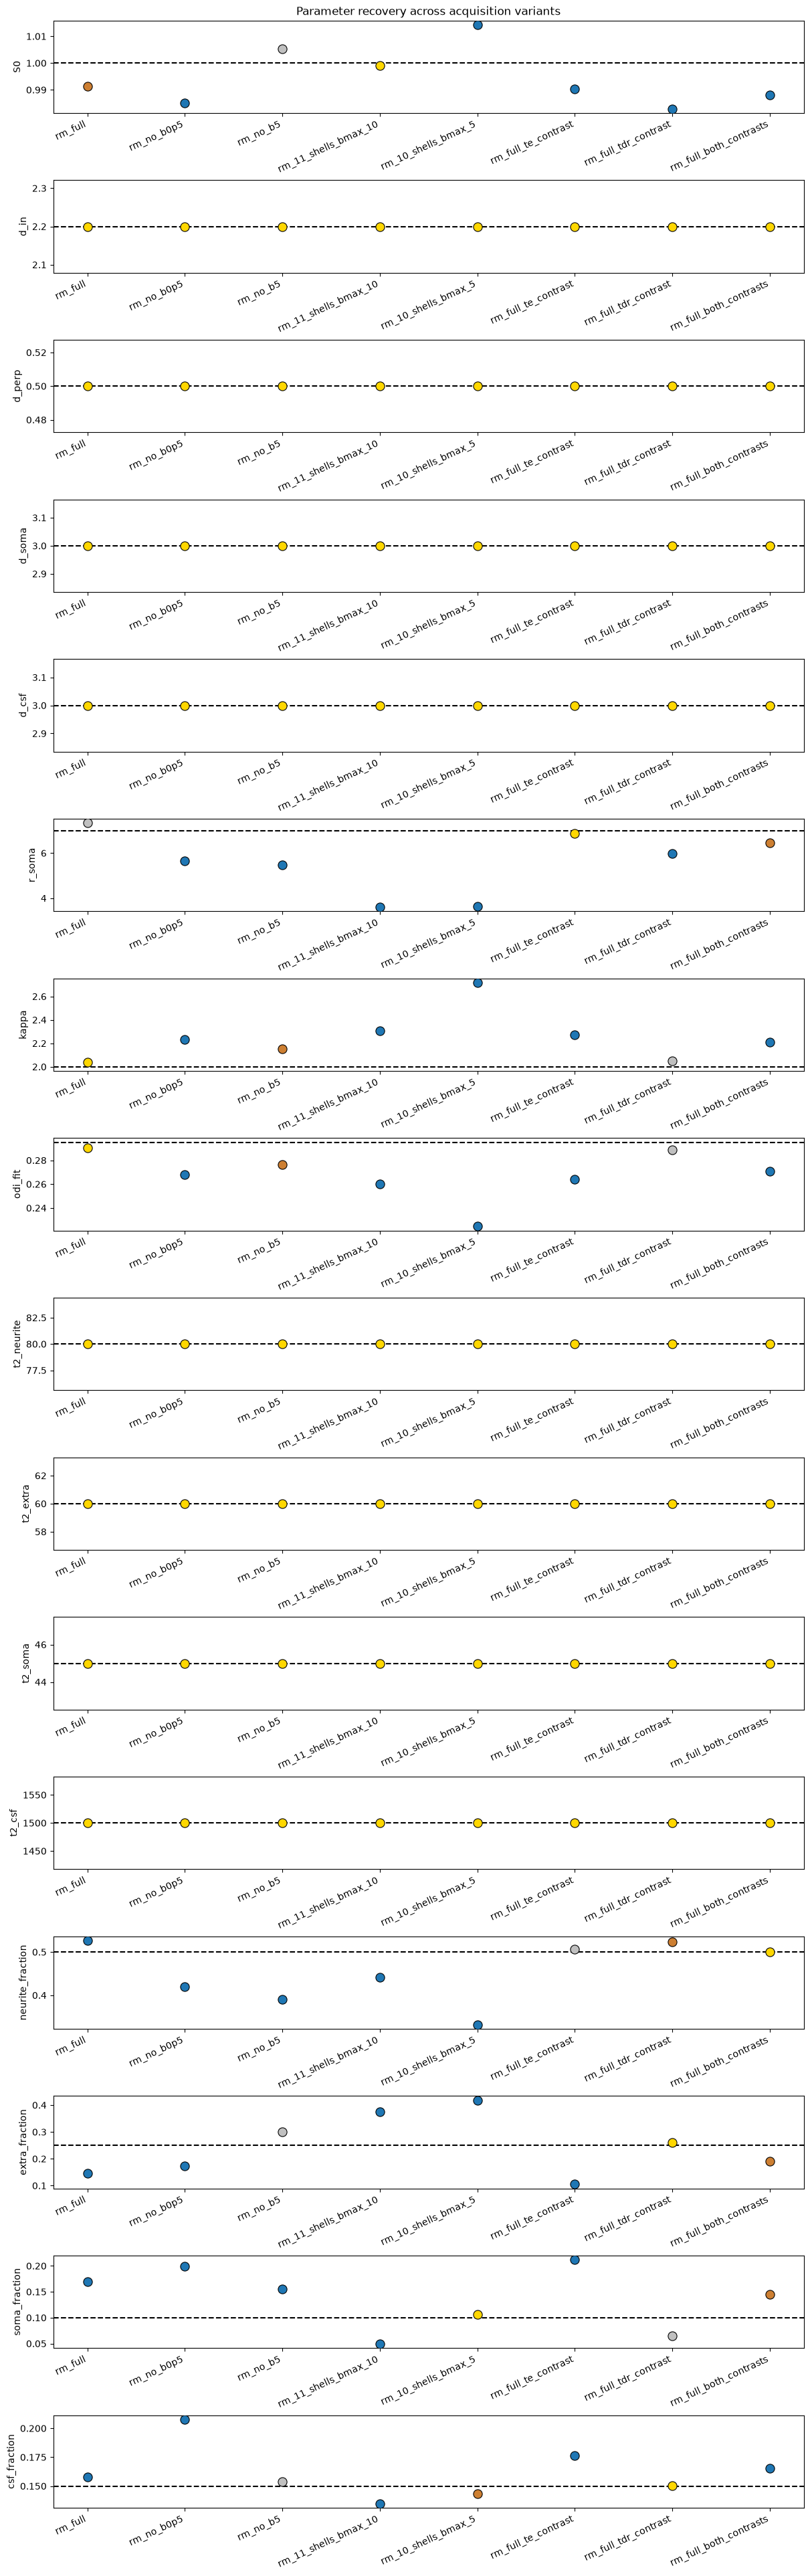

In [57]:
param_names = [
    "S0",
    "d_in",
    "d_perp",
    "d_soma",
    "d_csf",
    "r_soma",
    "kappa",
    "odi_fit",
    "t2_neurite",
    "t2_extra",
    "t2_soma",
    "t2_csf",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
]

truth_lookup = dict(truth_map)
truth_lookup["odi_fit"] = truth_map["odi"]

variants = list(acquisitions.keys())

# Colours for medal ranks
rank_colours = {
    1: "#FFD700",   # gold
    2: "#C0C0C0",   # silver
    3: "#CD7F32",   # bronze
}

fig, axes = plt.subplots(
    len(param_names),
    1,
    figsize=(12, 2.4 * len(param_names)),
    constrained_layout=True,
)

for ax, pname in zip(axes, param_names):

    means = []
    sds = []
    maes = []

    truth = truth_lookup[pname]
    
    for variant in variants:
        sub = ls_df[ls_df["acquisition"] == variant][pname].dropna()

        means.append(sub.mean())
        sds.append(sub.std(ddof=1))
        maes.append(np.mean(np.abs(sub - truth)))

    means = np.asarray(means)
    sds = np.asarray(sds)
    maes = np.asarray(maes)

    valid = np.isfinite(maes)

    ranks = np.full(len(maes), np.nan)
    if np.any(valid):
        ranks[valid] = (
            pd.Series(maes[valid])
            .rank(method="dense", ascending=True)
            .to_numpy()
        )

    x = np.arange(len(variants))

    # Error bars
    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt="none",
        ecolor="0.4",
        capsize=4,
        zorder=1,
    )

    # Scatter points coloured by MAE rank
    for xi, yi, rank in zip(x, means, ranks):
        colour = rank_colours.get(int(rank), "tab:blue") if np.isfinite(rank) else "tab:blue"
        ax.scatter(
            xi,
            yi,
            s=90,
            color=colour,
            edgecolor="black",
            linewidth=0.8,
            zorder=3,
        )

    ax.axhline(
        truth,
        linestyle="--",
        linewidth=1.5,
        color="black",
        label="Truth",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(variants, rotation=25, ha="right")
    ax.set_ylabel(pname)

axes[0].set_title("Parameter recovery across acquisition variants")
plt.show()

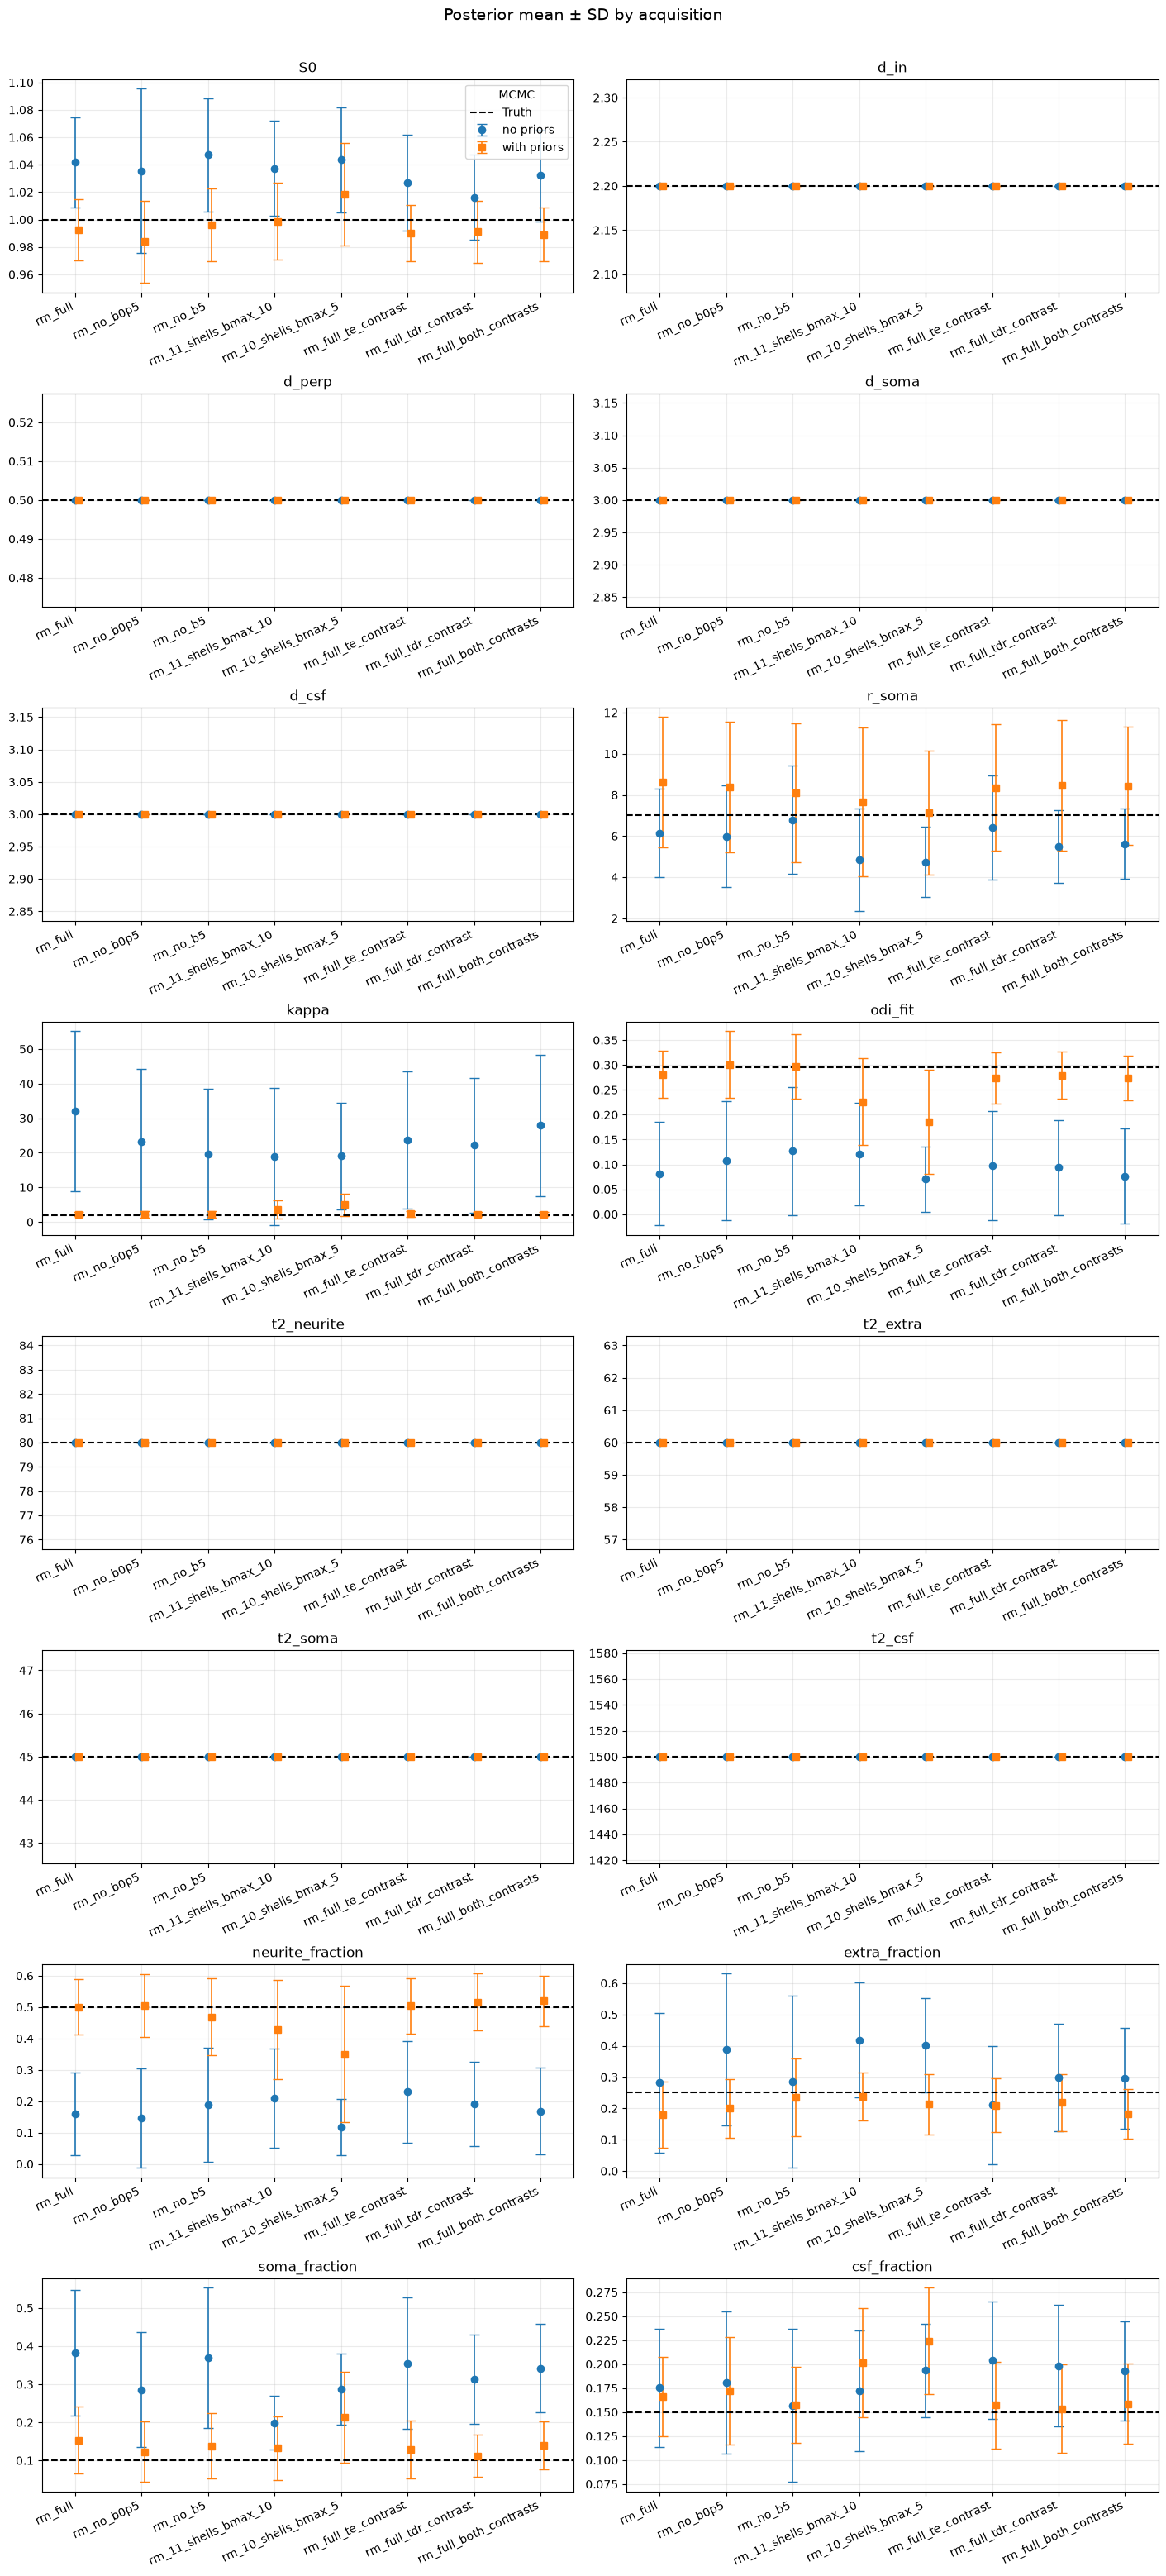

In [58]:
def summarize_acq_mcmc(df, label, param_names, truth_lookup):
    rows = []
    for acq in df["acquisition"].unique():
        sub = df[df["acquisition"] == acq]
        for p in param_names:
            if p not in sub.columns:
                continue
            sd_col = f"{p}_post_sd"
            rows.append({
                "acquisition": acq,
                "parameter": p,
                "condition": label,
                "mean": sub[p].mean(),
                "sd": sub[sd_col].mean() if sd_col in sub.columns else np.nan,
                "truth": truth_lookup.get(p, np.nan),
            })
    return pd.DataFrame(rows)

none_sum = summarize_acq_mcmc(mcmc_none_df, "no priors", param_names, truth_lookup)

if mcmc_prior_df is not None and not mcmc_prior_df.empty:
    prior_sum = summarize_acq_mcmc(mcmc_prior_df, "with priors", param_names, truth_lookup)
    plot_df = pd.concat([none_sum, prior_sum], ignore_index=True)
else:
    plot_df = none_sum.copy()

acq_order = list(acquisitions.keys())
plot_df["acquisition"] = pd.Categorical(
    plot_df["acquisition"], categories=acq_order, ordered=True
)

fig_params = [p for p in param_names if p in plot_df["parameter"].unique()]
ncols = 2
nrows = int(np.ceil(len(fig_params) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 3.8 * nrows), constrained_layout=True
)
axes = np.array(axes).reshape(-1)

markers = {
    "no priors": "o",
    "with priors": "s",
}

colours = {
    "no priors": "tab:blue",
    "with priors": "tab:orange",
}

offsets = {
    "no priors": 0.0,
    "with priors": 0.05,
}

for ax, p in zip(axes, fig_params):
    sub = plot_df[plot_df["parameter"] == p].sort_values("acquisition")
    x = np.arange(len(acq_order))

    for cond, group in sub.groupby("condition"):
        group = group.set_index("acquisition").reindex(acq_order)
        x_plot = x + offsets.get(cond, 0.0)

        ax.errorbar(
            x_plot,
            group["mean"].to_numpy(),
            yerr=group["sd"].to_numpy(),
            fmt=markers.get(cond, "o"),
            color=colours.get(cond, "tab:blue"),
            capsize=4,
            linewidth=1.2,
            label=cond,
        )

    truth = sub["truth"].iloc[0]
    ax.axhline(
        truth,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Truth",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(acq_order, rotation=25, ha="right")
    ax.set_xlim(-0.5, len(acq_order) - 0.5)
    ax.set_title(p)
    ax.grid(True, alpha=0.25)

for ax in axes[len(fig_params):]:
    ax.axis("off")

axes[0].legend(title="MCMC")
fig.suptitle("Posterior mean ± SD by acquisition", y=1.02, fontsize=14)
plt.show()

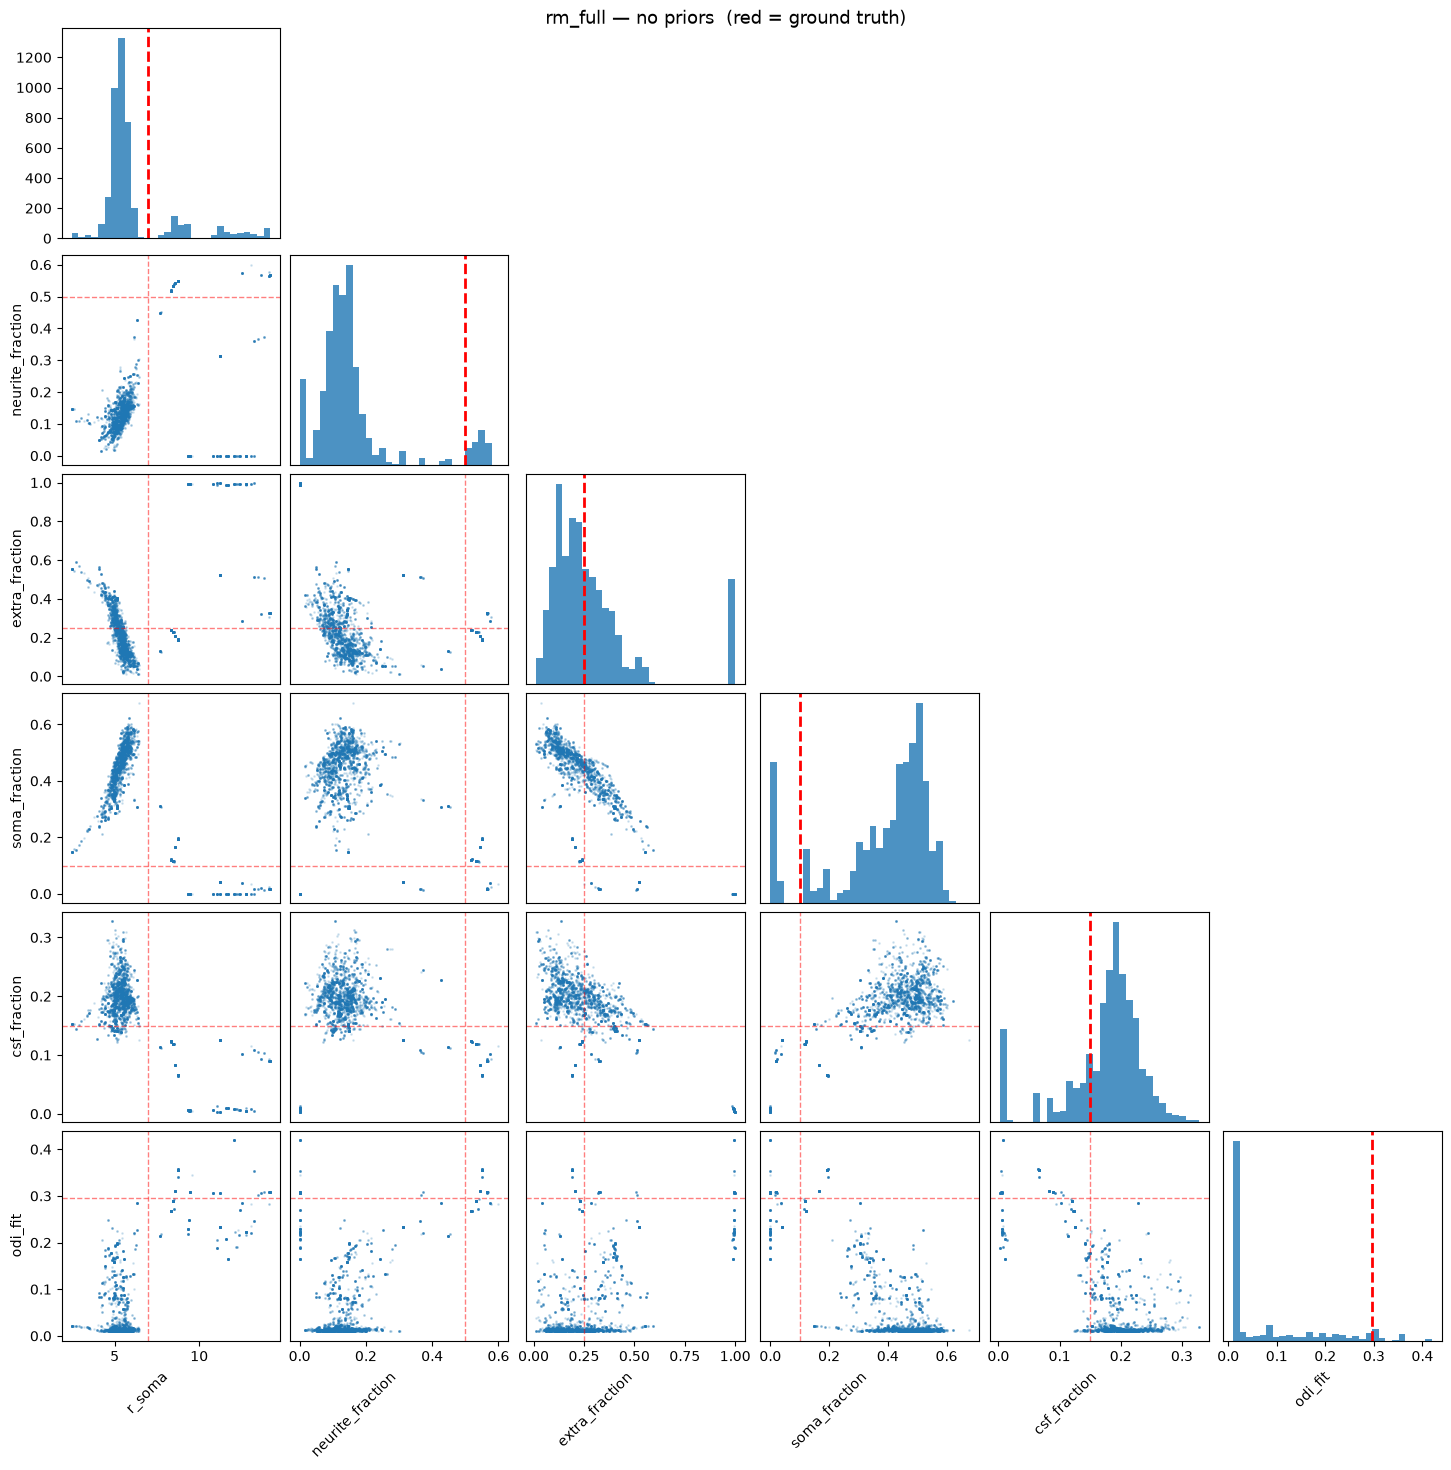

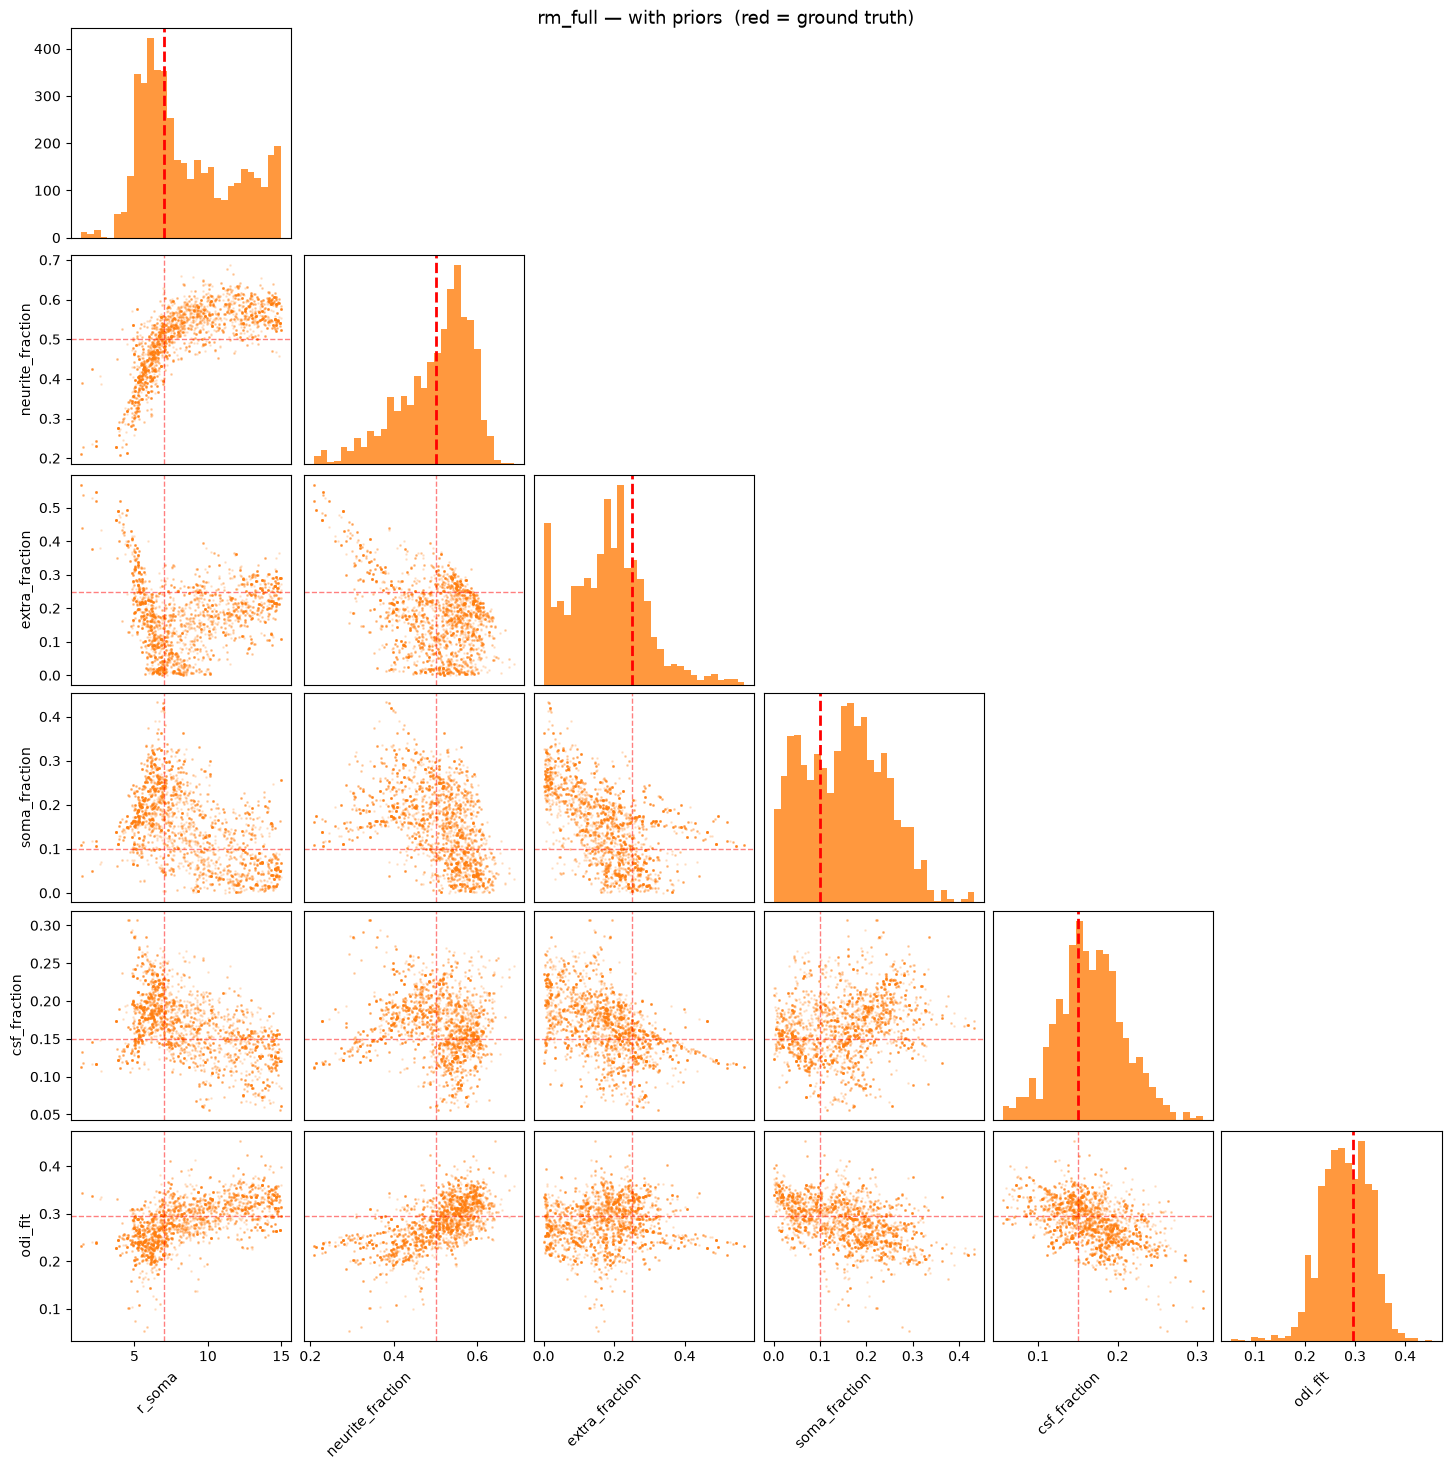

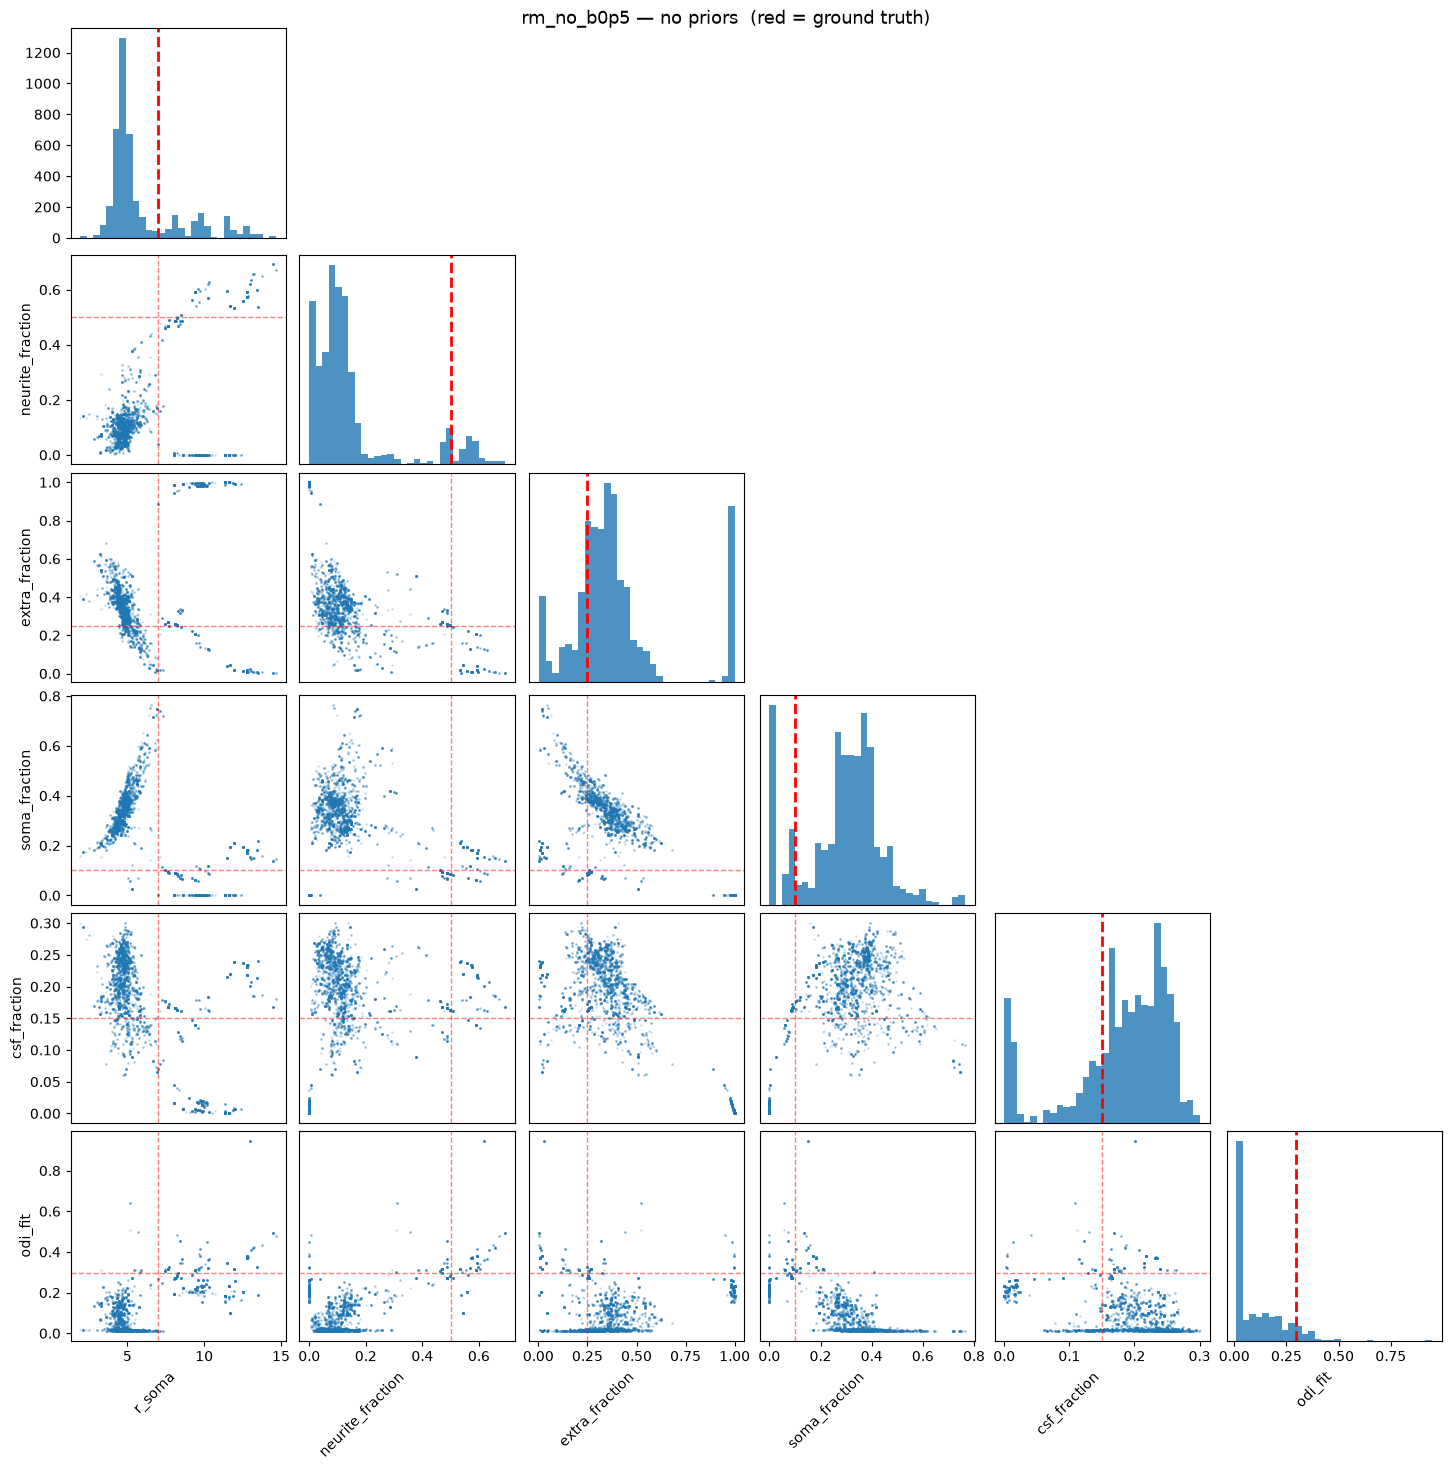

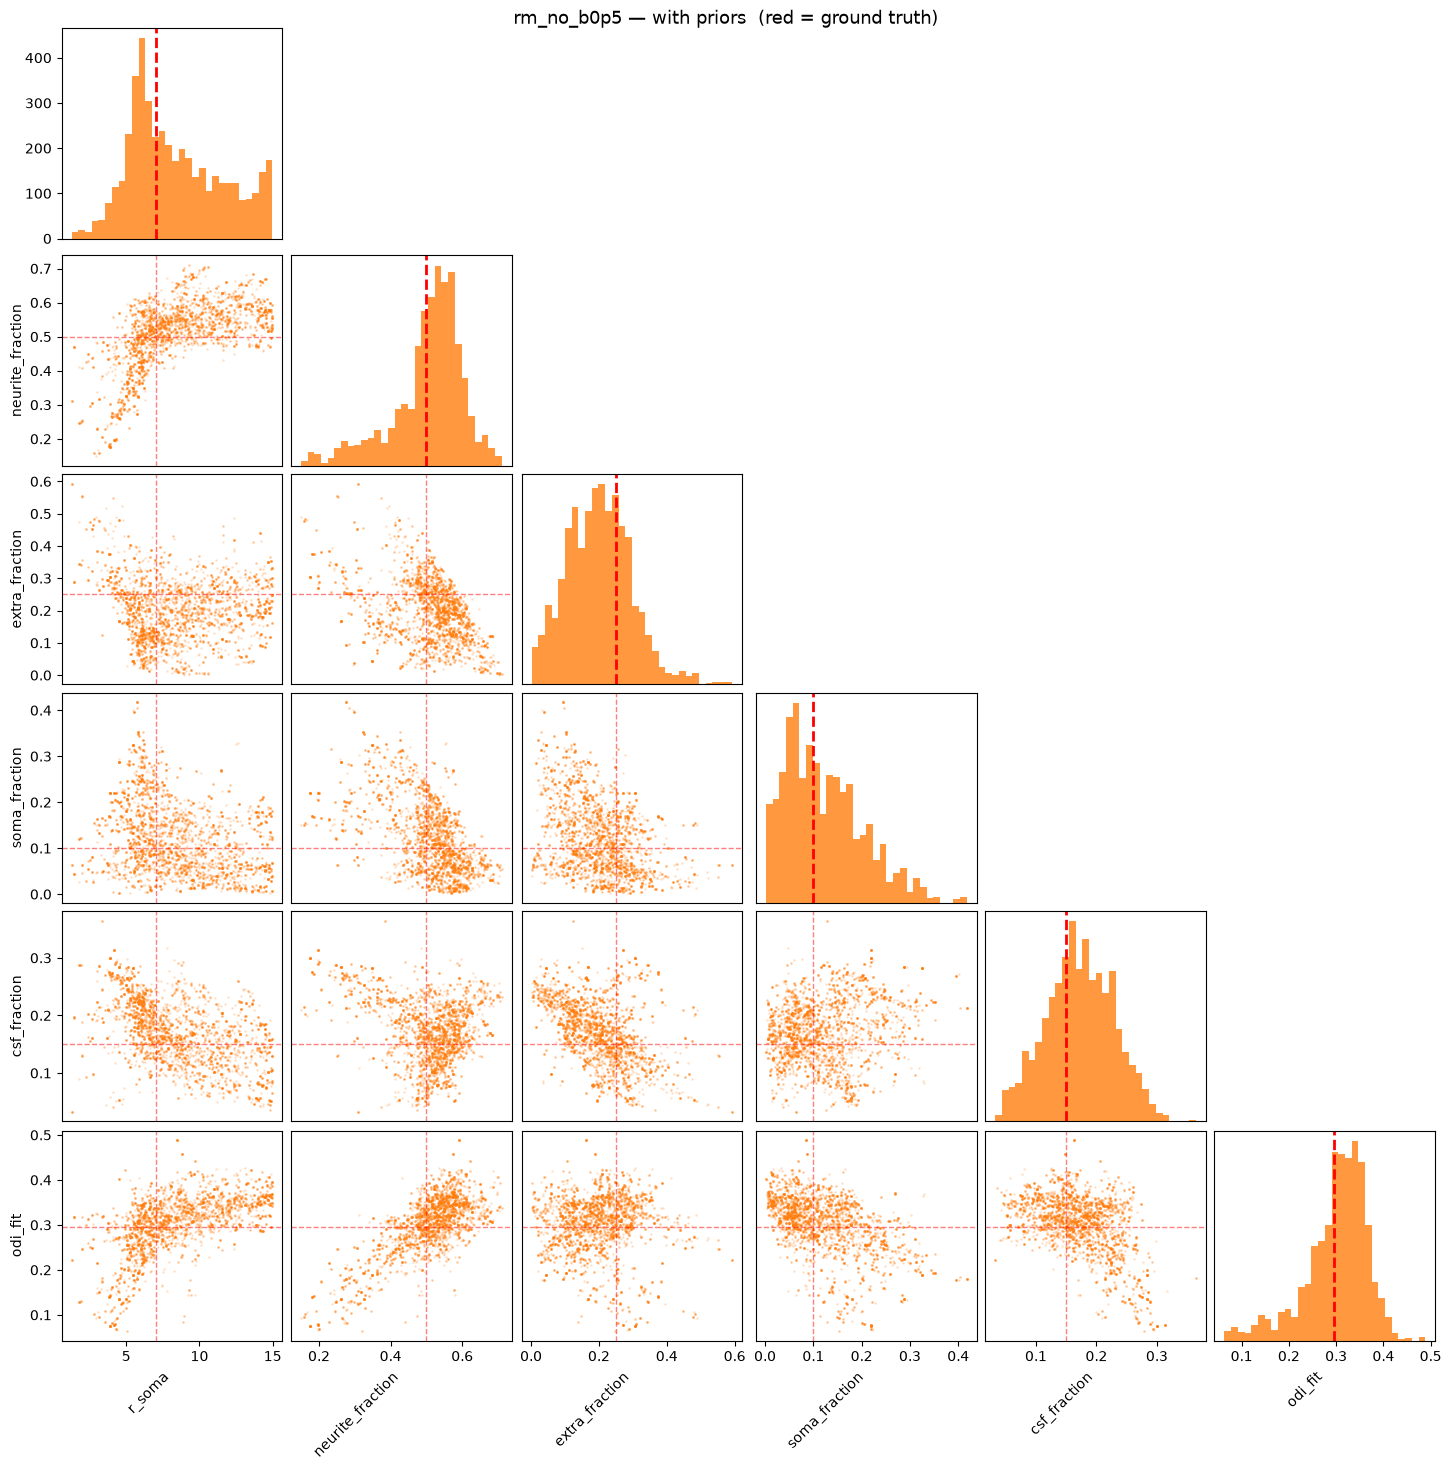

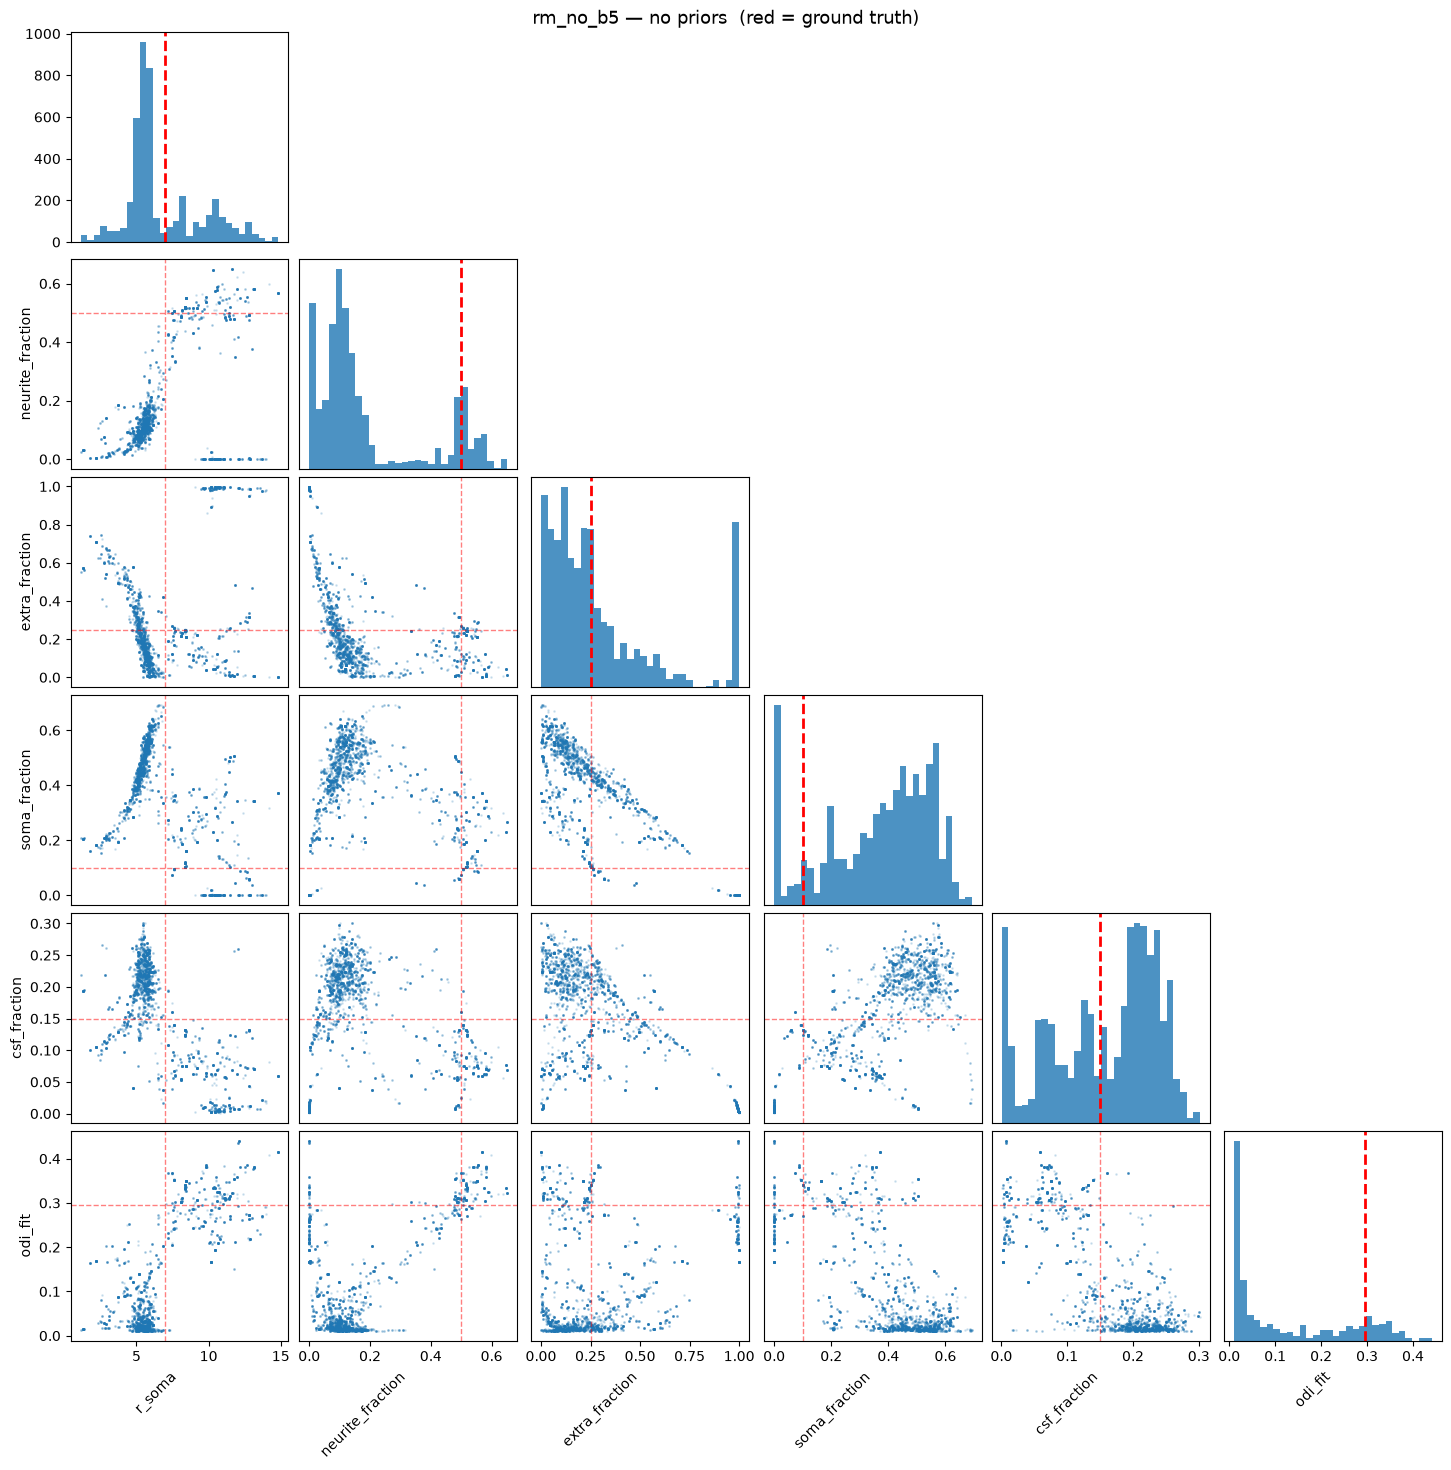

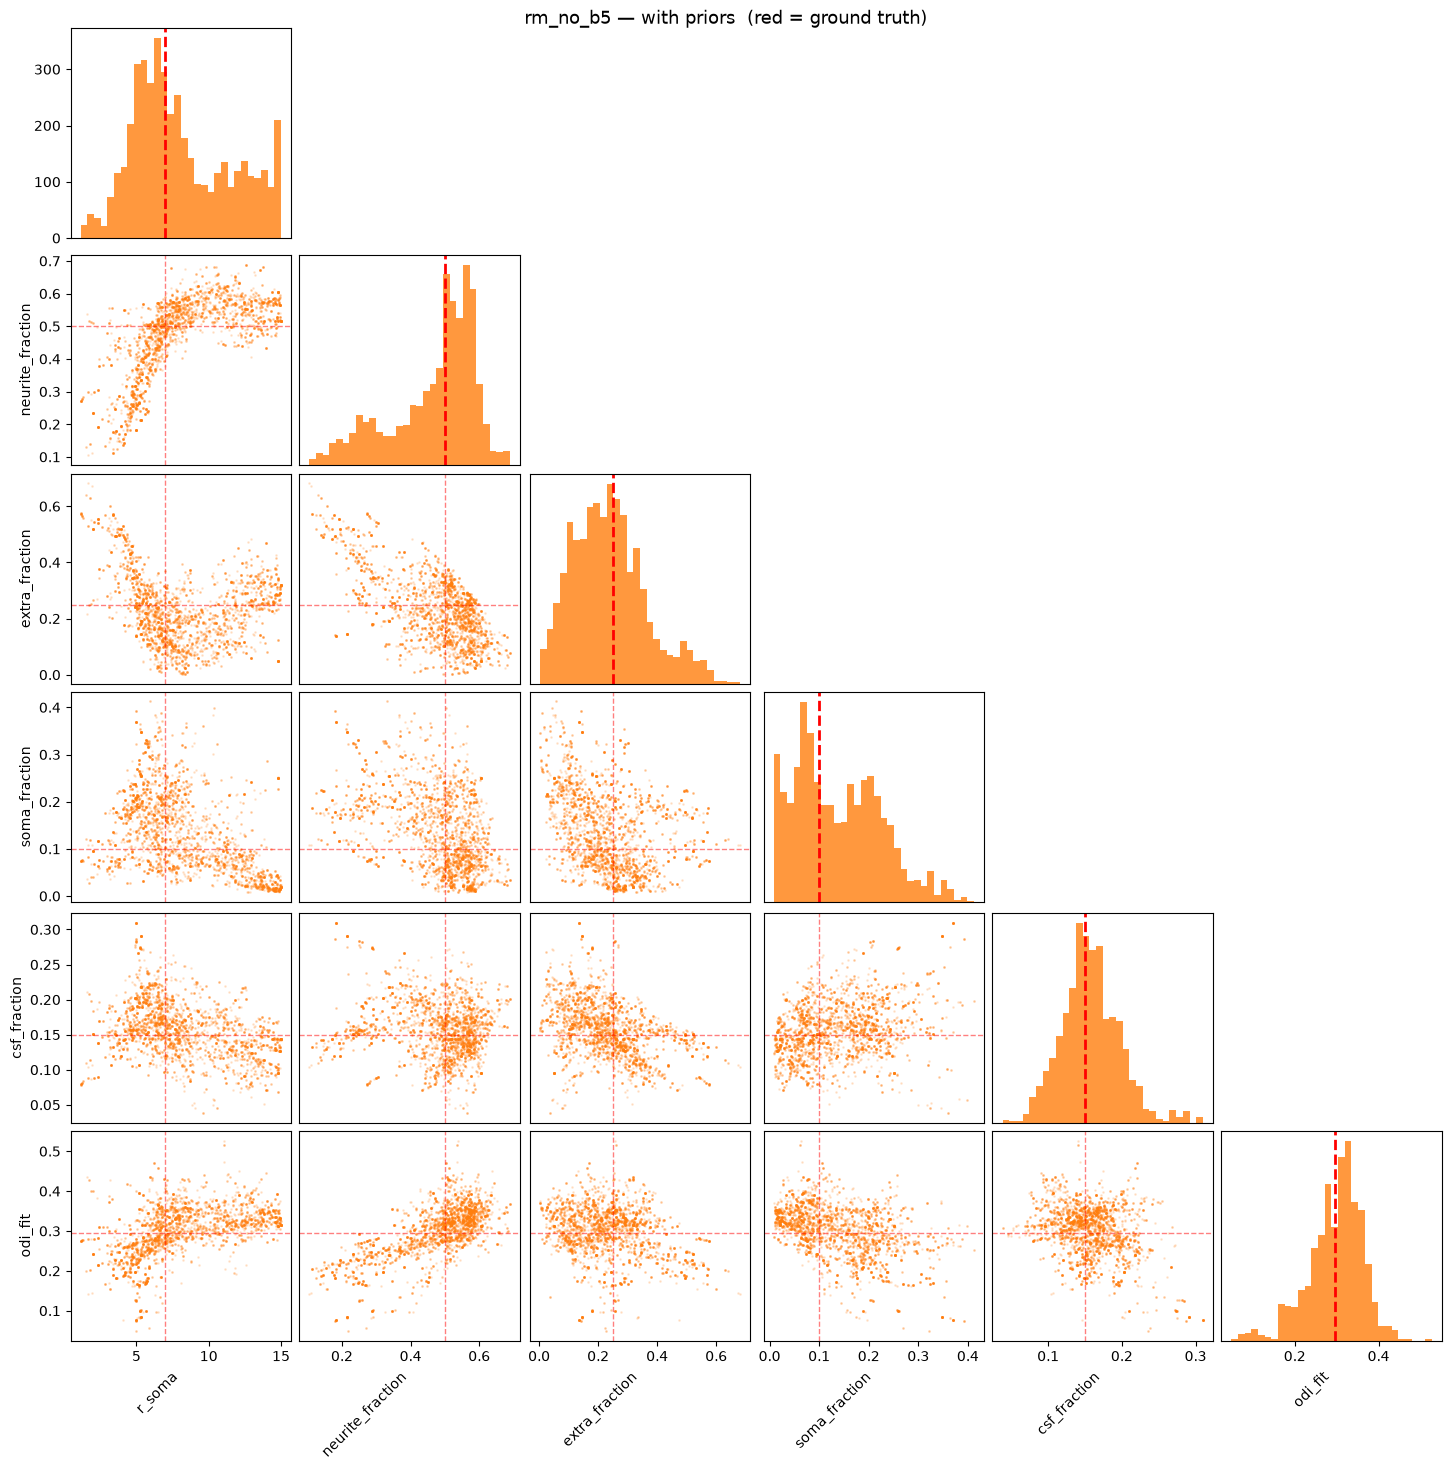

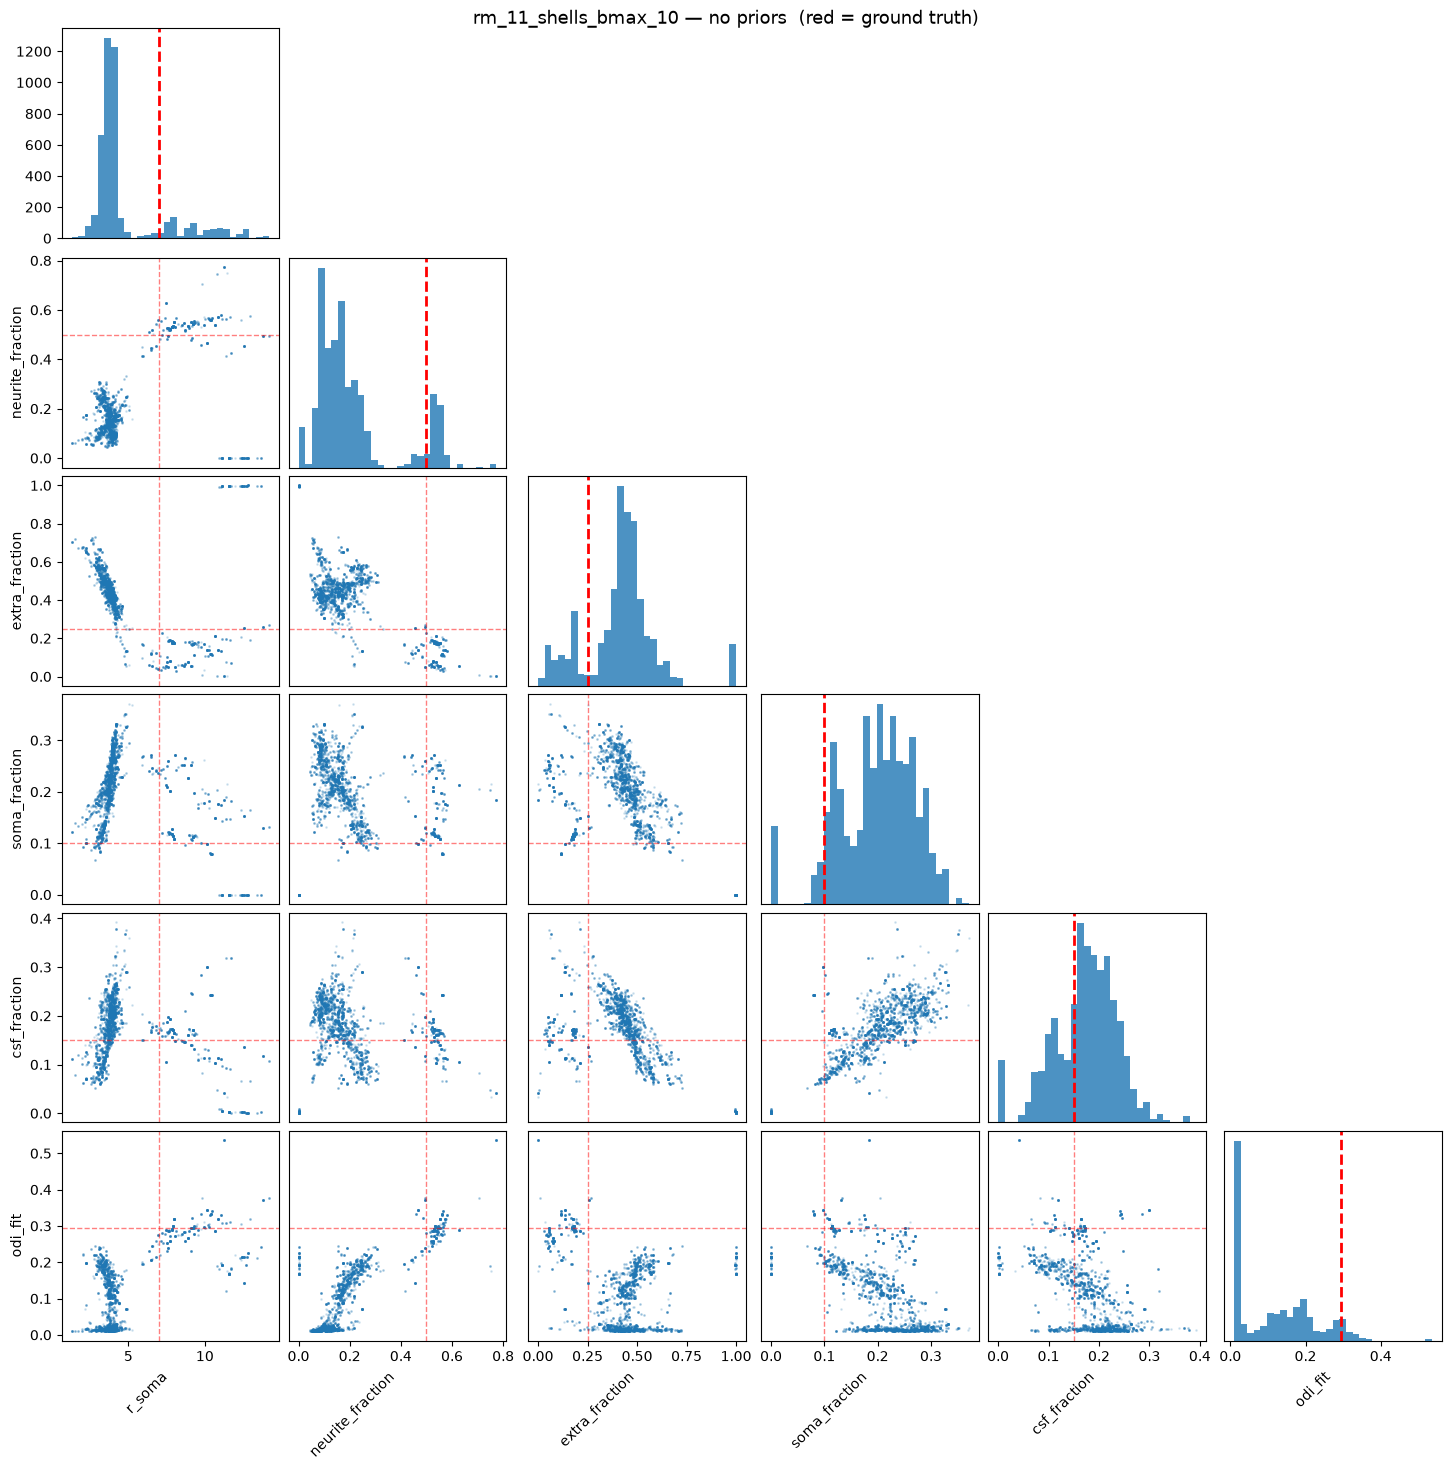

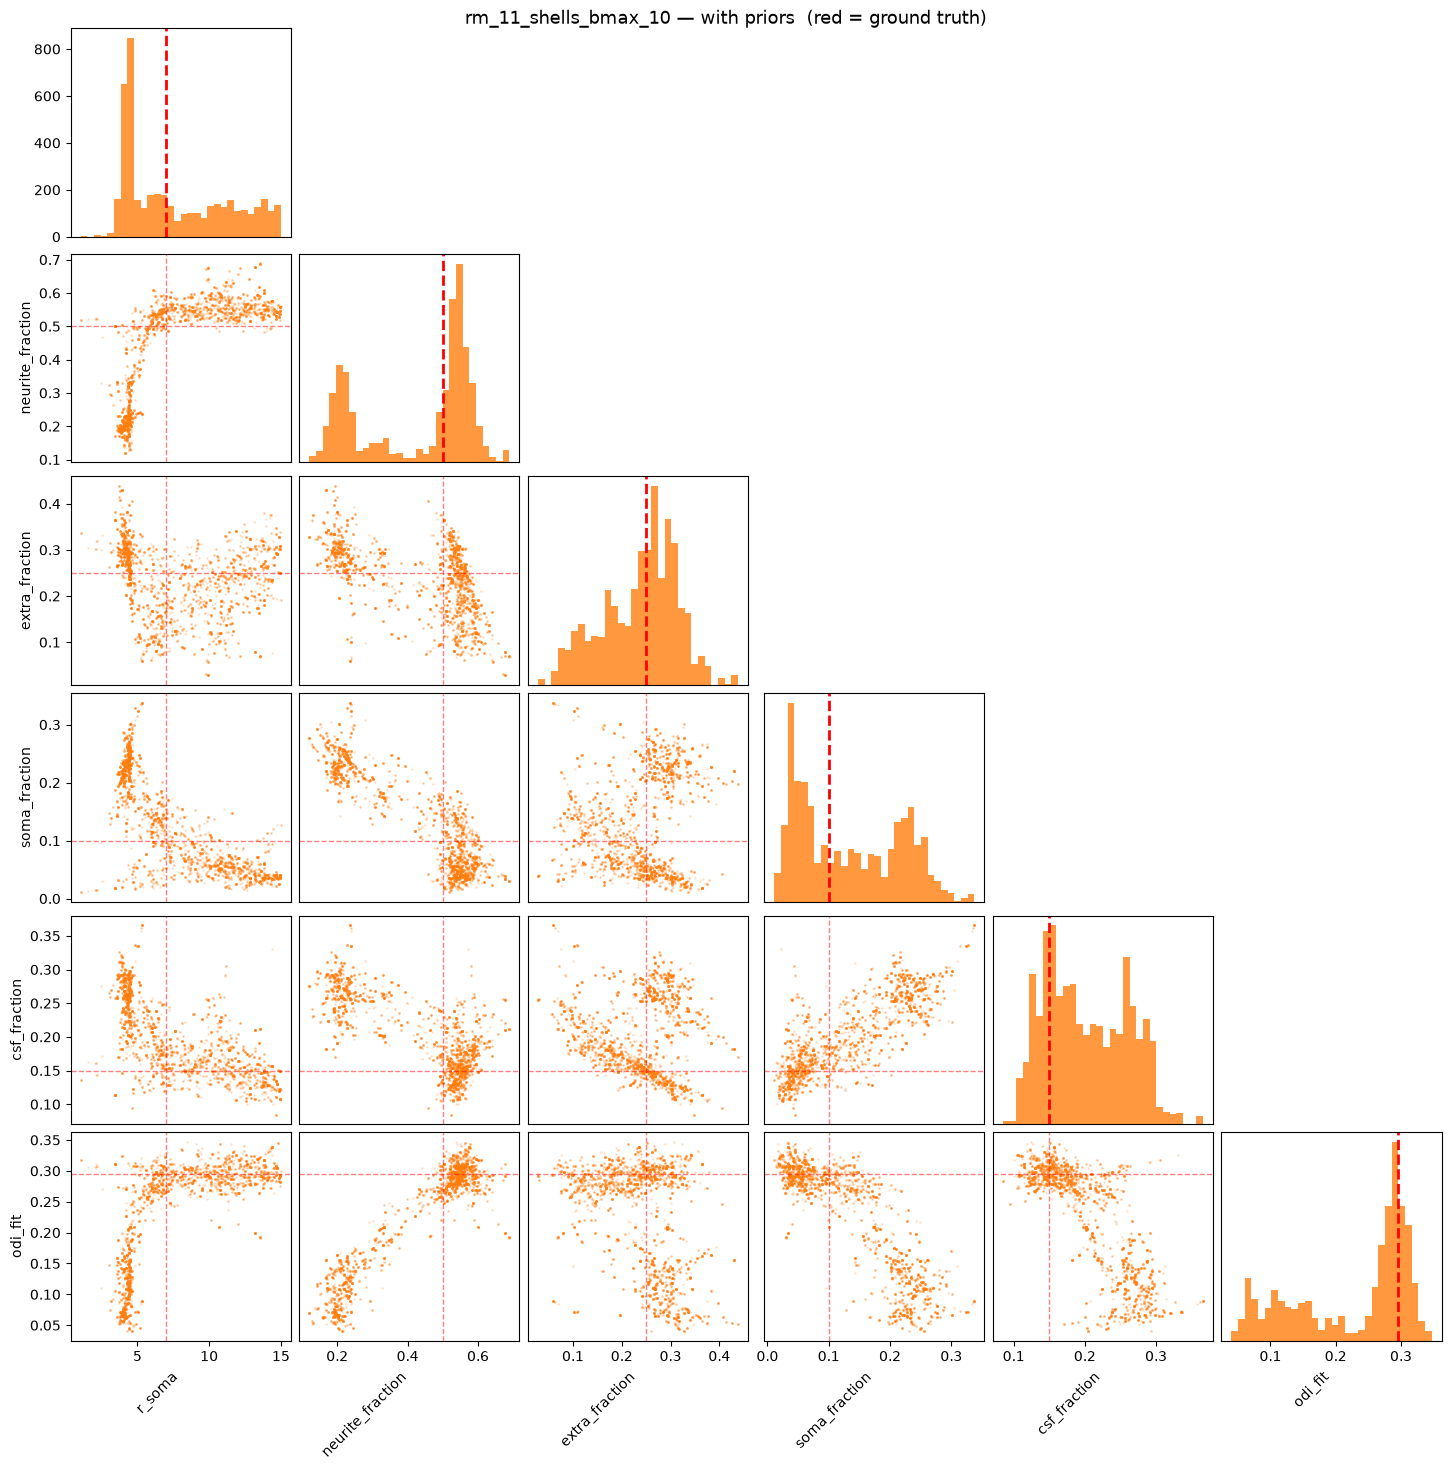

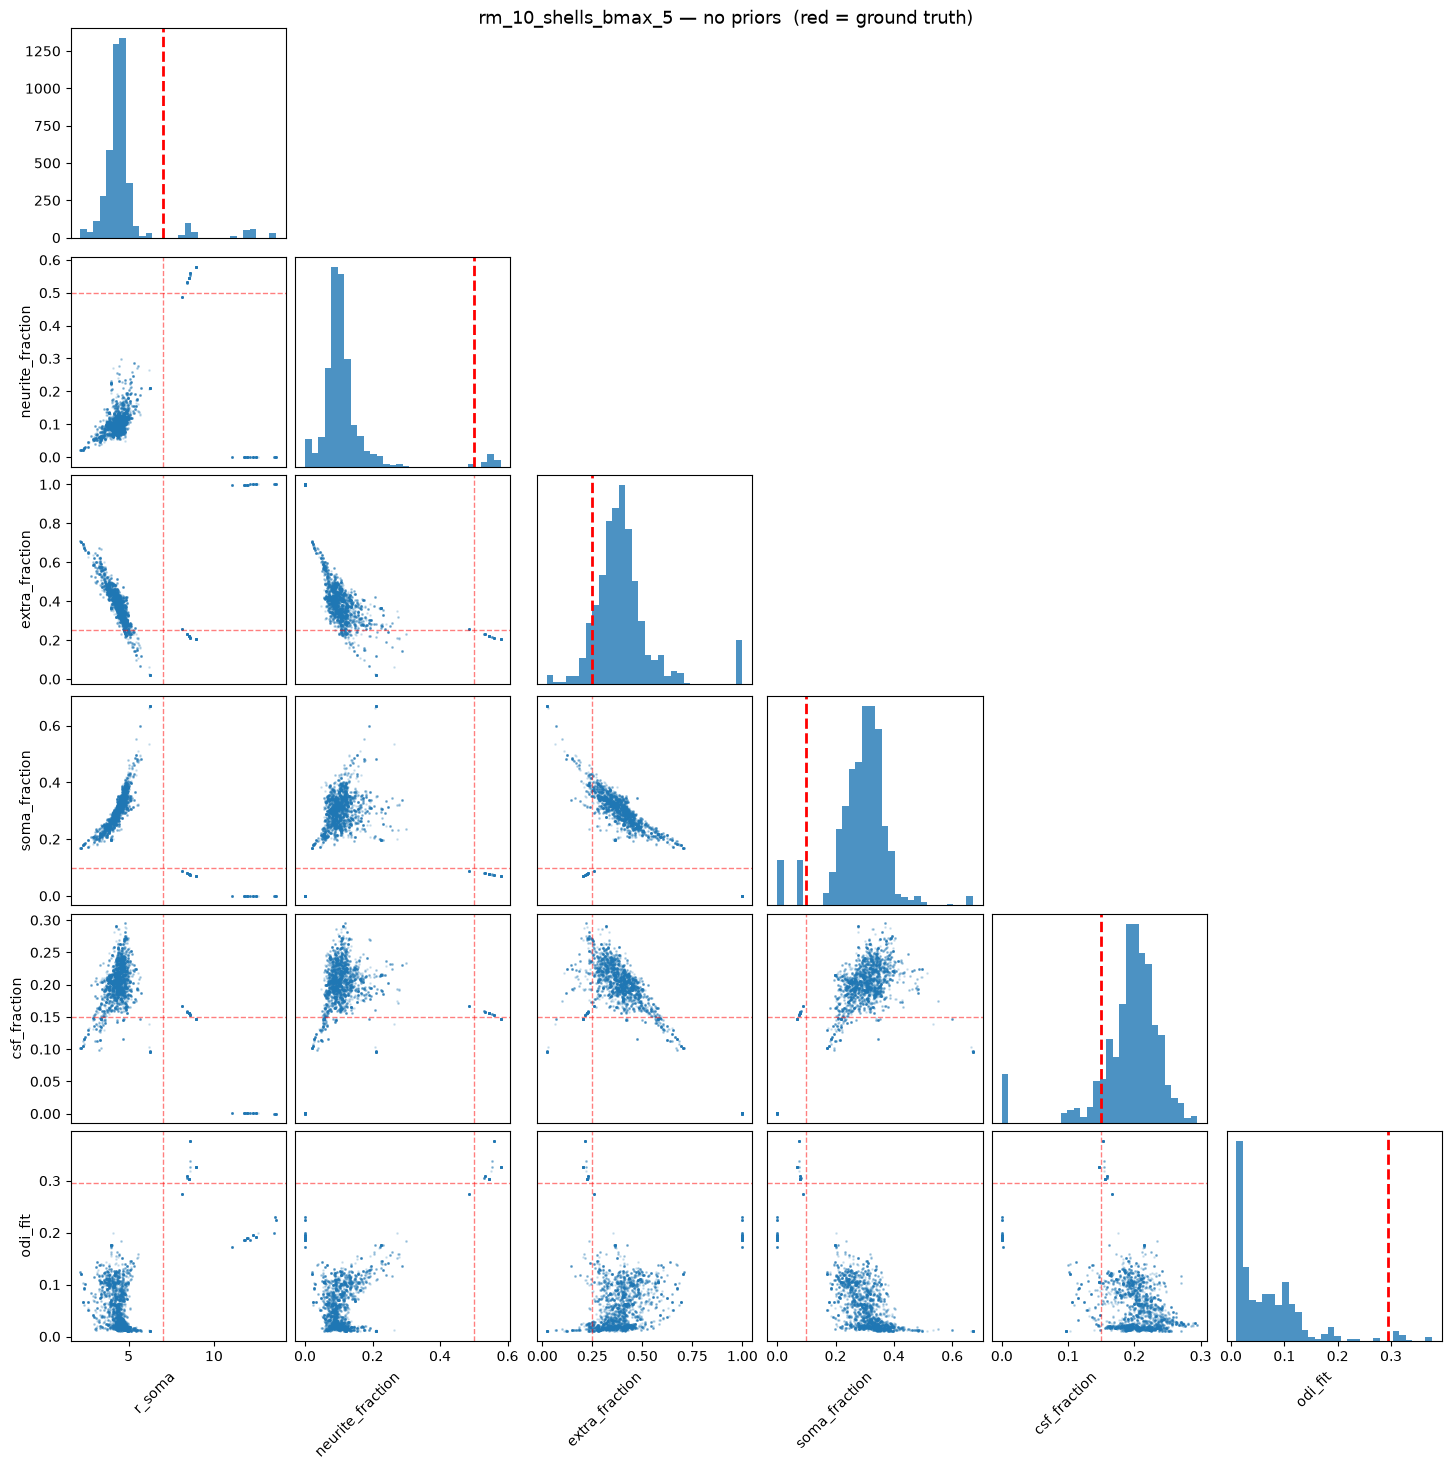

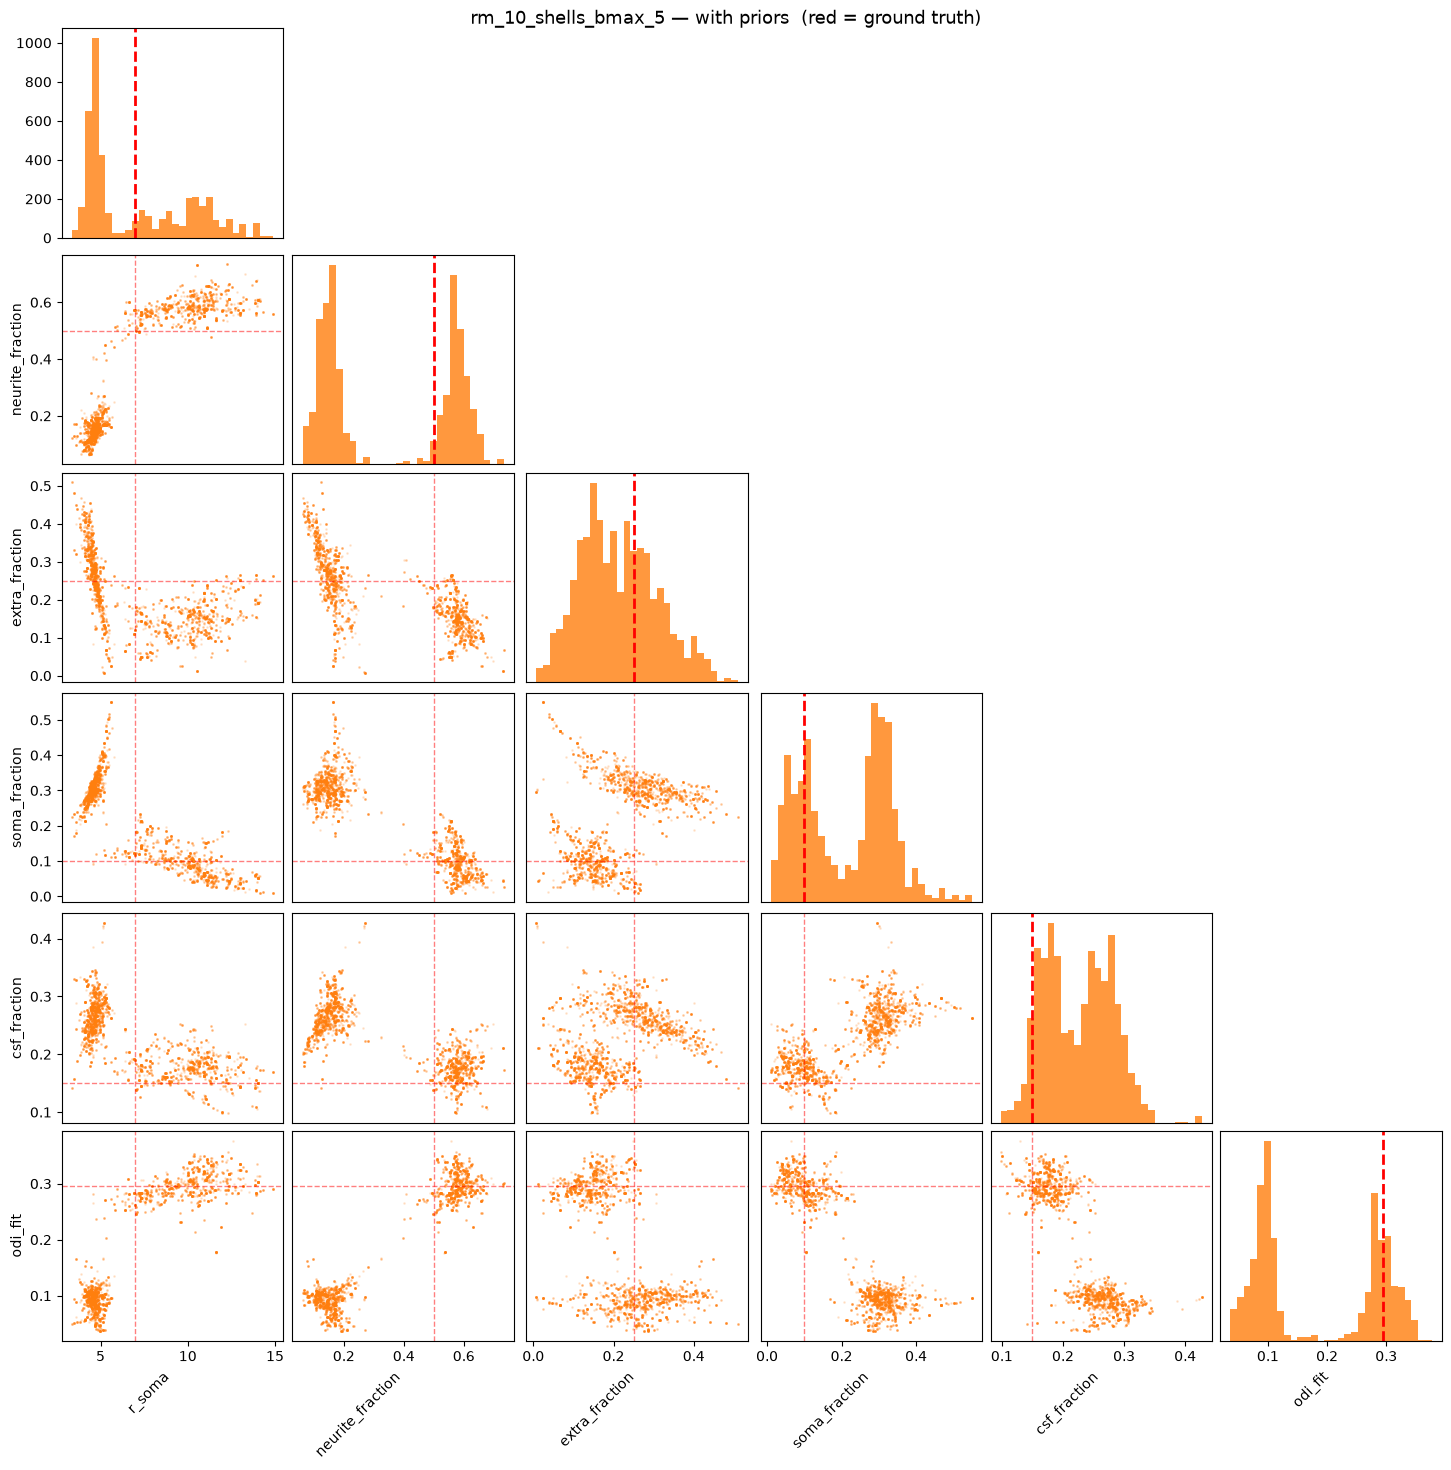

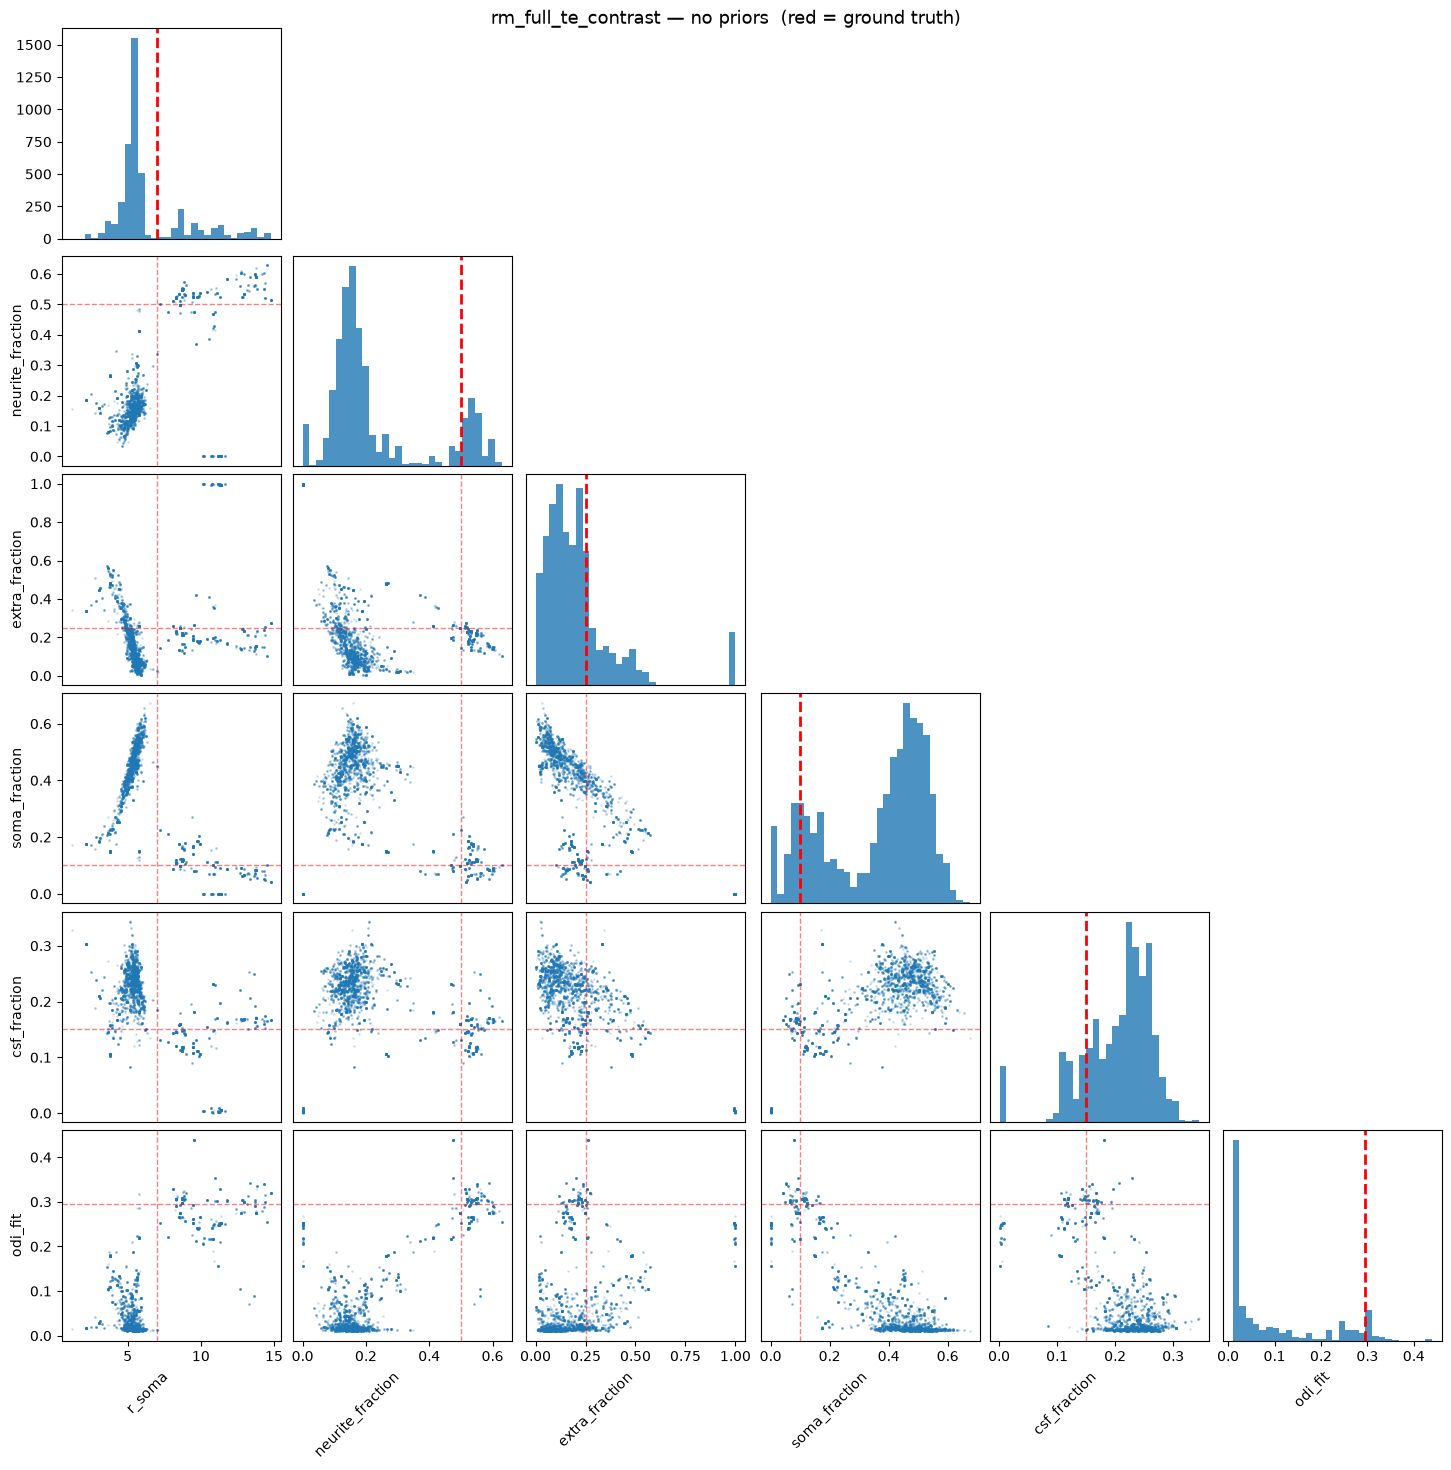

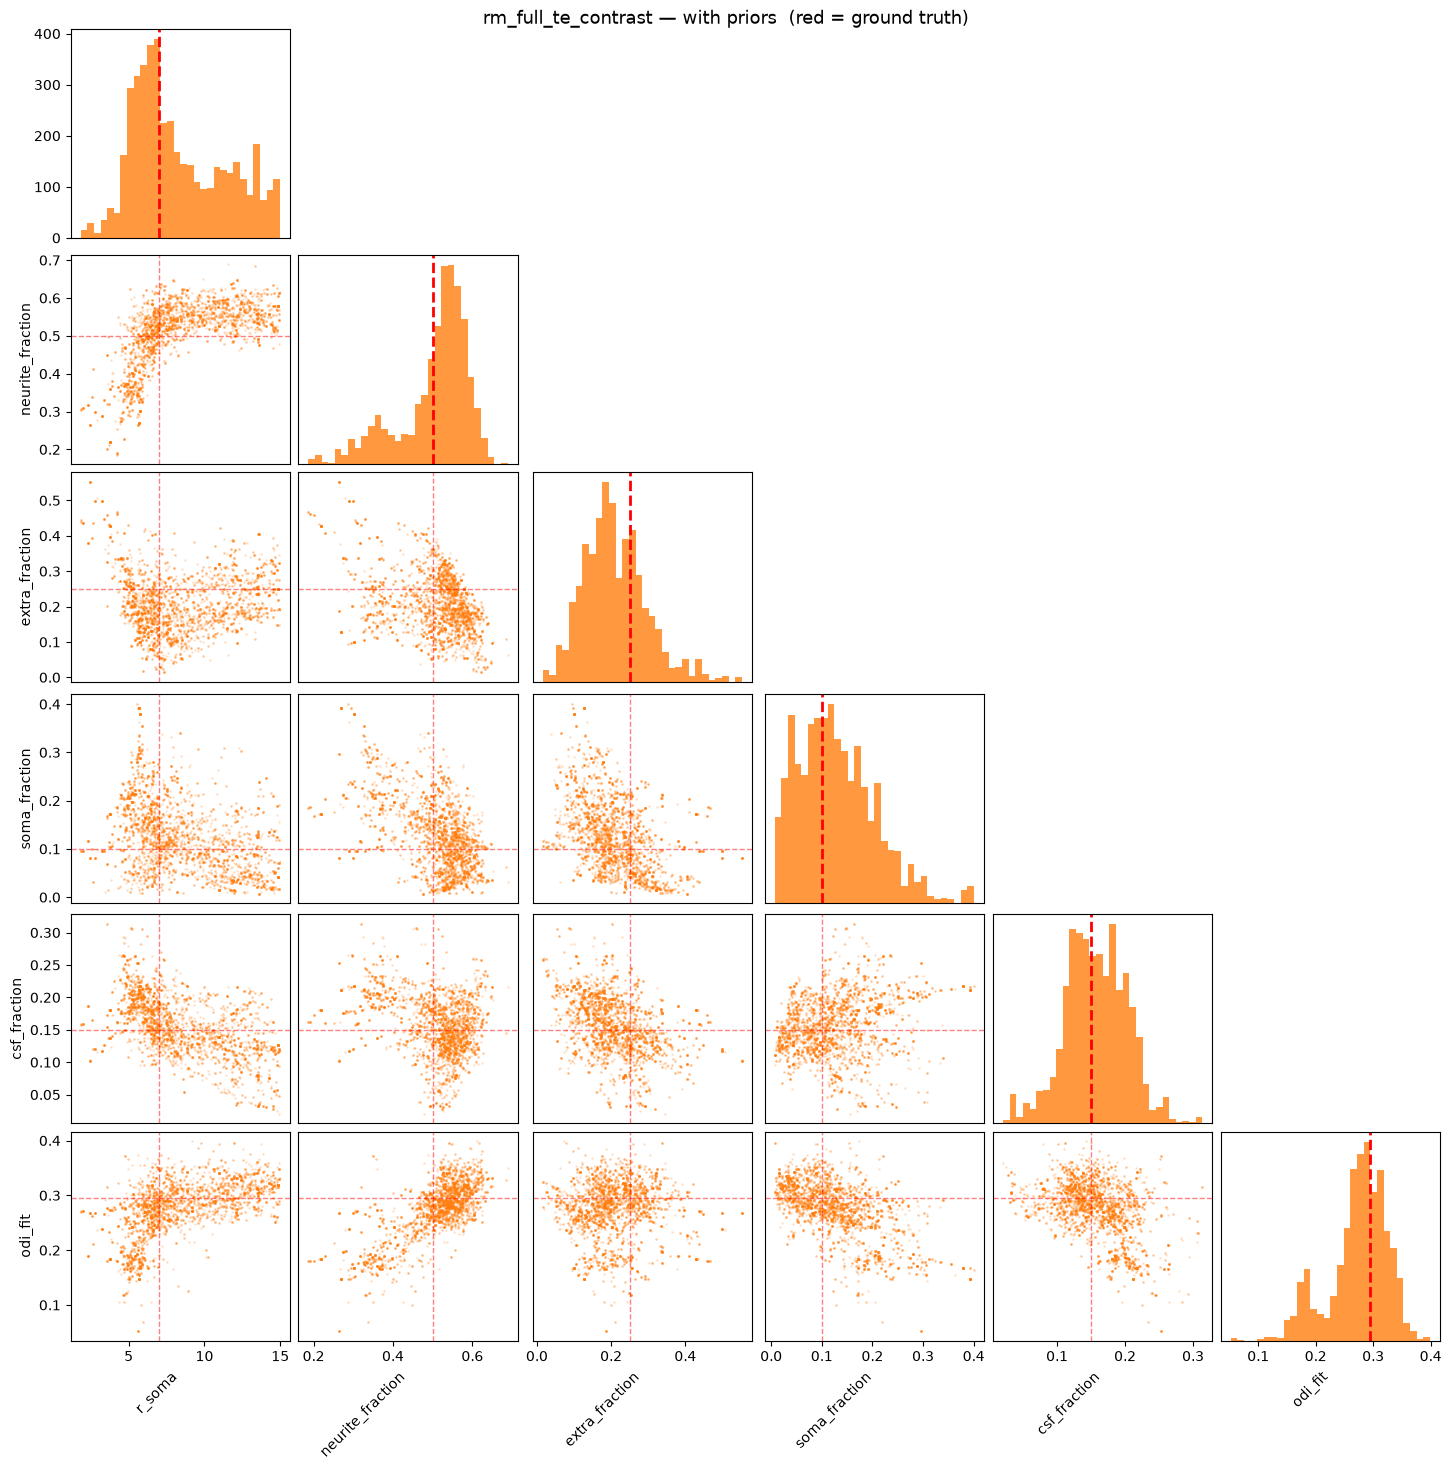

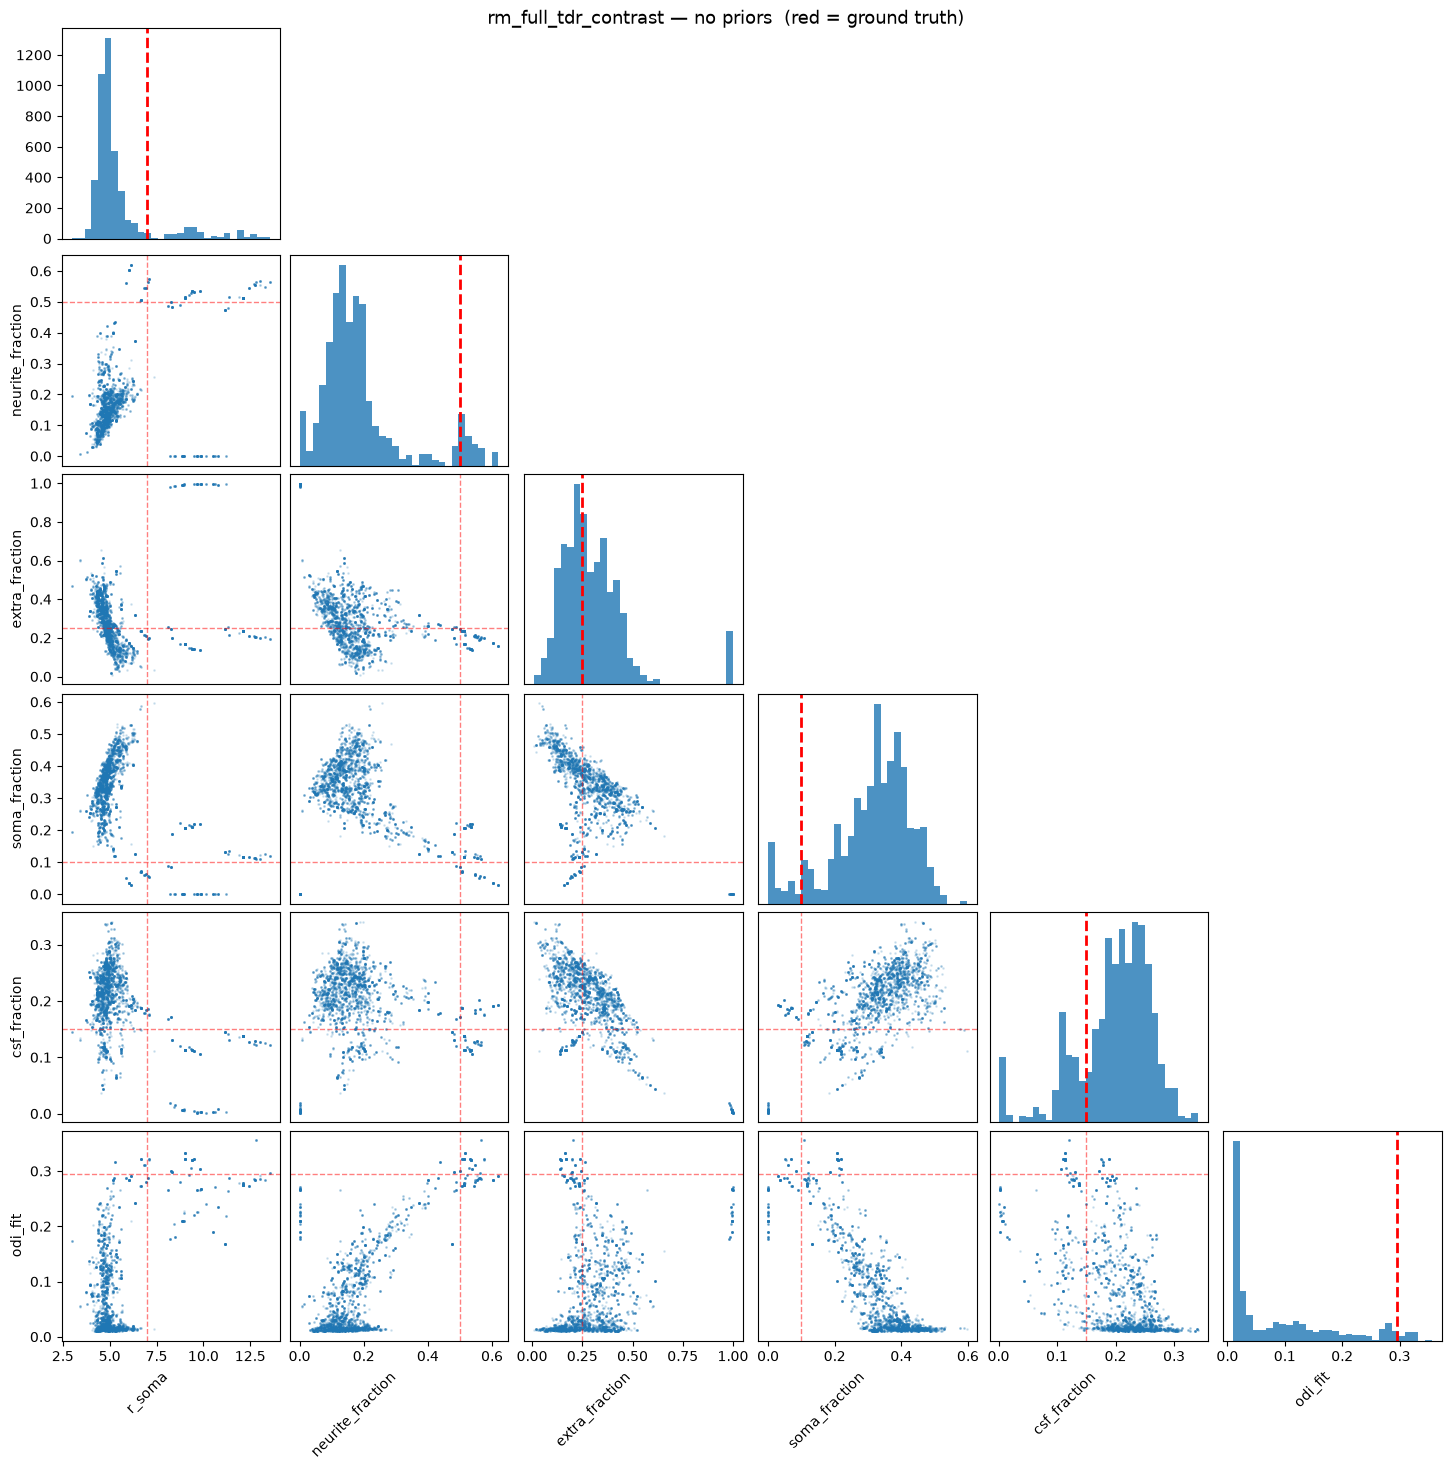

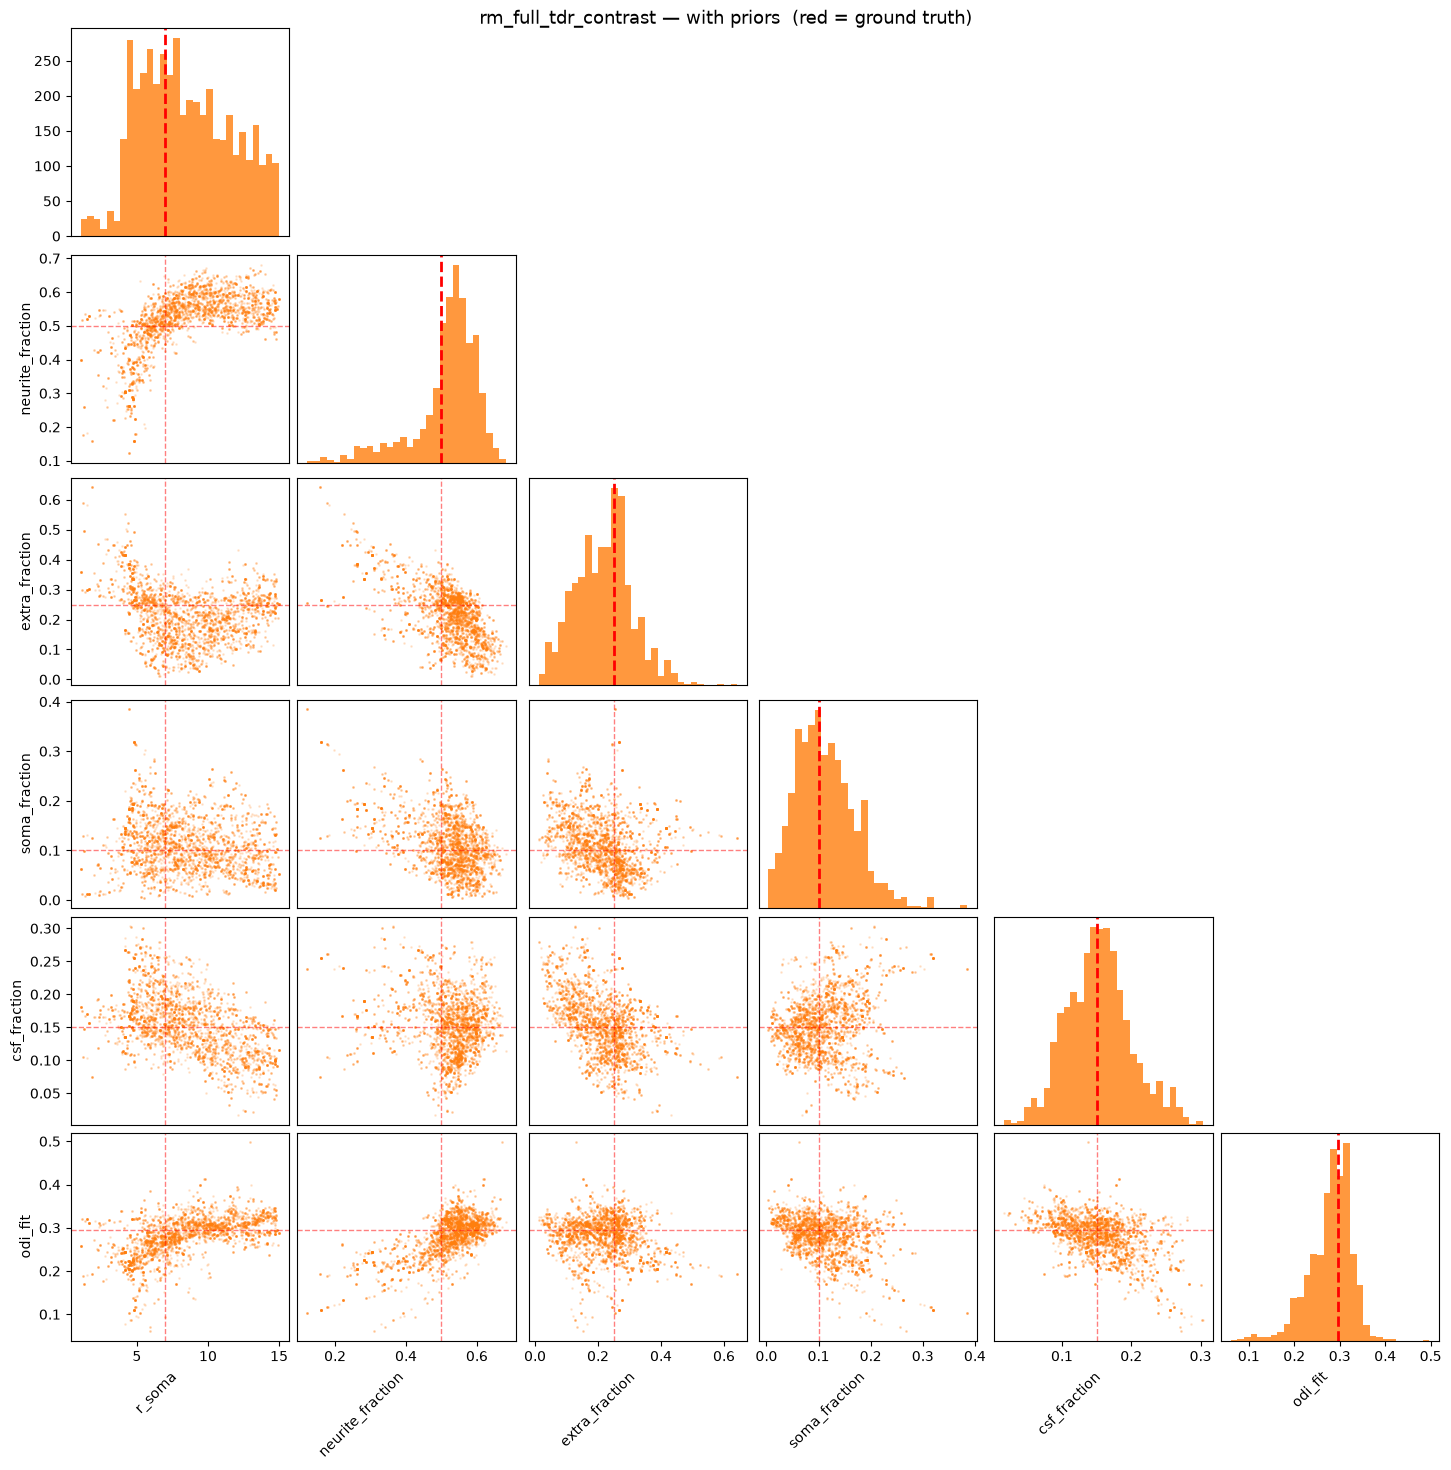

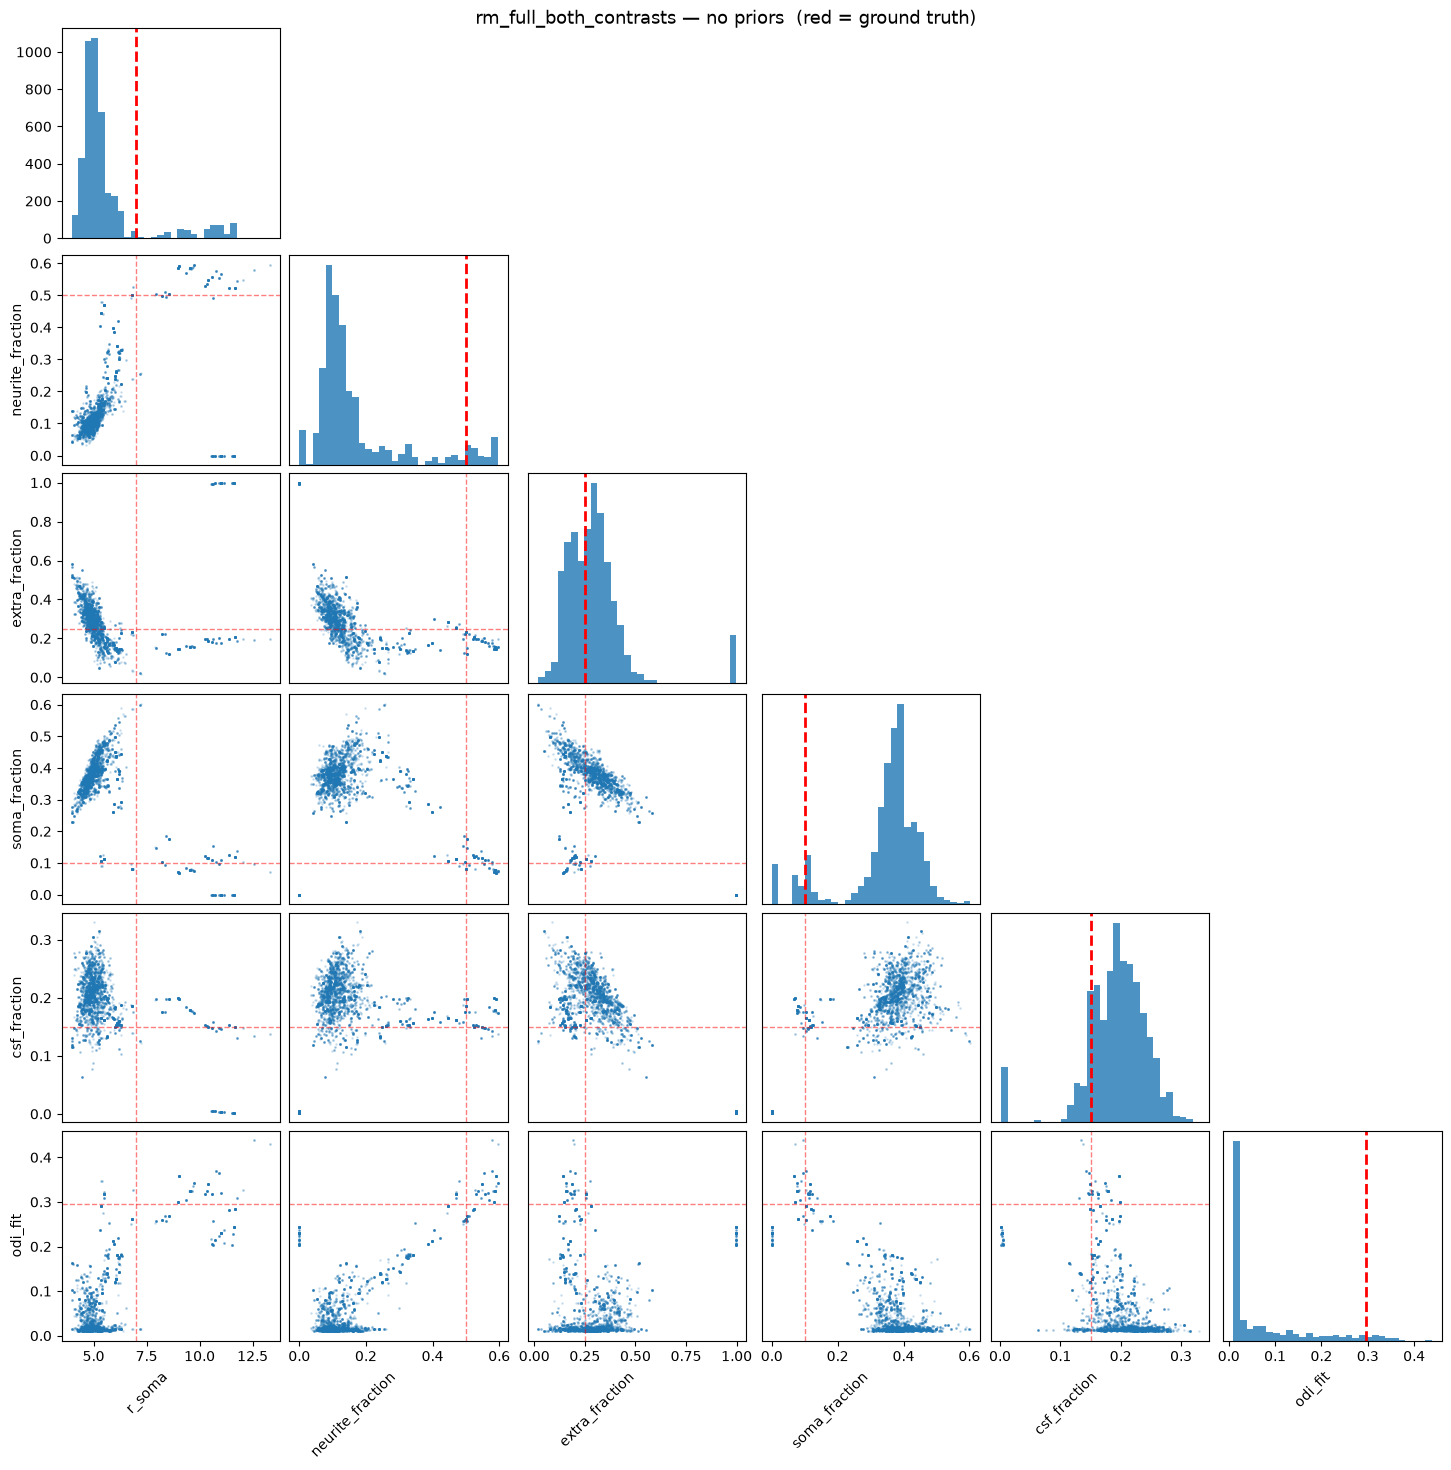

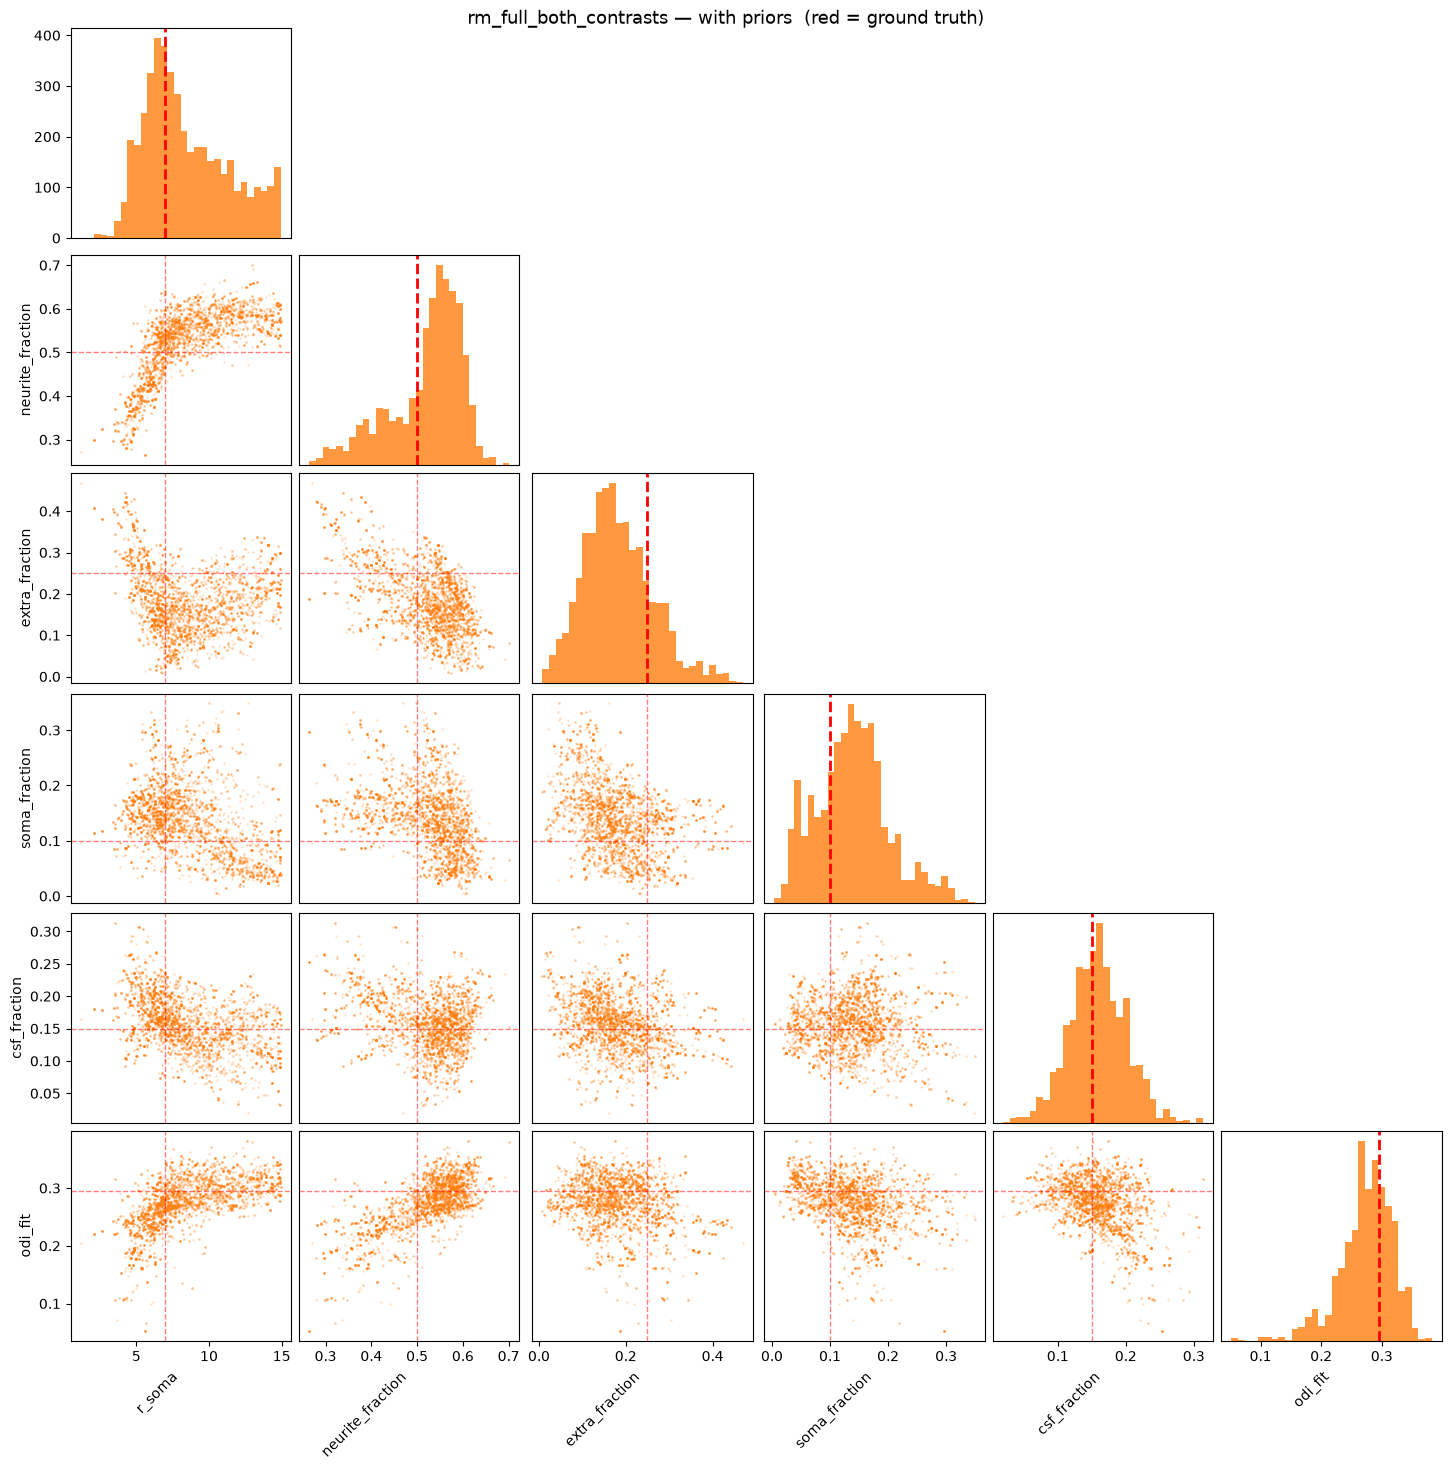

In [59]:
plot_params = [
    "r_soma",
    # "d_soma",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
    "odi_fit",
]

def safe_odi_array(kappa_vals):
    kappa_vals = np.asarray(kappa_vals, dtype=float)
    out = np.full(kappa_vals.shape, np.nan, dtype=float)
    ok = np.isfinite(kappa_vals) & (kappa_vals >= 0)
    out[ok] = np.array([odi_from_kappa(k) for k in kappa_vals[ok]])
    return out

def pair_plot_mcmc(mcmc_result, true_parameters, plot_params, title, color="tab:blue", save_path=None):
    s = mcmc_result.physical_samples(flat=True)

    selected = []
    samples = {}

    for p in plot_params:
        if p == "odi_fit":
            if "kappa" not in s:
                continue
            samples[p] = safe_odi_array(s["kappa"])
            selected.append(p)
        elif p in s:
            samples[p] = np.asarray(s[p]).ravel()
            selected.append(p)

    n = len(selected)
    if n == 0:
        print(f"No usable parameters found for {title}")
        return

    X = np.vstack([samples[p] for p in selected]).T

    fig, axes = plt.subplots(n, n, figsize=(2.4 * n, 2.4 * n), constrained_layout=True)
    if n == 1:
        axes = np.array([[axes]])

    for i in range(n):
        for j in range(n):
            ax = axes[i, j]

            if i == j:
                ax.hist(X[:, j], bins=30, color=color, alpha=0.8, edgecolor="none")
                p = selected[j]
                truth = truth_map["odi"] if p == "odi_fit" else true_parameters.get(p, np.nan)
                if np.isfinite(truth):
                    ax.axvline(truth, color="red", lw=2, ls="--")
            elif i > j:
                ax.scatter(X[:, j], X[:, i], s=1, alpha=0.15, color=color)

                px = selected[j]
                py = selected[i]
                xtruth = truth_map["odi"] if px == "odi_fit" else true_parameters.get(px, np.nan)
                ytruth = truth_map["odi"] if py == "odi_fit" else true_parameters.get(py, np.nan)

                if np.isfinite(xtruth):
                    ax.axvline(xtruth, color="red", lw=1, alpha=0.5, ls="--")
                if np.isfinite(ytruth):
                    ax.axhline(ytruth, color="red", lw=1, alpha=0.5, ls="--")
            else:
                ax.axis("off")

            if i == n - 1:
                ax.set_xlabel(selected[j], rotation=45, ha="right")
            else:
                ax.set_xticks([])

            if j == 0 and i > 0:
                ax.set_ylabel(selected[i])
            elif j != 0:
                ax.set_yticks([])

    fig.suptitle(title + "  (red = ground truth)", y=1.01, fontsize=13)

    if save_path is not None:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()

for acq_name in acquisitions.keys():
    none_rows = mcmc_df[
        (mcmc_df["acquisition"] == acq_name) &
        (mcmc_df["prior_set"] == "none")
    ]
    if len(none_rows):
        pair_plot_mcmc(
            none_rows["mcmc_result"].iloc[0],
            true_parameters,
            plot_params,
            title=f"{acq_name} — no priors",
            color="tab:blue",
            save_path=None,   # or f"{acq_name}_no_priors.png"
        )

    prior_rows = mcmc_df[
        (mcmc_df["acquisition"] == acq_name) &
        (mcmc_df["prior_set"] == "gaussian")
    ]
    if len(prior_rows):
        pair_plot_mcmc(
            prior_rows["mcmc_result"].iloc[0],
            true_parameters,
            plot_params,
            title=f"{acq_name} — with priors",
            color="tab:orange",
            save_path=None,   # or f"{acq_name}_with_priors.png"
        )

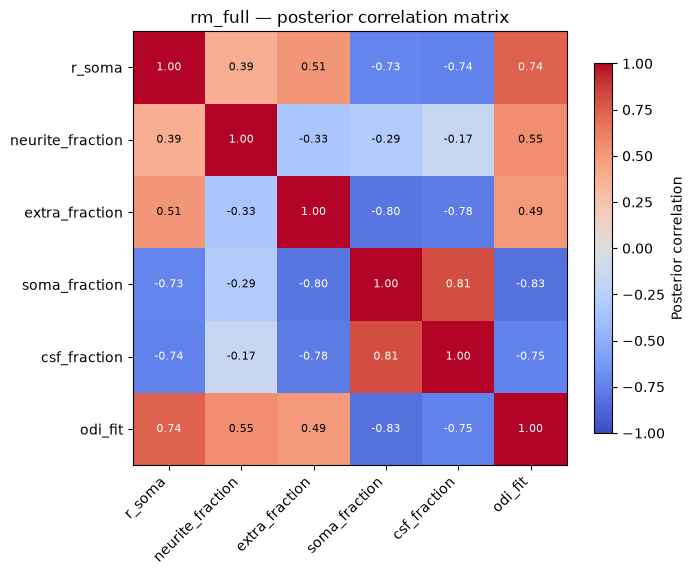

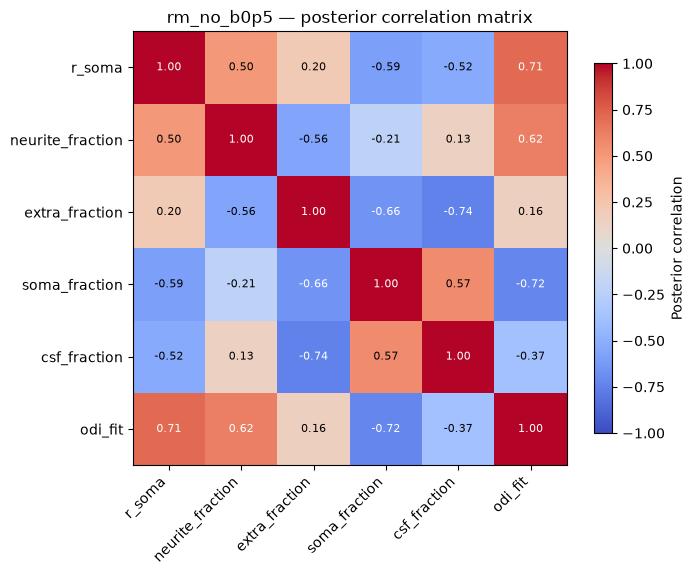

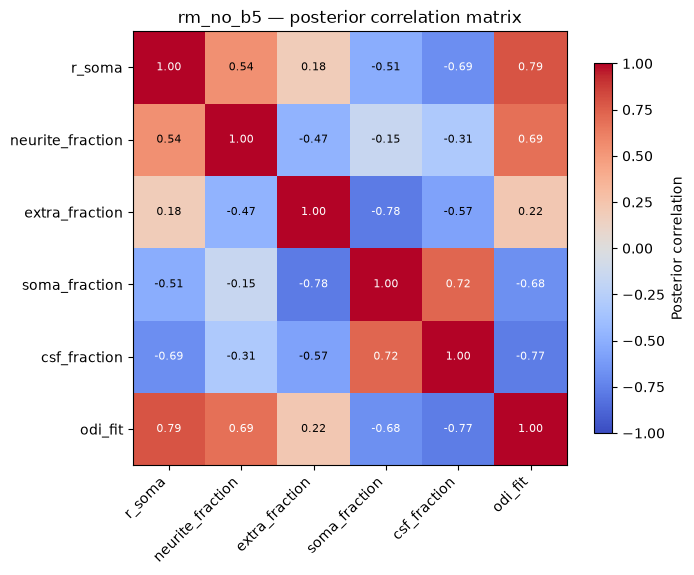

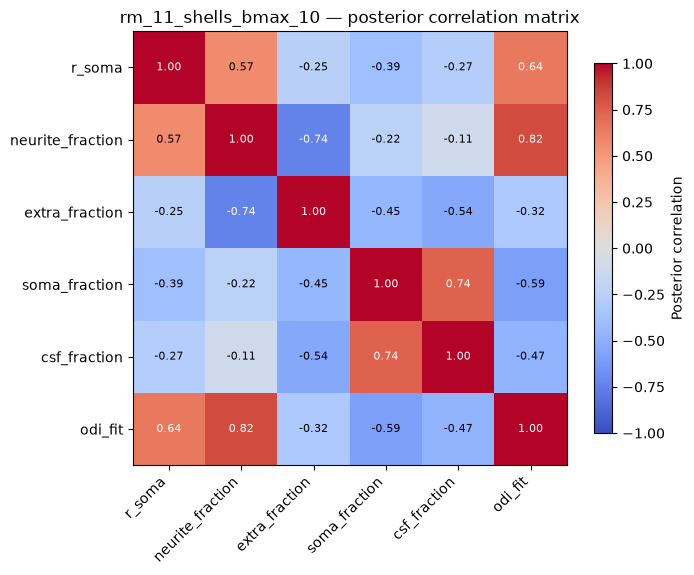

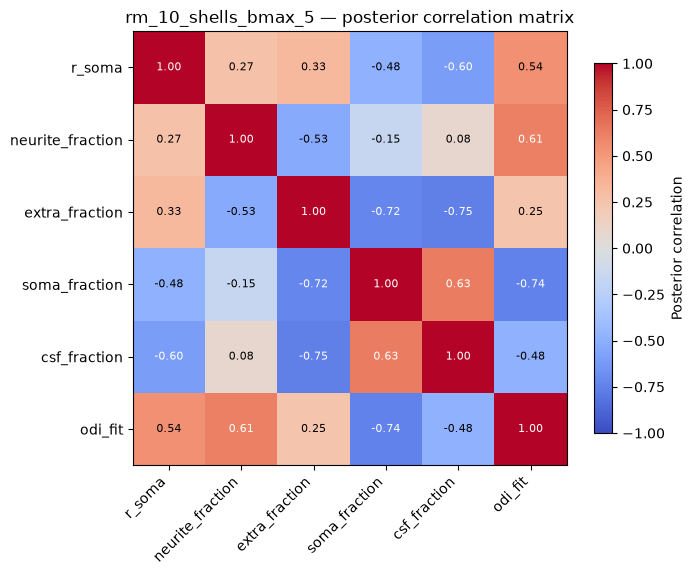

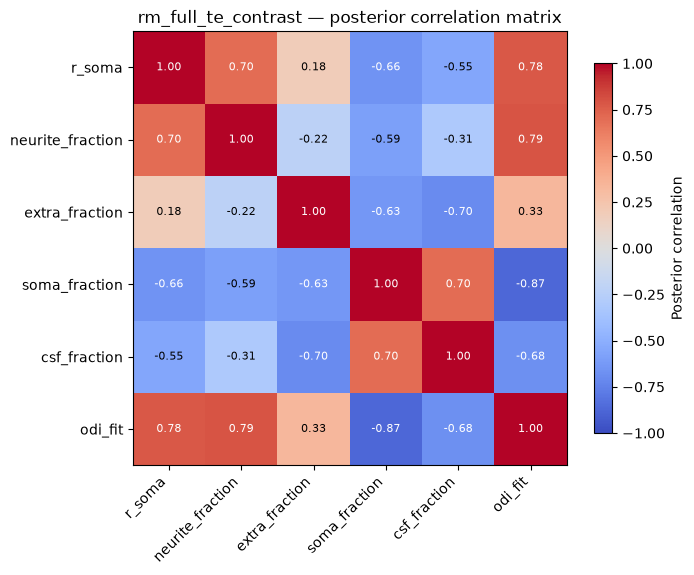

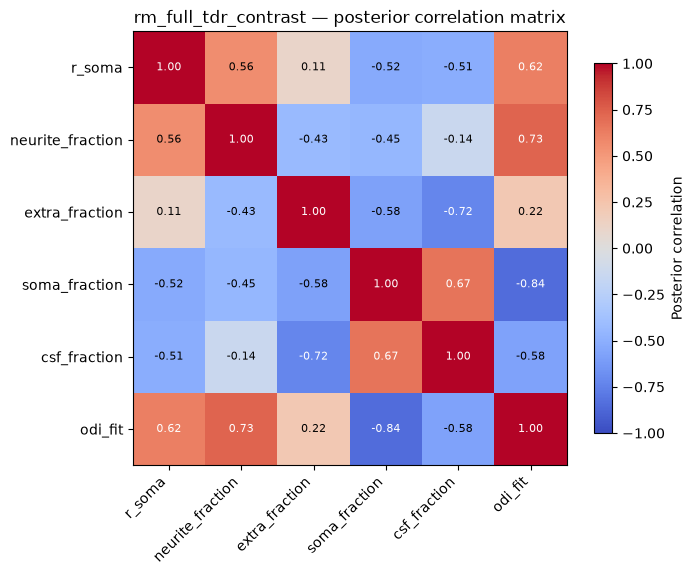

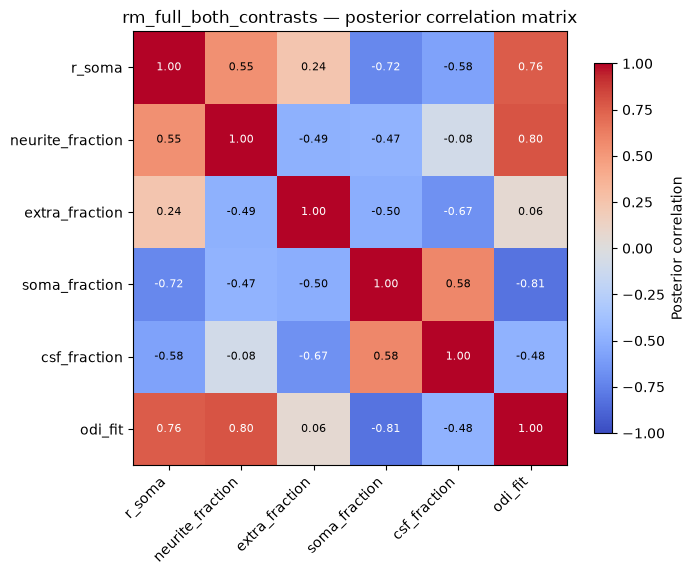

In [60]:


for acq in acquisitions.keys():

    rows = mcmc_df[
        (mcmc_df["acquisition"] == acq) &
        (mcmc_df["prior_set"] == "none")
    ]

    if len(rows) == 0:
        continue

    result = rows["mcmc_result"].iloc[0]
    samples = result.physical_samples(flat=True)

    data = {}

    for p in plot_params:
        if p == "odi_fit":
            if "kappa" in samples:
                data[p] = np.array(
                    [odi_from_kappa(k) for k in samples["kappa"]]
                )
        elif p in samples:
            data[p] = np.asarray(samples[p])

    X = np.column_stack([data[p] for p in data])
    corr = np.corrcoef(X.T)

    fig, ax = plt.subplots(figsize=(7,6))

    im = ax.imshow(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
    )

    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(
                j,
                i,
                f"{corr[i,j]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="black" if abs(corr[i,j]) < 0.6 else "white",
            )

    ax.set_xticks(np.arange(len(data)))
    ax.set_yticks(np.arange(len(data)))
    ax.set_xticklabels(data.keys(), rotation=45, ha="right")
    ax.set_yticklabels(data.keys())

    plt.colorbar(im, ax=ax, shrink=0.8, label="Posterior correlation")

    ax.set_title(f"{acq} — posterior correlation matrix")

    plt.show()

## Residuals coloured by shell

Interpretation guide:

Are the residuals for each shell random? If yes, great! If not, they may be systematically high or low for any given shell. 

If biased on high shells, the model is failing only when diffusion weighting becomes very strong. Means that either our restricted compartment is inadequate or the acquisition is measuring restriction that the model cannot explain.
For neuroinflammation this is exactly what I'd expect if glial restriction becomes important.


rm_full


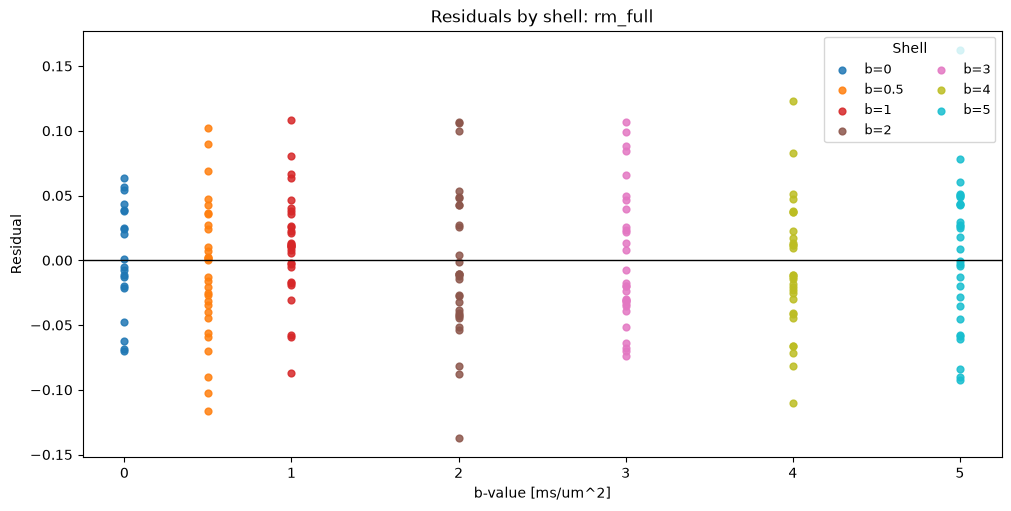


rm_no_b0p5


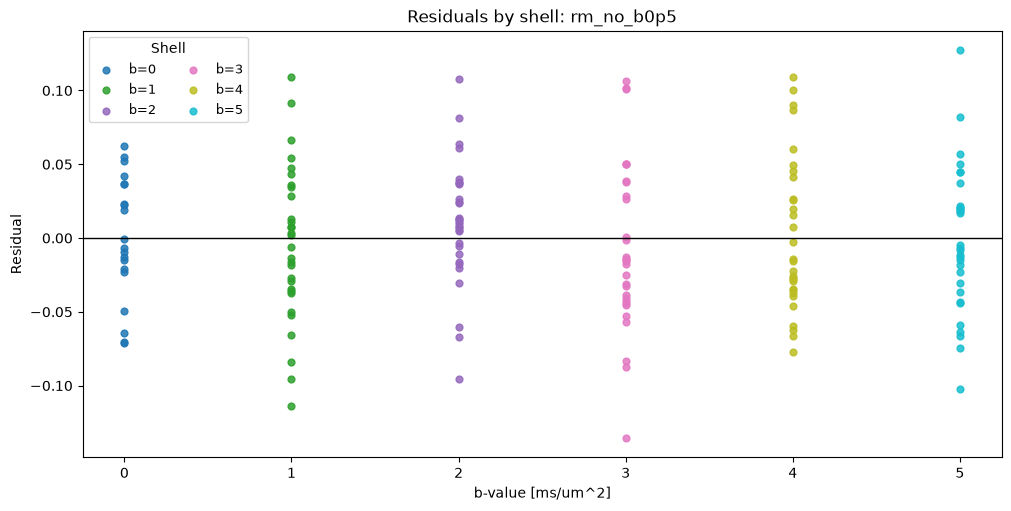


rm_no_b5


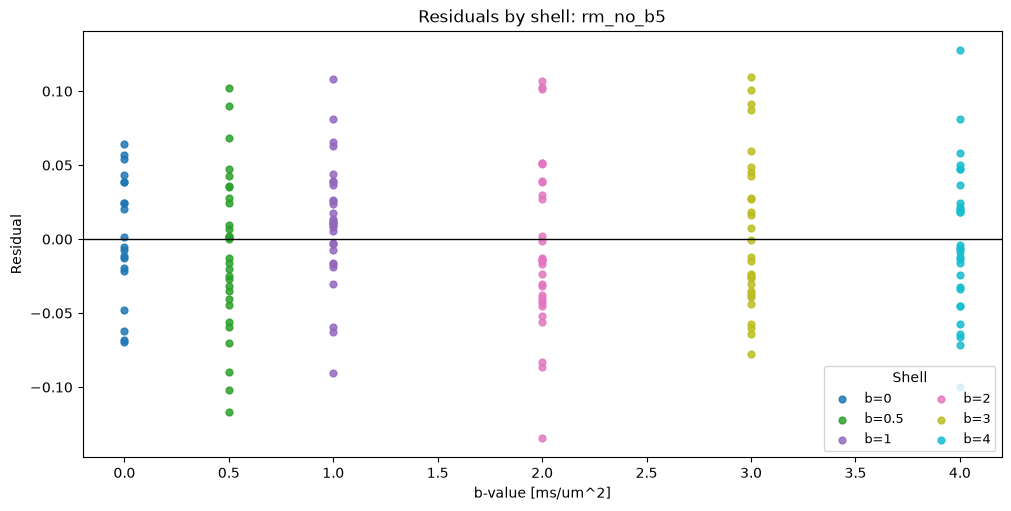


rm_11_shells_bmax_10


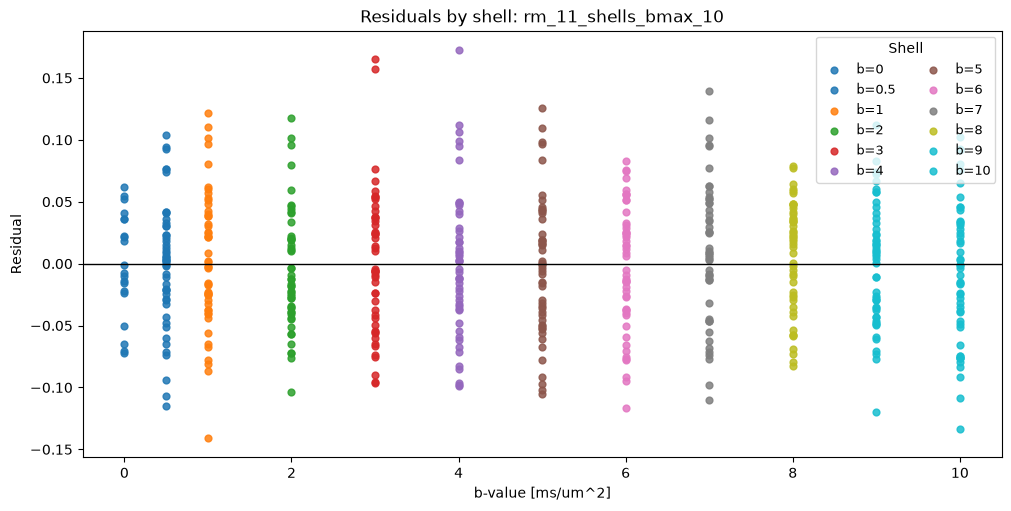


rm_10_shells_bmax_5


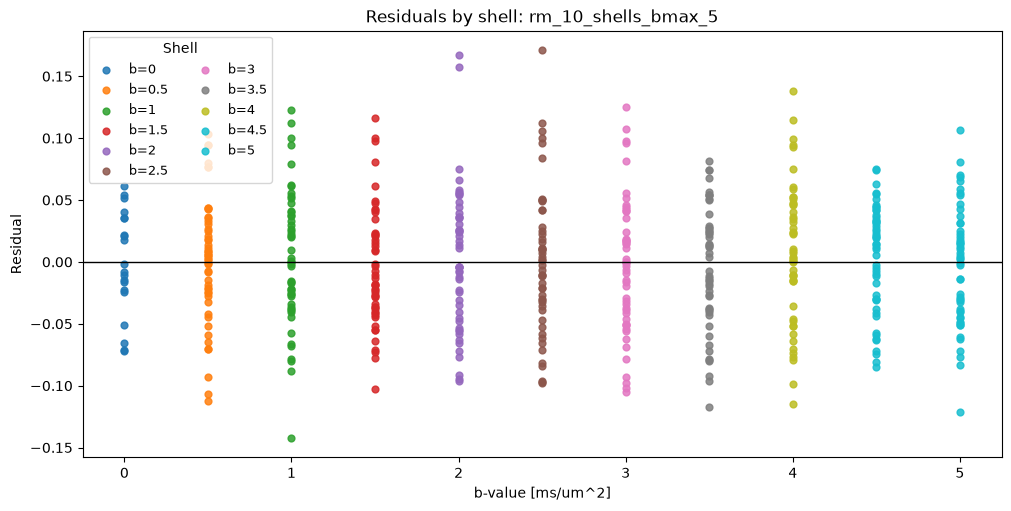


rm_full_te_contrast


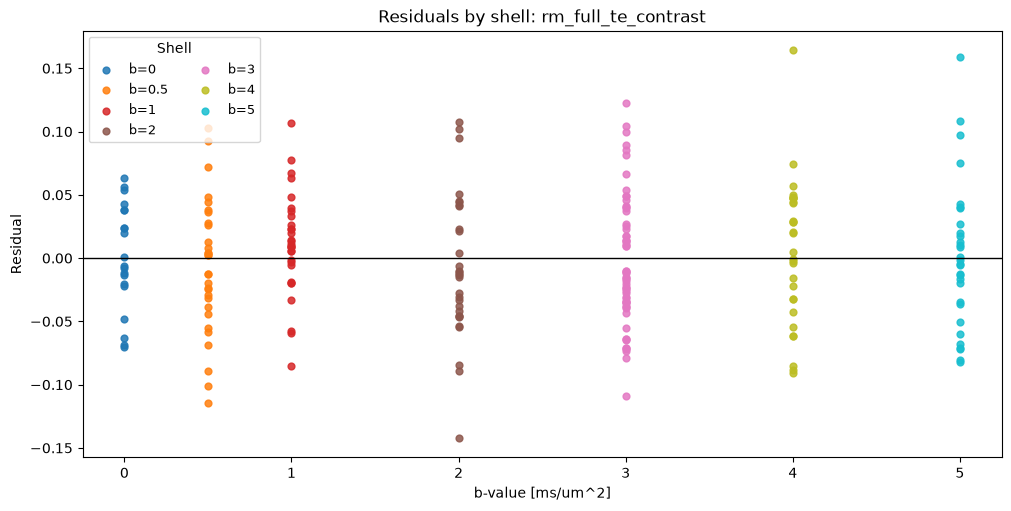


rm_full_tdr_contrast


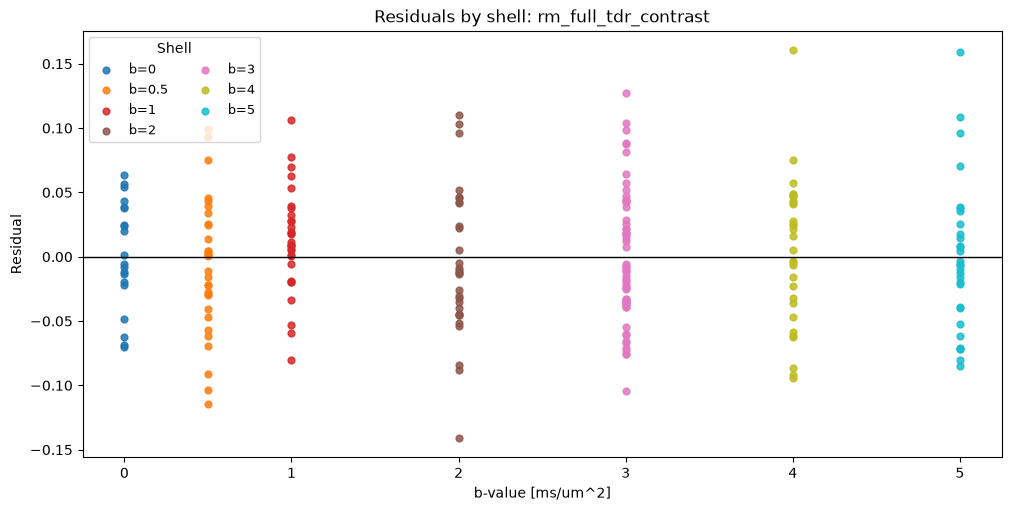


rm_full_both_contrasts


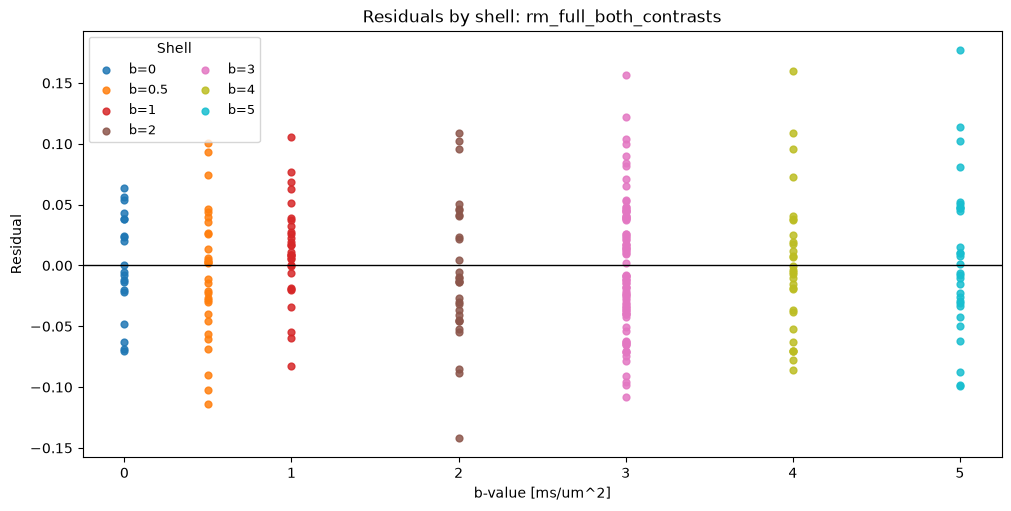

In [61]:
def plot_residuals_by_shell(acq_name: str):
    acq = acquisitions[acq_name]
    sub = ls_df[(ls_df["acquisition"] == acq_name) & (ls_df["success"])].copy()
    if sub.empty:
        print(f"No successful fits found for {acq_name}")
        return

    row = sub.iloc[0]
    bvals = np.asarray(acq.b_values)

    unique_shells = np.unique(np.round(bvals, 4))
    cmap = plt.get_cmap("tab10")

    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

    for i, shell in enumerate(unique_shells):
        mask = np.isclose(bvals, shell)

        ax.scatter(
            bvals[mask],
            row["residuals"][mask],
            s=24,
            alpha=0.85,
            color=cmap(i / max(1, len(unique_shells)-1)),
            label=f"b={shell:g}",
        )

    ax.axhline(0.0, color="k", linewidth=1)
    ax.set_xlabel("b-value [ms/um^2]")
    ax.set_ylabel("Residual")
    ax.set_title(f"Residuals by shell: {acq_name}")
    ax.legend(title="Shell", ncols=2, fontsize=9)
    plt.show()

for acq_name in acquisitions:
    print(f"\n{'='*80}")
    print(f"{acq_name}")
    print(f"{'='*80}")
    plot_residuals_by_shell(acq_name)

## Plot the ODI error by acquisition

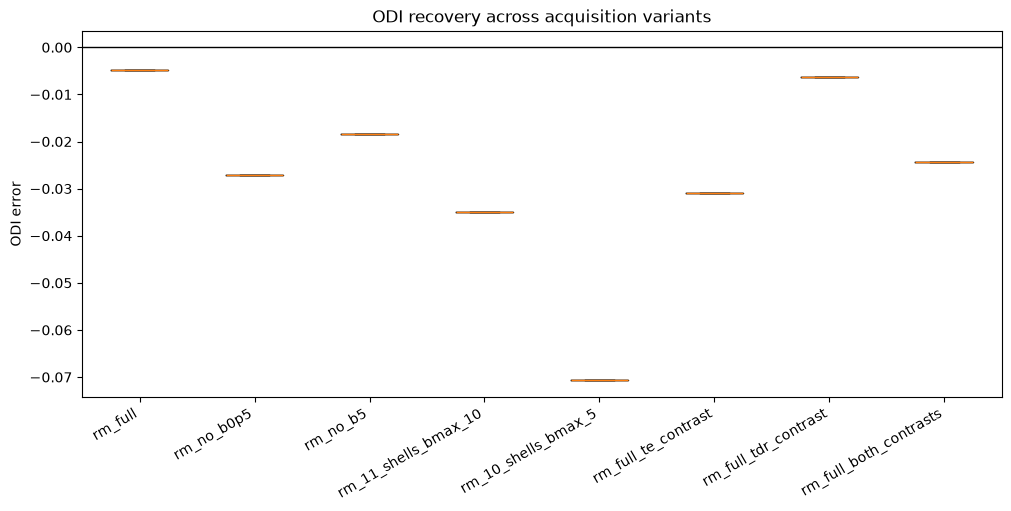

In [62]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

labels = []
data = []

for name in acquisitions.keys():
    vals = ls_df.loc[ls_df["acquisition"] == name, "odi_error"].dropna().values
    if len(vals) == 0:
        continue
    labels.append(name)
    data.append(vals)

ax.boxplot(data, tick_labels=labels, showfliers=False)
ax.axhline(0.0, color="k", linewidth=1)
ax.set_ylabel("ODI error")
ax.set_title("ODI recovery across acquisition variants")
plt.xticks(rotation=30, ha="right")
plt.show()

In [63]:
print(ls_df["acquisition"].value_counts())
print(list(acquisitions.keys()))

acquisition
rm_full                   1
rm_no_b0p5                1
rm_no_b5                  1
rm_11_shells_bmax_10      1
rm_10_shells_bmax_5       1
rm_full_te_contrast       1
rm_full_tdr_contrast      1
rm_full_both_contrasts    1
Name: count, dtype: int64
['rm_full', 'rm_no_b0p5', 'rm_no_b5', 'rm_11_shells_bmax_10', 'rm_10_shells_bmax_5', 'rm_full_te_contrast', 'rm_full_tdr_contrast', 'rm_full_both_contrasts']


Plot residuals for one representative repeat per acquisition

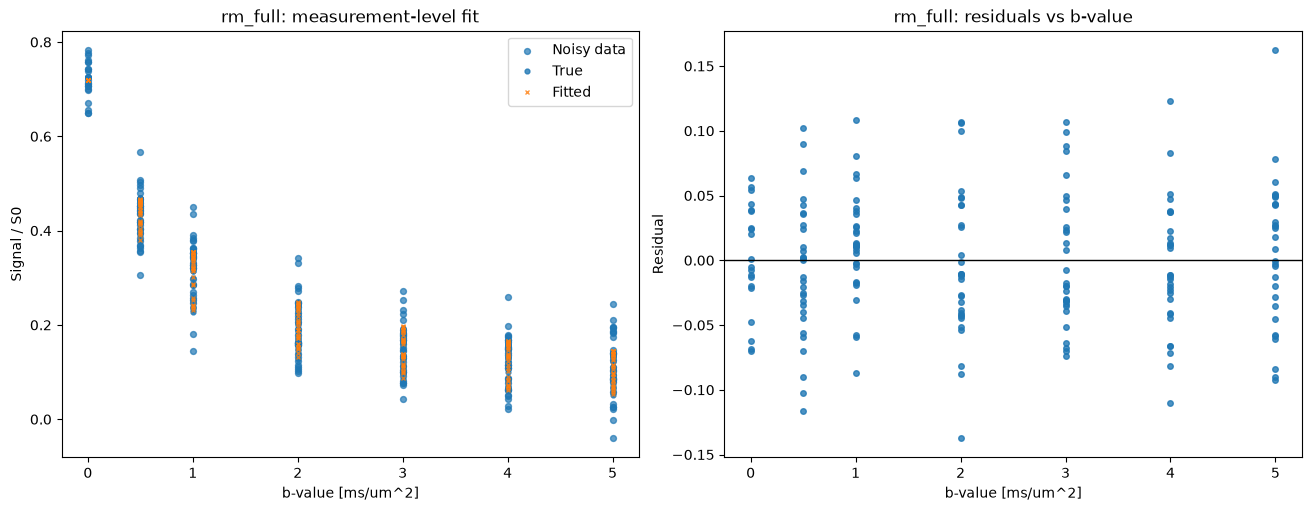

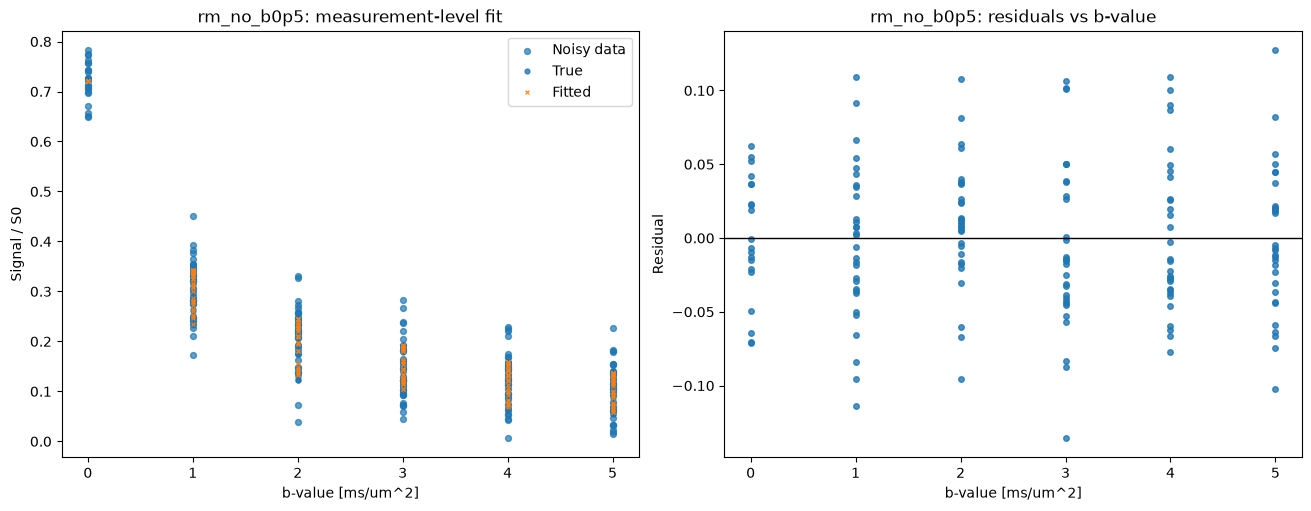

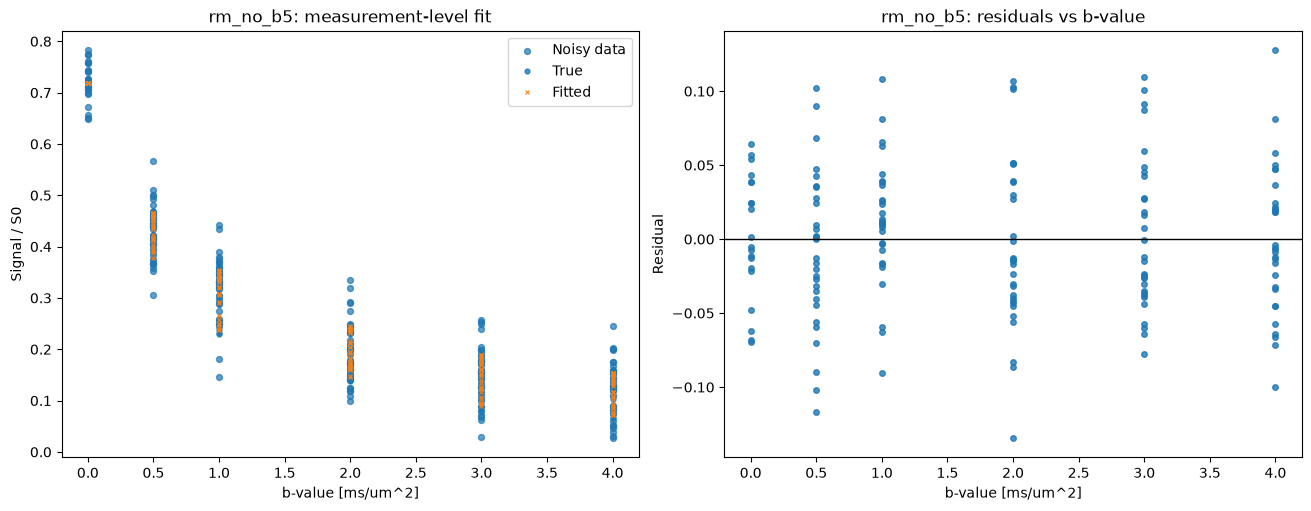

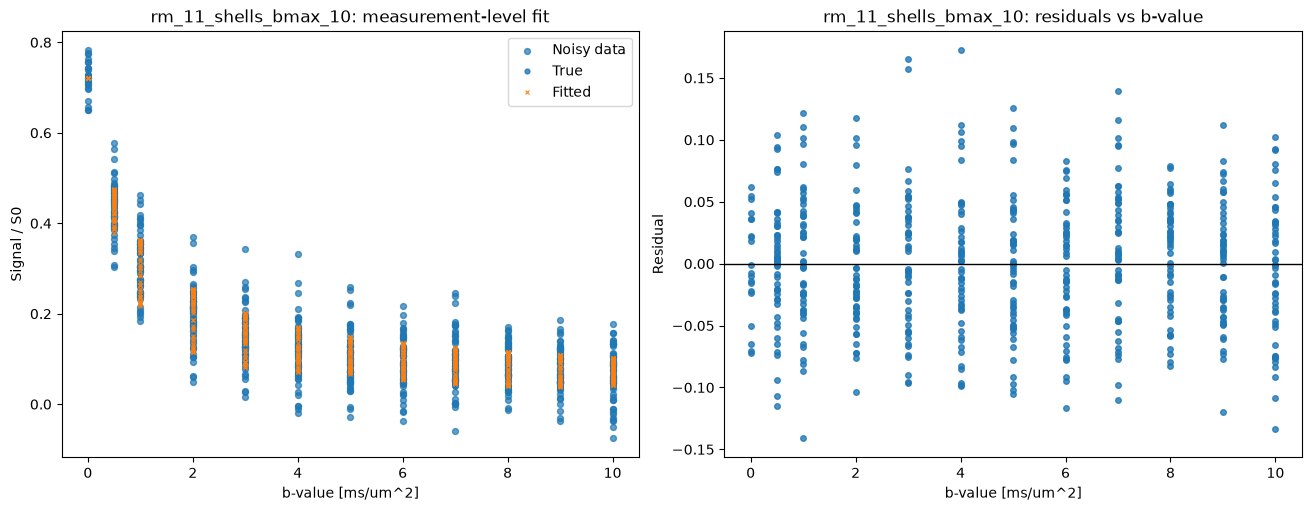

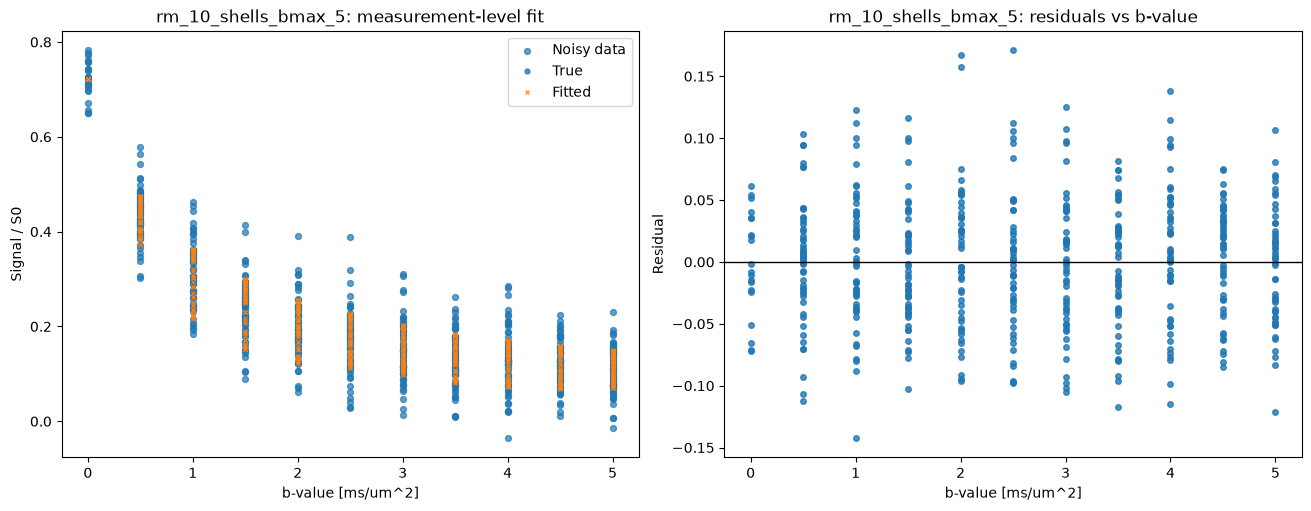

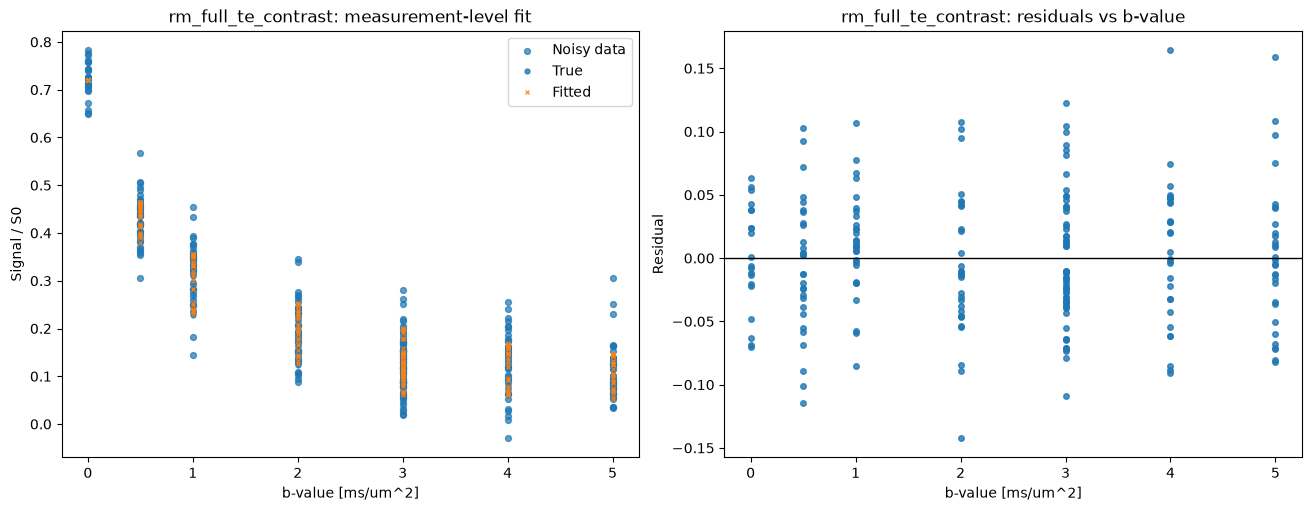

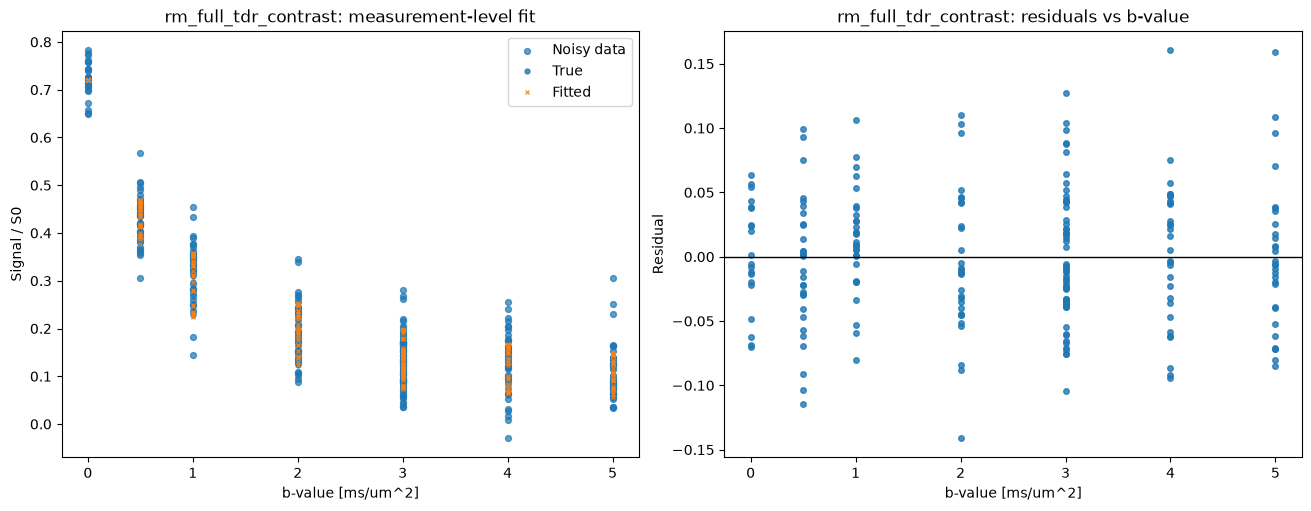

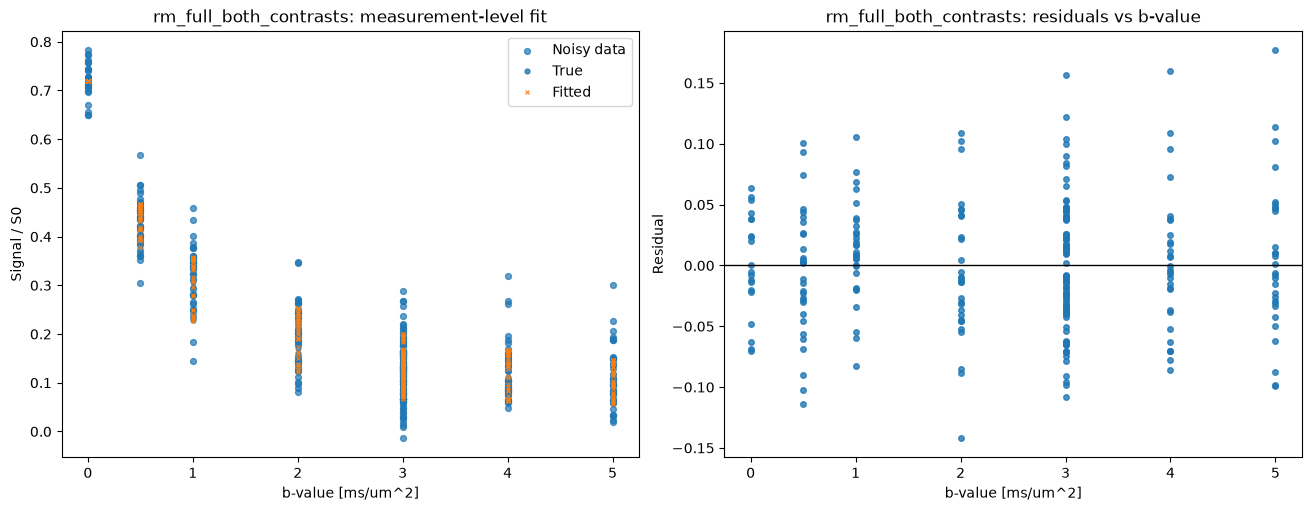

In [64]:
for acq_name in acquisitions.keys():
    row = ls_df[ls_df["acquisition"] == acq_name].iloc[0]

    bvals = acquisitions[acq_name].b_values

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

    axes[0].scatter(bvals, row["signal_noisy"], s=18, alpha=0.7, label="Noisy data")
    axes[0].plot(bvals, row["signal_true"], "o", markersize=3.5, alpha=0.8, label="True")
    axes[0].plot(bvals, row["predicted"], "x", markersize=3.5, alpha=0.8, label="Fitted")
    axes[0].set_xlabel("b-value [ms/um^2]")
    axes[0].set_ylabel("Signal / S0")
    axes[0].set_title(f"{acq_name}: measurement-level fit")
    axes[0].legend()

    axes[1].scatter(bvals, row["residuals"], s=16, alpha=0.8)
    axes[1].axhline(0.0, color="k", linewidth=1)
    axes[1].set_xlabel("b-value [ms/um^2]")
    axes[1].set_ylabel("Residual")
    axes[1].set_title(f"{acq_name}: residuals vs b-value")

    plt.show()

## Build a summary table of key results

In [65]:
summary = (
    ls_df.groupby("acquisition")
    .agg(
        success_rate=("success", "mean"),
        n_evaluations_median=("n_evaluations", "median"),
        failure_count=("success", lambda x: int(x.eq(False).sum())),
        rmse_median=("rmse", "median"),
        S0_mae=("S0_error", lambda x: np.nanmean(np.abs(x))),
        d_in_mae=("d_in_error", lambda x: np.nanmean(np.abs(x))),
        d_csf_mae=("d_csf_error", lambda x: np.nanmean(np.abs(x))),
        d_perp_mae=("d_perp_error", lambda x: np.nanmean(np.abs(x))),
        d_soma_mae=("d_soma_error", lambda x: np.nanmean(np.abs(x))),
        t2_neurite_mae=("t2_neurite_error", lambda x: np.nanmean(np.abs(x))),
        t2_extra_mae=("t2_extra_error", lambda x: np.nanmean(np.abs(x))),
        t2_soma_mae=("t2_soma_error", lambda x: np.nanmean(np.abs(x))),
        t2_csf_mae=("t2_csf_error", lambda x: np.nanmean(np.abs(x))),
        r_soma_mae=("r_soma_error", lambda x: np.nanmean(np.abs(x))),
        kappa_mae=("kappa_error", lambda x: np.nanmean(np.abs(x))),
        neurite_fraction_mae=("neurite_fraction_error", lambda x: np.nanmean(np.abs(x))),
        extra_fraction_mae=("extra_fraction_error", lambda x: np.nanmean(np.abs(x))),
        soma_fraction_mae=("soma_fraction_error", lambda x: np.nanmean(np.abs(x))),
        csf_fraction_mae=("csf_fraction_error", lambda x: np.nanmean(np.abs(x))),
        odi_mae=("odi_error", lambda x: np.nanmean(np.abs(x))),
        n_measurements=("n_measurements", "first"),
    )
    .reset_index()
)

# Metrics where higher is better
higher_better = [
    "success_rate",
]

# Metrics where lower is better
lower_better = [
    "n_evaluations_median",
    "failure_count",
    "rmse_median",
    "S0_mae",
    "d_in_mae",
    "d_csf_mae",
    "d_perp_mae",
    "d_soma_mae",
    "t2_neurite_mae",
    "t2_extra_mae",
    "t2_soma_mae",
    "t2_csf_mae",
    "r_soma_mae",
    "kappa_mae",
    "neurite_fraction_mae",
    "extra_fraction_mae",
    "soma_fraction_mae",
    "csf_fraction_mae",
    "odi_mae",
]

metric_directions = {m: "higher" for m in higher_better}
metric_directions.update({m: "lower" for m in lower_better})

# Build one expanded table containing the top 3 acquisitions for each metric.
expanded_rows = []

for metric in higher_better:
    top3 = (
        summary.sort_values(metric, ascending=False)
        .head(3)
        .reset_index(drop=True)
    )
    for rank, (_, row) in enumerate(top3.iterrows(), start=1):
        expanded_rows.append(
            {
                "metric": metric,
                "direction": "higher",
                "rank": rank,
                "acquisition": row["acquisition"],
                "value": row[metric],
            }
        )

for metric in lower_better:
    top3 = (
        summary.sort_values(metric, ascending=True)
        .head(3)
        .reset_index(drop=True)
    )
    for rank, (_, row) in enumerate(top3.iterrows(), start=1):
        expanded_rows.append(
            {
                "metric": metric,
                "direction": "lower",
                "rank": rank,
                "acquisition": row["acquisition"],
                "value": row[metric],
            }
        )

top3_by_metric = pd.DataFrame(expanded_rows)

# Optional: make it a little easier to read
top3_by_metric["metric_label"] = top3_by_metric["metric"].map(
    lambda m: f"{m} ({metric_directions[m]} is better)"
)

# Sort so the output groups nicely by metric
top3_by_metric = top3_by_metric[
    ["metric", "metric_label", "direction", "rank", "acquisition", "value"]
].sort_values(["metric", "rank"], ascending=[True, True]).reset_index(drop=True)

summary

,acquisition,success_rate,n_evaluations_median,failure_count,rmse_median,S0_mae,d_in_mae,d_csf_mae,d_perp_mae,d_soma_mae,...,t2_soma_mae,t2_csf_mae,r_soma_mae,kappa_mae,neurite_fraction_mae,extra_fraction_mae,soma_fraction_mae,csf_fraction_mae,odi_mae,n_measurements
0,rm_10_shells_bmax_5,1.0000,21.0000,0,0.0517,0.0143,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,3.3589,0.7175,0.1680,0.1684,0.0064,0.0068,0.0707,520
1,rm_11_shells_bmax_10,1.0000,32.0000,0,0.0522,0.0010,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,3.3968,0.3084,0.0583,0.1243,0.0507,0.0152,0.0349,570
2,rm_full,1.0000,22.0000,0,0.0507,0.0086,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.3349,0.0382,0.0266,0.1040,0.0697,0.0076,0.0048,200
3,rm_full_both_contrasts,1.0000,101.0000,0,0.0527,0.0119,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.5606,0.2070,0.0002,0.0605,0.0449,0.0153,0.0243,260
4,rm_full_tdr_contrast,1.0000,26.0000,0,0.0514,0.0171,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,1.0331,0.0507,0.0231,0.0114,0.0349,0.0004,0.0063,230
5,rm_full_te_contrast,1.0000,14.0000,0,0.0514,0.0096,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.1456,0.2702,0.0072,0.1452,0.1117,0.0264,0.0310,230
6,rm_no_b0p5,1.0000,21.0000,0,0.0494,0.0149,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,1.3476,0.2328,0.0807,0.0757,0.0987,0.0577,0.0271,170
7,rm_no_b5,1.0000,23.0000,0,0.0495,0.0053,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,1.5295,0.1541,0.1092,0.0508,0.0549,0.0036,0.0185,170


## How do the acquisitions rank in each informative metric?

In [66]:
for metric in list(higher_better) + list(lower_better):
    direction = metric_directions[metric]

    # Skip if all acquisitions have the same value
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    sub = top3_by_metric[top3_by_metric["metric"] == metric]

    print(f"\n{metric} ({direction} is better)")
    print(sub[["rank", "acquisition", "value"]].to_string(index=False))


n_evaluations_median (lower is better)
 rank         acquisition   value
    1 rm_full_te_contrast 14.0000
    2 rm_10_shells_bmax_5 21.0000
    3          rm_no_b0p5 21.0000

rmse_median (lower is better)
 rank acquisition  value
    1  rm_no_b0p5 0.0494
    2    rm_no_b5 0.0495
    3     rm_full 0.0507

S0_mae (lower is better)
 rank          acquisition  value
    1 rm_11_shells_bmax_10 0.0010
    2             rm_no_b5 0.0053
    3              rm_full 0.0086

r_soma_mae (lower is better)
 rank            acquisition  value
    1    rm_full_te_contrast 0.1456
    2                rm_full 0.3349
    3 rm_full_both_contrasts 0.5606

kappa_mae (lower is better)
 rank          acquisition  value
    1              rm_full 0.0382
    2 rm_full_tdr_contrast 0.0507
    3             rm_no_b5 0.1541

neurite_fraction_mae (lower is better)
 rank            acquisition  value
    1 rm_full_both_contrasts 0.0002
    2    rm_full_te_contrast 0.0072
    3   rm_full_tdr_contrast 0.0231

extra_f

In [67]:
ranking = summary[["acquisition"]].copy()

metrics_used = []

metrics_to_rank = [
    "rmse_median",
    "S0_mae",
    "d_in_mae",
    "d_csf_mae",
    "d_perp_mae",
    "d_soma_mae",
    "t2_neurite_mae",
    "t2_extra_mae",
    "t2_soma_mae",
    "t2_csf_mae",
    "r_soma_mae",
    "neurite_fraction_mae",
    "extra_fraction_mae",
    "soma_fraction_mae",
    "csf_fraction_mae",
    "odi_mae",
]

# Rank higher-is-better metrics
for metric in higher_better:
    if metric not in metrics_to_rank:
        continue
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    ranking[metric + "_rank"] = summary[metric].rank(
        ascending=False,
        method="dense",
    )
    metrics_used.append(metric)

# Rank lower-is-better metrics
for metric in lower_better:
    if metric not in metrics_to_rank:
        continue
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    ranking[metric + "_rank"] = summary[metric].rank(
        ascending=True,
        method="dense",
    )
    metrics_used.append(metric)

rank_cols = [c for c in ranking.columns if c.endswith("_rank")]

# Summary ranking statistics
ranking["mean_rank"] = ranking[rank_cols].mean(axis=1)
ranking["median_rank"] = ranking[rank_cols].median(axis=1)
ranking["std_rank"] = ranking[rank_cols].std(axis=1)

# Podium counts
ranking["n_1st"] = (ranking[rank_cols] == 1).sum(axis=1)
ranking["n_2nd"] = (ranking[rank_cols] == 2).sum(axis=1)
ranking["n_3rd"] = (ranking[rank_cols] == 3).sum(axis=1)
ranking["top3"] = ranking["n_1st"] + ranking["n_2nd"] + ranking["n_3rd"]

# Sort by mean rank, then by podium finishes
ranking = ranking.sort_values(
    by=["mean_rank", "top3", "n_1st"],
    ascending=[True, False, False],
).reset_index(drop=True)

print(f"Ranking based on {len(metrics_used)} informative metrics:")
print("Metrics used:")
for metric in metrics_used:
    print(f"  - {metric}")

display(
    ranking[
        [
            "acquisition",
            "mean_rank",
            "median_rank",
            "std_rank",
            "n_1st",
            "n_2nd",
            "n_3rd",
            "top3",
        ]
    ]
)

Ranking based on 8 informative metrics:
Metrics used:
  - rmse_median
  - S0_mae
  - r_soma_mae
  - neurite_fraction_mae
  - extra_fraction_mae
  - soma_fraction_mae
  - csf_fraction_mae
  - odi_mae


,acquisition,mean_rank,median_rank,std_rank,n_1st,n_2nd,n_3rd,top3
0,rm_full_tdr_contrast,3.1250,2.5000,2.2952,2,2,1,5
1,rm_full,3.5000,3.5000,1.6036,1,1,2,4
2,rm_no_b5,3.6250,2.5000,2.0659,0,4,1,5
3,rm_full_both_contrasts,4.1250,3.5000,2.1671,1,0,3,4
4,rm_full_te_contrast,5.0000,5.5000,2.5071,1,1,0,2
5,rm_11_shells_bmax_10,5.3750,5.5000,2.1998,1,0,0,1
6,rm_no_b0p5,5.3750,5.5000,2.1998,1,0,0,1
7,rm_10_shells_bmax_5,5.8750,6.5000,2.5877,1,0,1,2


## Parameter Estimation Accuracy Relative to Acquisition Cost

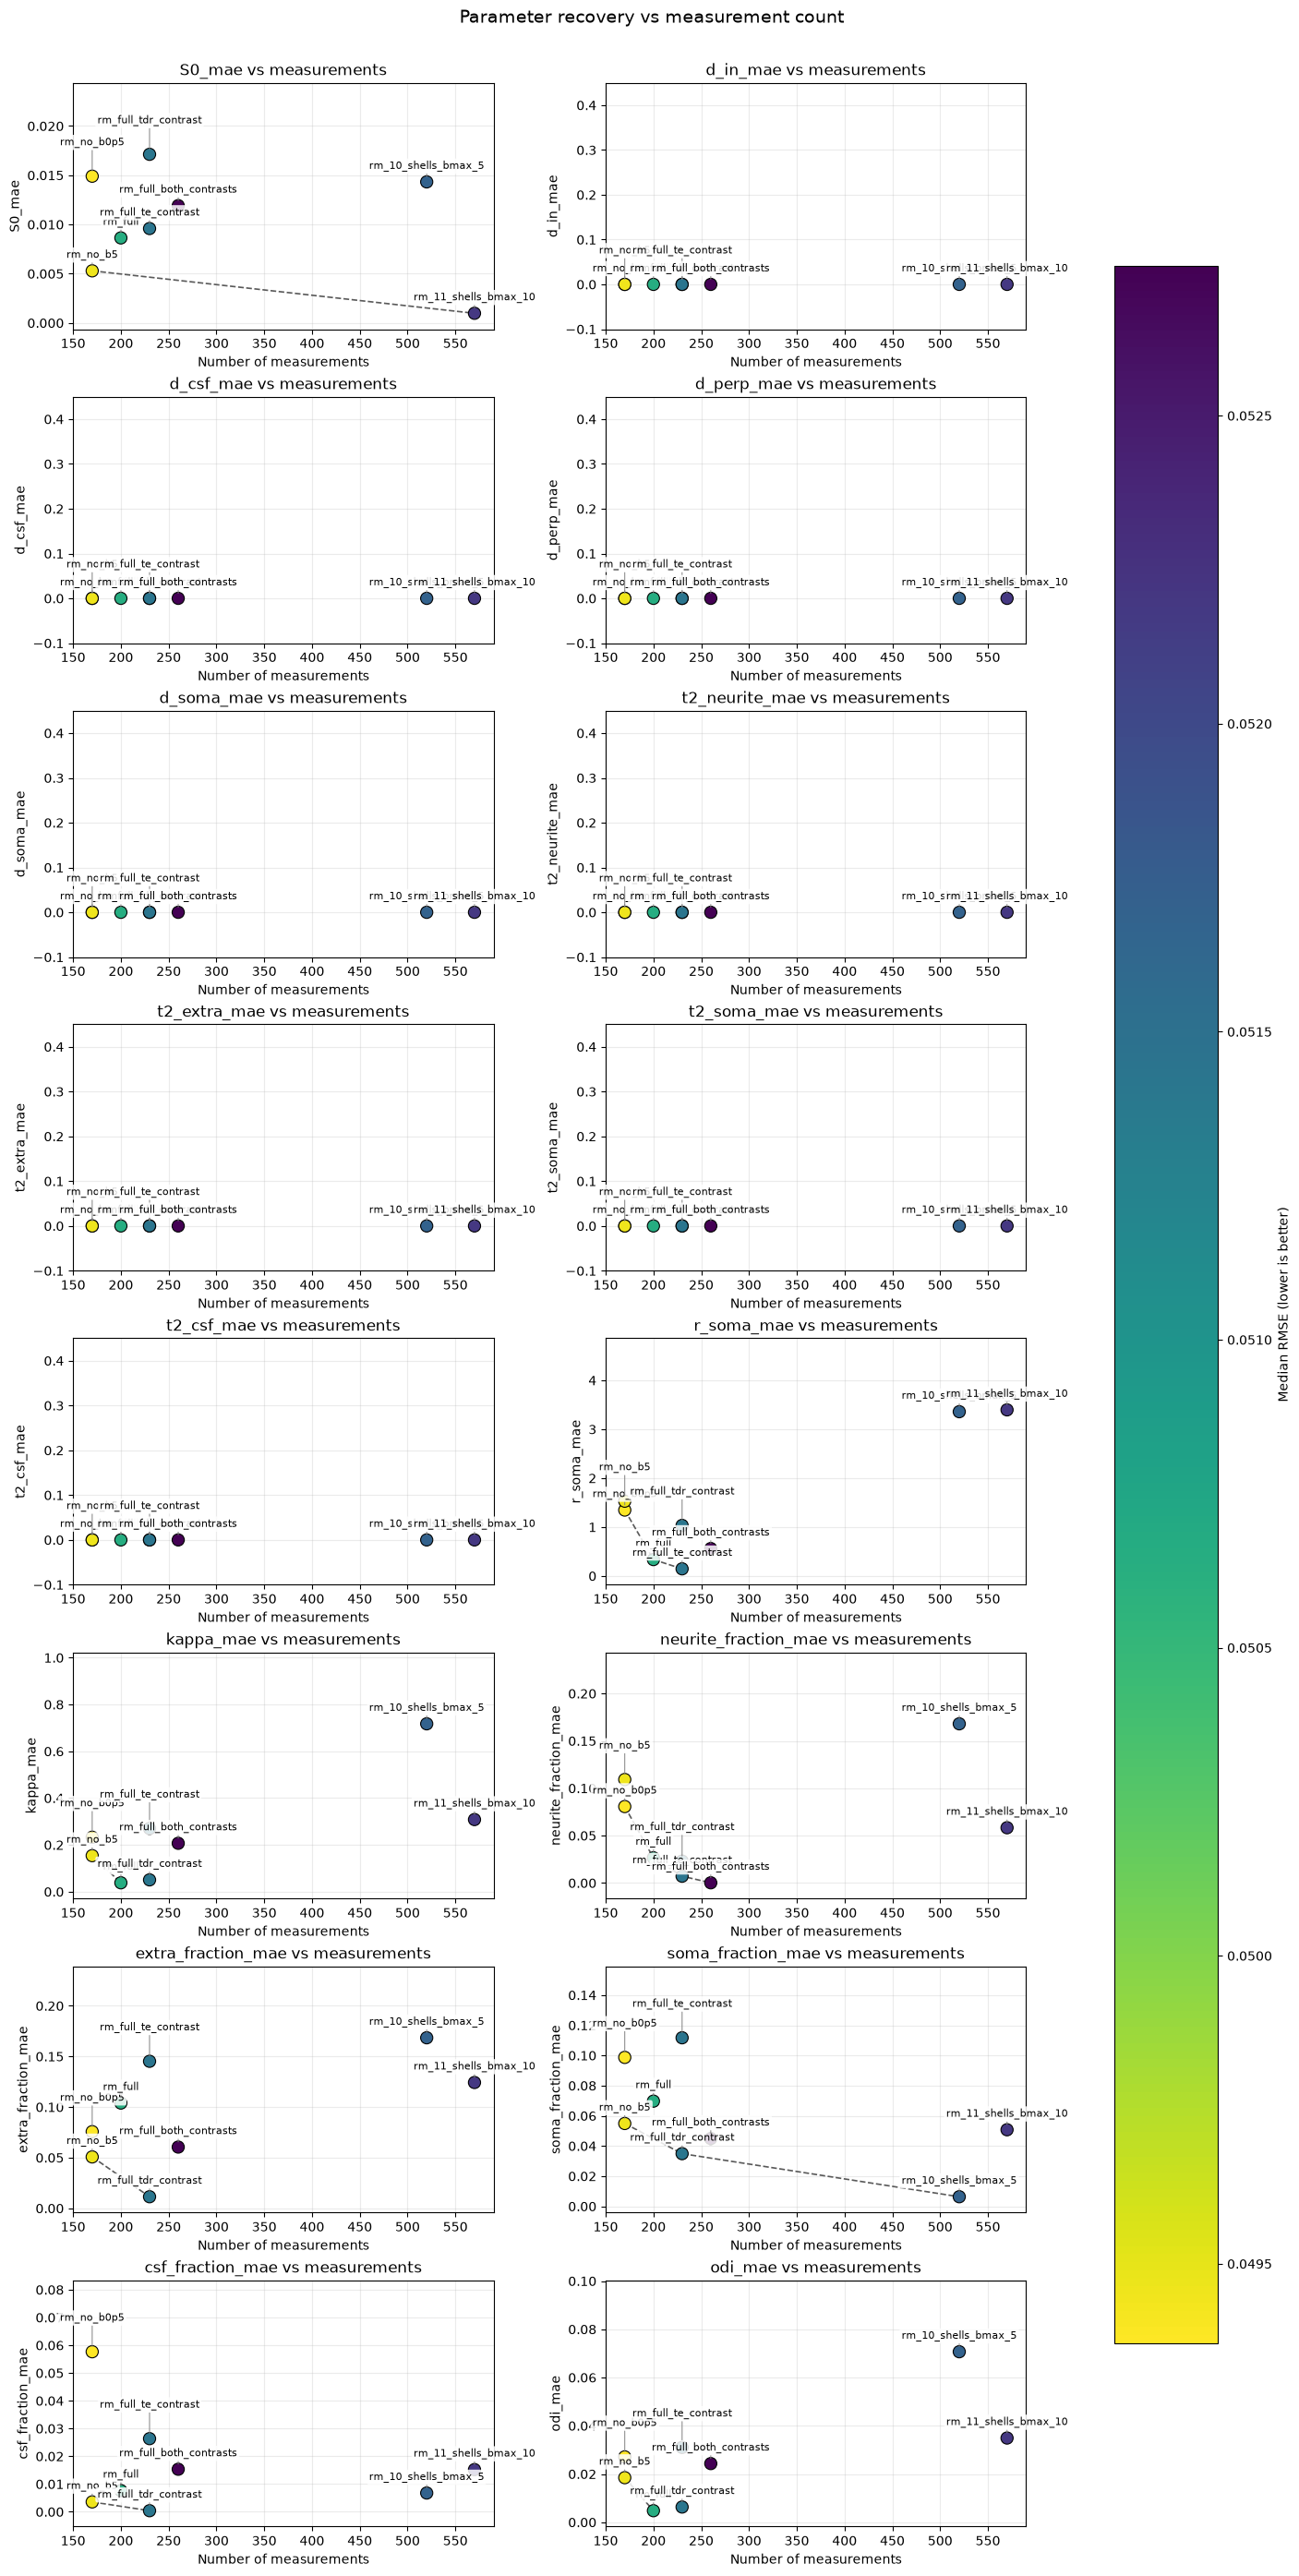

In [68]:
# -----------------------------------------------------------------------------
# Build a per-acquisition table of parameter MAEs
# -----------------------------------------------------------------------------
mae_map = {
    "S0_mae": "S0_error",
    "d_in_mae": "d_in_error",
    "d_csf_mae": "d_csf_error",
    "d_perp_mae": "d_perp_error",
    "d_soma_mae": "d_soma_error",
    "t2_neurite_mae": "t2_neurite_error",
    "t2_extra_mae": "t2_extra_error",
    "t2_soma_mae": "t2_soma_error",
    "t2_csf_mae": "t2_csf_error",
    "r_soma_mae": "r_soma_error",
    "kappa_mae": "kappa_error",
    "neurite_fraction_mae": "neurite_fraction_error",
    "extra_fraction_mae": "extra_fraction_error",
    "soma_fraction_mae": "soma_fraction_error",
    "csf_fraction_mae": "csf_fraction_error",
    "odi_mae": "odi_error",
}

# 3) In the per_acq table, remove nrmse_median too
per_acq = (
    ls_df.groupby("acquisition")
    .agg(
        success_rate=("success", "mean"),
        n_measurements=("n_measurements", "first"),
        n_evaluations_median=("n_evaluations", "median"),
        rmse_median=("rmse", "median"),
        S0_mae=("S0_error", lambda x: np.nanmean(np.abs(x))),
        d_in_mae=("d_in_error", lambda x: np.nanmean(np.abs(x))),
        d_csf_mae=("d_csf_error", lambda x: np.nanmean(np.abs(x))),
        d_perp_mae=("d_perp_error", lambda x: np.nanmean(np.abs(x))),
        d_soma_mae=("d_soma_error", lambda x: np.nanmean(np.abs(x))),
        t2_neurite_mae=("t2_neurite_error", lambda x: np.nanmean(np.abs(x))),
        t2_extra_mae=("t2_extra_error", lambda x: np.nanmean(np.abs(x))),
        t2_soma_mae=("t2_soma_error", lambda x: np.nanmean(np.abs(x))),
        t2_csf_mae=("t2_csf_error", lambda x: np.nanmean(np.abs(x))),
        r_soma_mae=("r_soma_error", lambda x: np.nanmean(np.abs(x))),
        kappa_mae=("kappa_error", lambda x: np.nanmean(np.abs(x))),
        neurite_fraction_mae=("neurite_fraction_error", lambda x: np.nanmean(np.abs(x))),
        extra_fraction_mae=("extra_fraction_error", lambda x: np.nanmean(np.abs(x))),
        soma_fraction_mae=("soma_fraction_error", lambda x: np.nanmean(np.abs(x))),
        csf_fraction_mae=("csf_fraction_error", lambda x: np.nanmean(np.abs(x))),
        odi_mae=("odi_error", lambda x: np.nanmean(np.abs(x))),
    )
    .reset_index()
)

# Keep all acquisitions for tables, but only plot the ones we want.
plot_per_acq = per_acq[
    per_acq["acquisition"] != "uk_biobank"
].copy()

# -----------------------------------------------------------------------------
# Optional: identify a simple Pareto frontier for each metric
# (lower n_measurements and lower MAE are both better)
# -----------------------------------------------------------------------------
def pareto_mask(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
    Returns a boolean mask for non-dominated points.
    Lower x and lower y are better.
    """
    n = len(x)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        if not mask[i]:
            continue
        dominated = (x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))
        if np.any(dominated):
            mask[i] = False
    return mask


def plot_metric_vs_measurements(
    ax,
    table,
    metric,
    title=None,
    label_step=14,   # vertical spacing between labels, in points
    base_offset=8,   # starting offset above the point, in points
):
    x = table["n_measurements"].to_numpy()
    y = table[metric].to_numpy()
    c = table["rmse_median"].to_numpy()

    norm = Normalize(
        vmin=table["rmse_median"].min(),
        vmax=table["rmse_median"].max(),
    )

    sc = ax.scatter(
        x,
        y,
        c=c,
        cmap="viridis_r",
        norm=norm,
        s=90,
        edgecolor="black",
        linewidth=0.8,
        zorder=3,
    )

    # Give the axis a bit of headroom for stacked labels.
    y_min = np.nanmin(y)
    y_max = np.nanmax(y)
    y_span = y_max - y_min if y_max > y_min else 1.0
    ax.set_ylim(y_min - 0.10 * y_span, y_max + 0.45 * y_span)

    # Sort so within each x-group, the best metric value gets the closest label.
    plot_table = table.sort_values(
        ["n_measurements", metric, "acquisition"],
        ascending=[True, True, True],
    ).copy()

    # One vertical stack per x-value.
    for xval, grp in plot_table.groupby("n_measurements", sort=True):
        grp = grp.sort_values(metric, ascending=True).reset_index(drop=True)

        for j, row in grp.iterrows():
            ax.annotate(
                row["acquisition"],
                xy=(row["n_measurements"], row[metric]),
                xytext=(0, base_offset + label_step * j),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.85,
                ),
                arrowprops=dict(
                    arrowstyle="-",
                    color="0.5",
                    lw=0.7,
                    shrinkA=0,
                    shrinkB=4,
                ),
                zorder=4,
            )

    # Pareto frontier line
    pmask = pareto_mask(x, y)
    pareto = table.loc[pmask].sort_values("n_measurements")
    ax.plot(
        pareto["n_measurements"],
        pareto[metric],
        linestyle="--",
        linewidth=1.2,
        color="0.35",
        zorder=2,
    )

    ax.set_xlabel("Number of measurements")
    ax.set_ylabel(metric)
    ax.set_title(title or metric)
    ax.grid(True, alpha=0.25)

    return sc

# -----------------------------------------------------------------------------
# Make one subplot per metric
# -----------------------------------------------------------------------------
metrics = list(mae_map.keys())

ncols = 2
nrows = int(np.ceil(len(metrics) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 3.4 * nrows),
    constrained_layout=True,
)

axes = np.array(axes).reshape(-1)

last_sc = None
for ax, metric in zip(axes, metrics):
    last_sc = plot_metric_vs_measurements(
        ax=ax,
        table=plot_per_acq,
        metric=metric,
        title=f"{metric} vs measurements",
    )

for ax in axes[len(metrics):]:
    ax.axis("off")

cbar = fig.colorbar(last_sc, ax=axes.tolist(), shrink=0.85)
cbar.set_label("Median RMSE (lower is better)")

fig.suptitle("Parameter recovery vs measurement count", y=1.02, fontsize=14)
plt.show()

In [69]:
def build_mcmc_comparison_table(
    mcmc_none_df: pd.DataFrame | None,
    mcmc_prior_df: pd.DataFrame | None,
    true_parameters: dict,
    params=None,
):
    if params is None:
        params = [
            "S0",
            "d_in",
            "d_perp",
            "d_soma",
            "r_soma",
            "d_csf",
            "kappa",
            "theta",
            "phi",
            "t2_neurite",
            "t2_extra",
            "t2_soma",
            "t2_csf",
            "neurite_fraction",
            "extra_fraction",
            "soma_fraction",
            "csf_fraction",
        ]

    rows = []
    for p in params:
        row = {"parameter": p, "true": true_parameters.get(p, np.nan)}

        if mcmc_none_df is not None and not mcmc_none_df.empty and f"{p}_post_mean" in mcmc_none_df.columns:
            row["no_priors_mean"] = float(mcmc_none_df[f"{p}_post_mean"].iloc[0])
            row["no_priors_sd"] = float(mcmc_none_df[f"{p}_post_sd"].iloc[0])
        else:
            row["no_priors_mean"] = np.nan
            row["no_priors_sd"] = np.nan

        if mcmc_prior_df is not None and not mcmc_prior_df.empty and f"{p}_post_mean" in mcmc_prior_df.columns:
            row["with_priors_mean"] = float(mcmc_prior_df[f"{p}_post_mean"].iloc[0])
            row["with_priors_sd"] = float(mcmc_prior_df[f"{p}_post_sd"].iloc[0])
        else:
            row["with_priors_mean"] = np.nan
            row["with_priors_sd"] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)

In [70]:
mcmc_table = build_mcmc_comparison_table(
    mcmc_none_df=mcmc_none_df,
    mcmc_prior_df=mcmc_prior_df if "mcmc_prior_df" in globals() else None,
    true_parameters=true_parameters,
)

display(mcmc_table)

,parameter,true,no_priors_mean,no_priors_sd,with_priors_mean,with_priors_sd
0,S0,1.0000,NaN,NaN,NaN,NaN
1,d_in,2.2000,NaN,NaN,NaN,NaN
2,d_perp,0.5000,NaN,NaN,NaN,NaN
3,d_soma,3.0000,NaN,NaN,NaN,NaN
4,r_soma,7.0000,NaN,NaN,NaN,NaN
5,d_csf,3.0000,NaN,NaN,NaN,NaN
6,kappa,2.0000,NaN,NaN,NaN,NaN
7,theta,1.0000,NaN,NaN,NaN,NaN
8,phi,1.2000,NaN,NaN,NaN,NaN
9,t2_neurite,80.0000,NaN,NaN,NaN,NaN
